## Аттестация №1 
Выполнил **Трунин Григорий Александрович**

**Тема**: Анализ факторов популярности и динамики пользовательской активности компьютерных игр на платформе Steam с применением методов анализа данных и машинного обучения.

#### Постановка цели и задач исследования 

**Базовая постановка цели:**
Выявление игровых механик, связанных с вовлечённостью и удержанием пользователей, для разработки модели геймификации образовательных курсов высшей школы

**Бизнес-задача:**
Разработать аналитический инструмент, позволяющий оценивать популярность компьютерных игр, выявлять быстрорастущие и устойчивые проекты и определять характеристики, связанные с изменением пользовательской активности.

**Предлагаемая архитектура исследования**

 **Этап 1.** Steam Analytics
Выявить игры по популярности и числу активных пользователей. Например ТОП 100 лучших игр. ТОП игр по жанрам. Рейтинги игр, жанровый анализ, динамика аудитории, отзывы, SQL VIEW, EDA, гипотезы.

 **Этап 2.** Модель игровых механик
Проанализировать игровые механики игр по установленной методике Octalysis (Ю-Кай Чоу) описывает восемь базовых мотивационных драйверов. В нашем случае надо выделить конкретные базовые приемы используемые в играх. Эти приемы будут обобщены отдельными наборами параметров и каждая игра будет анализироваться по бинарному принципу их наличия или отсутствия. Выделить игровые механики по жанрам. 
Справочник механик, восемь драйверов октализа, схема разметки, выборка 50–100 игр.

 **Этап 3.** Автоматизированная разметка
API, парсинг открытых источников, LLM-классификация, ссылки на доказательства, ручная проверка.

 **Этап 4.** Анализ влияния механик
Сравнение групп игр, статистические зависимости, ML-модели, интерпретация результатов.

 **Этап 5.** Образовательная модель
Принципы геймификации вузовских курсов, инструменты, показатели эффективности и план апробации.

 ** Предполагаемая ML-задача: ** 
Прогнозировать изменение активности пользователей на основе исторических показателей CCU, пользовательских отзывов и характеристик игр.


#### Описание подготовительного этапа 

1) Создаем структуру проекта через терминал VSC и настраиваем рабочее пространство

Проверяем версию Python в терминале 
python --version

2) Последовательно в терминал вводим следующие команды 
cd "C:\Users\truni\OneDrive\Рабочий стол\LifeStyle\_Иннополис\_1 - Attestation"

Проверяем указанный путь 
pwd

* Создаем структуру проекта - вводим последоватльно в терминал команды 
Таким образом создаем стурктуру папок для работы 
mkdir data
mkdir data\raw
mkdir data\processed
mkdir notebooks
mkdir src

3) Создаёт виртуальное окружение Python в папке .venv внутри текущего каталога
python -m venv .venv
Это разрешили выполнение скриптов только для текущего окна PowerShell - была ошибка 
Set-ExecutionPolicy -Scope Process -ExecutionPolicy Bypass
Теперь скрипт активации выполнился, и в приглашении появился префикс:
.venv\Scripts\Activate.ps1

Зачем создавать вирутальное пространство (для себя) - пояснение от ИИ: 
Глобальный Python один. Если поставить в него numpy==2.2 для проекта А, а проект Б требует numpy==1.26 — они начнут конфликтовать. С venv каждый проект получает свой site-packages:
 - проект А → .venv_A\Lib\site-packages с numpy 2.2
 - проект Б → .venv_B\Lib\site-packages с numpy 1.26
Конфликтов нет, версии не «перетирают» друг друга.
ВАЖНО: одно виртуальное окружение на один проект. 
       Один проект = одно venv, лежащее в корне проекта (.venv/)

4) также через теминал устанавливаем библиотеки 
pip install pandas requests matplotlib seaborn
 
5) 
.\.venv\Scripts\python.exe -m pip install duckdb    - устновка библиотек в виртуальное окружение 
python -m pip install --upgrade pip      - обновление самого pip из-за этого переодически ошибки протоколов обнолвления вылетают 
# 

#### Описание DataFrame и поставнока задач исследования 

***The Game Census — статистика игровой аудитории***
***Источник***   https://thegamecensus.com/data?utm_source=chatgpt.com 

- Суть БД: открытые данные об играх Steam, включая количество игроков, отзывы и динамику пользовательской активности. Предоставляются CSV-файлы и API.
- Потенциальные исследования: удержание аудитории, популярность игр, динамику активности, взаимосвязь отзывов и числа игроков.
- Потенциальные Задачи ML: прогнозирование пользовательской активности, обнаружение аномалий, оценка жизненного цикла продукта.

ДОСТУПНЫЕ ДАННЫЕ: 
|  Название файла БД | Описание   | 
| :--- | ---  |
| games-index.csv | Каталог игр, даты выхода, отзывы, признаки бесплатности |
| health-tiers.csv | Категории состояния игровой аудитории |
| ccu-daily-top2000.csv | Ежедневные максимумы игроков для 2 000 игр |
| sales-calibration.csv	| Данные для калибровки оценки продаж | 

Также есть API для получения статистики по конкретной игре:
- /v1/game/{app_id} —       общая информация об игре.
- /v1/ccu/{app_id} —        динамика количества игроков.
- /v1/reviews/{app_id} —    динамика отзывов.
- /v1/search?q={name} —     поиск игры.
- /v1/health-tiers —        состояние игровой аудитории.
- /v1/movers —              игры с растущей или падающей динамикой отзывов.
Важно: история наблюдений за количеством игроков начинается с 6 августа 2026 года. Для отдельных игр частота наблюдений различается.

### Предлагаемая структура проекта 

...\_1 - Attestation>/
│
├── data/
│   ├── raw/                  # Исходные CSV
│   ├── processed/            # Обработанные данные
│   └── exports/              # Результаты исследований
│
├── src/
│   ├── __init__.py
│   ├── config.py             # Настройки подключения
│   ├── collector.py          # Загрузка CSV
│   ├── api.py                # Работа с REST API
│   └── processing.py         # Обработка данных
│
├── notebooks/
│   └── exploration.ipynb     # Исследование данных
│
├── main.py
├── requirements.txt
└── README.md

In [ ]:
# Проверяем совместимость версий и используемые библиотеки 

import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import requests # Python-библиотека для HTTP-запросов. Она позволяет из кода обращаться к веб-сайтам и API
import duckdb # позволяет создавать базы данных, хранить и анализировать большие объёмы информации с помощью SQL непосредственно из Python.
import sys # позволяет Python-программе получать информацию о среде, в которой она работает, и взаимодействовать с самим интерпретатором Python
import openpyxl # библиотека по выгрузке данных в excel для ручной проверки 



print("Версии библиотек Python (проверка совместимости виртуальной среды):")
print(f"numpy:      {np.__version__}")
print(f"pandas:     {pd.__version__}")
print(f"matplotlib: {matplotlib.__version__}")
print(f"seaborn: {sns.__version__}")
print(f"requests: {requests.__version__}")
print("Версия DuckDB:", duckdb.__version__)
print(f"Версия sys:", {sys.version})
print(openpyxl.__version__)

# Проблема с загрузкой scipy - большой пинг и обрыв (надо разобраться отдельно)

Версии библиотек Python (проверка совместимости виртуальной среды):
numpy:      2.5.4
pandas:     3.1.0
matplotlib: 3.11.2
seaborn: 0.13.2
requests: 2.34.2
Версия DuckDB: 2.0.0
Версия sys: {'3.12.10 (tags/v3.12.10:0cc8128, Apr  8 2025, 12:21:36) [MSC v.1943 64 bit (AMD64)]'}


In [ ]:
# Обновление версиии образец
# pip install --upgrade matplotlib

### Загрузка первичных данных для анализа 




In [6]:
# Заранее скаченны .csv файлы с данным с портала Steam 
from pathlib import Path                        # инструмент Python для работы с путями и файлами
import pandas as pd

# Папка с исходными данными
data_dir = Path("data/raw")                     # указывает, где находятся исходные данные (сырые данные)

# Находим все CSV-файлы
csv_files = sorted(data_dir.glob("*.csv"))      # сортирует найденные файлы по имени

print(f"Найдено CSV-файлов: {len(csv_files)}")  #перебирает файлы по одному.
print("Если все 4 файла выведены, то все ОК - самопроверка")

for file in csv_files:
    print(file.name)


Найдено CSV-файлов: 4
Если все 4 файла выведены, то все ОК - самопроверка
ccu-daily-top2000.csv
games-index.csv
health-tiers.csv
sales-calibration.csv


In [7]:
# Предварительный просмотр файлов для последующего анализа 

for file in csv_files:
    print(f"\nФайл: {file.name}")

    df = pd.read_csv(file, nrows=5)                     # загружаем только первые 5 строк - предварительный просмотр файлов

    print(f"Количество столбцов: {len(df.columns)}")
    print("Названия столбцов:")
    print(df.columns.tolist())

    display(df.head(3))


Файл: ccu-daily-top2000.csv
Количество столбцов: 3
Названия столбцов:
['app_id', 'date', 'max_players']


,app_id,date,max_players
0,10,2026-08-06,8623
1,10,2026-08-07,10813
2,10,2026-08-08,11028



Файл: games-index.csv
Количество столбцов: 8
Названия столбцов:
['app_id', 'name', 'slug', 'release_date', 'is_free', 'total_positive', 'total_negative', 'health_tier']


,app_id,name,slug,release_date,is_free,total_positive,total_negative,health_tier
0,10,Counter-Strike,counter-strike-10,2000-11-01,False,255960,6829,healthy
1,20,Team Fortress Classic,team-fortress-classic-20,1999-04-01,False,8129,1192,healthy
2,30,Day of Defeat,day-of-defeat-30,2003-05-01,False,6671,726,quiet



Файл: health-tiers.csv
Количество столбцов: 4
Названия столбцов:
['app_id', 'slug', 'tier', 'current_players']


,app_id,slug,tier,current_players
0,10,counter-strike-10,healthy,NaN
1,20,team-fortress-classic-20,healthy,NaN
2,30,day-of-defeat-30,quiet,NaN



Файл: sales-calibration.csv
Количество столбцов: 15
Названия столбцов:
['app_id', 'name', 'slug', 'release_date', 'era', 'pc_only', 'units', 'units_sold_at', 'ref_url', 'reviews', 'review_source', 'snap_date', 'rescale_factor', 'ratio', 'position']


,app_id,name,slug,release_date,era,pc_only,units,units_sold_at,ref_url,reviews,review_source,snap_date,rescale_factor,ratio,position
0,3900,Sid Meier's Civilization® IV,sid-meier-s-civilization-iv-3900,2006-10-25,pre-2014,True,3000000,2008-03-26,https://web.archive.org/web/20080408234728/htt...,3701,current,NaN,NaN,810.5917,above
1,4000,Garry's Mod,garry-s-mod-4000,2006-11-29,pre-2014,True,25000000,2024-11-29,https://www.ign.com/articles/garrys-mod-has-so...,1076909,histogram,NaN,1.0525,23.2146,below
2,107410,Arma 3,arma-3-107410,2013-09-12,pre-2014,True,10000000,2023-09-07,https://www.gamespress.com/Genre-Defining-Arma...,236643,histogram,NaN,1.1915,42.2577,within


### Краткие выводы по предварительному просмотру данных загруженных файлов
Все 4 файла содержат app_id. Это потенциально позволит связать данные о продажах, отзывах, популярности и активности игроков.
* games-index	
Даты релизов, бесплатные и платные игры, положительные и отрицательные отзывы
* ccu-daily-top2000	
Изменение максимального числа одновременных игроков по дням
* health-tiers	
Категории состояния игр и текущее количество игроков
* sales-calibration	
Связь продаж и отзывов, коэффициенты калибровки

 __games-index.csv__	

Каждая игра, у которой есть общедоступная страница на этом сайте (собственные рендергейты страницы: расширенные, и не менее 10 отзывов в Steam или показателей количества игроков за последние 30 дней).

| Поле | Значение |
| --- | --- |
| app_id | Идентификатор приложения в Steam |
| name	| Название игры, указанное в Steam |
| slug | Слаг страницы: https://thegamecensus.com/game/{slug} |
| release_date | Дата выхода в Steam, ГГГГ-ММ-ДД; пусто, если Steam не указывает дату |
| is_free | true, если Steam указывает, что игра распространяется бесплатно |
| total_positive | Количество положительных отзывов в Steam на момент последней переписи |
| total_negative | Количество отрицательных отзывов в Steam на момент последней переписи |
| health_tier | Уровень здоровья по данным переписи (процветающий, здоровый, остывающий, спокойный, спящий, неизвестный); пусто, если данные еще не подсчитаны |

__health-tiers.csv__

Текущий уровень здоровья в каждой игре из games-index.csv, где он указан.

| Поле | Значение |
| --- | --- |
| app_id | Идентификатор приложения Steam.
| slug | Ошибка страницы.
| tier | Уровень работоспособности переписи, уровень активности игроков.
| current_players |	Количество игроков в игре на последнем уровне подсчета; пусто, если не было выборки количества игроков за предыдущие 2 часа.

__ccu-daily-top2000.csv__

Максимальное количество игроков за день за 2000 игр с наибольшим количеством игроков за последнее время (самая свежая выборка за последние 24 часа).

| Поле |	Значение |
| --- | --- |
| app_id |	Идентификатор приложения Steam.
| date | День по календарю UTC, ГГГГ-ММ-ДД.
| max_players |	Максимальное количество одновременных игроков, зафиксированное в этот день.

__sales-calibration.csv__

Все сравнения, представленные на странице методологии калибровки продаж: данные о продажах в единицах измерения, предоставленные Викиданными, сопоставлены с количеством отзывов в Steam на указанную дату, игры только для ПК и игры для всех платформ в одном файле (pc_only позволяет их различать; эти две группы никогда не объединяются). По одной строке на игру в каждой группе. В отличие от других файлов, этот не ограничивается играми с общедоступной страницей: slug пуст, если в переписи нет страницы для игры.

| Поле | Значение |
| --- | --- | 
| app_id |	Идентификатор приложения в Steam.
| name |	Название игры, указанное в Steam.
| slug |	Слаг игры, указанный на странице /methodology/sales-calibration (https://thegamecensus.com/game/{slug}); пусто, если игра еще не дополнена. A slug не гарантирует, что страница игры пройдет собственный порог публикации.
| release_date |	Дата выхода в Steam, ГГГГ-ММ-ДД.
| era |	Период выпуска применяется оценка продаж: 2020+, 2014-19 или до 2014 года.
| pc_only |	верно, если каждая игровая платформа IGDB относится к ПК, Mac или Linux (когорта только для ПК); неверно для общеплатформенной когорты, которая также содержит игры с любой консольной / мобильной / виртуальной платформой, безымянной платформой или без списка платформ IGDB. Единственное поле в открытом наборе данных, полученное из IGDB, — это метка когорты, которая уже отображается на странице калибровки, а не сами данные IGDB.
| units | Показатель продаж в штуках, указанный в Викиданных (количество проданных объектов недвижимости).
| units_sold_at |	Дата, на которую указано количество проданных единиц, ГГГГ-ММ-ДД.
| ref_url |	Ссылка на Викиданные с информацией о количестве проданных единиц.
| reviews |	Количество отзывов в Steam (положительных и отрицательных) на units_sold_at; для review_source — гистограмма, масштабированная до текущего общего количества отзывов в Steam и округленная.
| review_source |	Источник отзывов: моментальный снимок (ежедневный моментальный снимок), гистограмма (недельная гистограмма, масштабированная) или текущий (текущее общее количество, приблизительное).
| snap_date |	Дата использования снимка; пусто, если review_source не является снимком.
| rescale_factor |	Коэффициент, применяемый к количеству гистограмм, 4 десятичных знака; пустой, если review_source не является гистограммой.
| ratio |	единицы, разделенные на отзывы, 4 десятичных знака.
| position |	Где коэффициент соответствует диапазону множителей, установленному оценщиком для эпохи: ниже, в пределах или выше.


__API только для чтения__

JSON по протоколу HTTPS, ключ не требуется, доступно для запросов из любого источника (CORS). Ответы кэшируются на периферии в течение часа. Идентификатор, который не является числом, неизвестен или не имеет общедоступной страницы, возвращает HTTP 404 с {"error":"not found"}.

__GET /v1/game/{app_id}__
curl https://thegamecensus.com/v1/game/730

| Поле |	Значение |
| --- | --- | 
| app_id |	Идентификатор приложения в Steam.
| name, slug |	Название игры, указанное в Steam, и ее slug (https://thegamecensus.com/game/{slug}).
| release_date |	Дата выхода в Steam, ГГГГ-ММ-ДД; null, если Steam не указывает дату.
| is_free |	true, если Steam указывает, что игра распространяется бесплатно.
| reviews.positive, reviews.negative |	Общее количество положительных и отрицательных отзывов в Steam на момент последней переписи.
| reviews.snap_date	| Дата последнего ежедневного обзора игры.
| health.tier, health.label	| Уровень здоровья по данным переписи (процветающий, здоровый, остывающий, тихий, спящий, неизвестный) и его отображаемое название; health имеет значение null, если уровень не был рассчитан.
| health.computed_at |	Время последнего расчета этого уровня (ISO 8601, UTC).
| ccu.latest, ccu.latest_at	| Самая последняя зафиксированная выборка одновременных игроков и время ее записи (ISO 8601, UTC).Для игр, которые проверяются реже, значение может быть старше одного дня.
| ccu.peak_30d |	Самая высокая выборка одновременных игроков за последние 30 дней; null, если в этом окне не было выборки.
| sales_estimate.low, sales_estimate.high |	Предполагаемый диапазон проданных копий: общее количество отзывов в Steam, умноженное на диапазон коэффициентов, характерных для периода релиза (метод оценки по количеству отзывов, описанный на странице методологии). null для бесплатных игр и игр с менее чем 50 отзывами.
| url |	Страница игры на этом сайте.



__GET /v1/ccu/{app_id}__

Максимальное и среднее количество одновременно играющих пользователей в одной игре за день по нашим собственным выборкам, в порядке убывания по дням, максимум за последние 400 дней.

| Поле |	Значение | 
| --- | --- |
| app_id, name, slug, url |	Как указано выше.
| series[].date	| Календарный день UTC, ГГГГ-ММ-ДД.
| series[].max |	Самая высокая выборка одновременных игроков за этот день.
| series[].avg | серия[].среднее значение	Среднее значение выборок за этот день с точностью до одного десятичного знака.
| series[].samples | серия [].выборки	Количество выборок, превышающее максимальное и среднее значение за этот день; дни с небольшим количеством выборок менее надежны.


__GET /v1/health-tiers__

Один массив JSON с записью для каждой игры, имеющей вычисляемый уровень: {"app_id", "slug", "tier", "current_players"}. current_players - это количество игроков в игре при вычислении последнего уровня, равное нулю, если за предыдущие два часа не было выборки.


__GET /v1/reviews/{app_id}__

Ежедневные сводки по отзывам в Steam для одной игры на основе наших собственных снимков, в порядке убывания по дням, не более 400 последних дней, по которым есть снимок.

| Поле |	Значение |
| --- | --- | 
| app_id, name, slug, url	| Как указано выше.
| series[].date |	День создания снимка, ГГГГ-ММ-ДД.
| series[].positive, series[].negative |	Суммарное количество положительных и отрицательных отзывов в Steam на момент создания снимка.
| series[].steam_review_score |	Собственный рейтинг Steam от 0 до 9 для этого снимка; значение null, если рейтинг не зафиксирован.


__GET /v1/search?q={name}__
curl "https://thegamecensus.com/v1/search?q=witcher+3"

Игры с общедоступной страницей, название которых соответствует запросу (от 2 до 80 символов), в порядке приоритета, не более 10. Если запрос отсутствует или слишком короткий, возвращается HTTP 400 с {"error":"q must be 2-80 characters"}.

| Поле |	Значение |
| --- | --- |
| q |	Нормализованный запрос.
| results[].app_id, results[].name, results[].slug, results[].url | Как указано выше.
| results[].reviews |	Общее количество отзывов в Steam (положительных и отрицательных).
| results[].steam_review_label |	Собственная метка Steam, например «Очень положительный отзыв»; null, если Steam не присваивает метку.


__GET /v1/movers?direction={rising|falling}&limit={1-50}__
Movers по скорости отзывов: последнее полное ведро гистограммы отзывов Steam по сравнению со средним значением для той же игры за 8 предыдущих вёдер. По умолчанию в обоих направлениях; передайте direction один список и limit (от 1 до 50, по умолчанию 25) его длину. Неверное значение возвращает HTTP 400.

| Поле	| Значение | 
| --- | --- | 
| method, computed_at |	Как формируется рейтинг и когда в последний раз обновлялась таблица лидеров (ISO 8601, UTC; null, если рейтинг формировался в режиме реального времени).
| rising[], falling[] |	Две таблицы лидеров (только та, которая указана в запросе, если указано направление). В каждой строке есть указанные ниже поля.
| rank, app_id, name, slug, url |	Позиция и игра, как указано выше.
| recent_reviews |	Отзывы в Steam за последний полный период.
| baseline_reviews |	Среднее количество отзывов об игре за 8 предыдущих периодов.
| delta_pct |	Процентное изменение recent_reviews по сравнению с baseline_reviews.
| recent_period_start | Дата начала последнего полного периода, ГГГГ-ММ-ДД.


__GET /v1/badge/{app_id}.svg__
Встраиваемый значок SVG с текущим количеством игроков в игре, обновляемым каждые 15 минут. Игра, у которой нет публичной страницы, возвращает HTTP 404 с ошибкой JSON.

__GET /v1/openapi.json__
Весь приведенный выше API в виде документа OpenAPI 3.1 для генераторов клиентов и анализаторов API.


ВАЖНО: К API и загрузкам применяется ограничение на добросовестное использование: более 20 запросов в течение 10 секунд с одного IP-адреса приводят к ошибке HTTP 429 с заголовком Retry-After . 


In [ ]:
# Создаем для каждого файла отдельный DataFrame загружая ранее скаченные .csv-файлы 
# ссылка на ресурс: https://thegamecensus.com/data?utm_source=chatgpt.com

games = pd.read_csv(data_dir / "games-index.csv")

ccu = pd.read_csv(data_dir / "ccu-daily-top2000.csv")

health = pd.read_csv(data_dir / "health-tiers.csv")

sales = pd.read_csv(data_dir / "sales-calibration.csv")

In [ ]:
# Собираем данные в единный Датасет в виде словаря 
datasets = {
    "Игры": games,
    "Активность": ccu,
    "Состояние": health,
    "Продажи": sales
}
# Выводим параметры по числу столбцов и строк 
for name, df in datasets.items():
    print(f"{name}: {df.shape[0]:,} строк, {df.shape[1]} столбцов")

Игры: 84,843 строк, 8 столбцов
Активность: 189,405 строк, 3 столбцов
Состояние: 84,844 строк, 4 столбцов
Продажи: 647 строк, 15 столбцов


In [ ]:
# Визуализируем полученные сведения в виде таблицы  и посмотрим набор данных в общем. 
# Особенно на недостающие значения. Прошлые данные, но в виде таблицы + пропущенные значения в таблицах 
summary = pd.DataFrame([
    {
        "Набор данных": name,
        "Количество строк": len(df),
        "Количество столбцов": len(df.columns),
        "Пропущенные значения": df.isna().sum().sum()
    }
    for name, df in datasets.items()
])

display(summary)

,Набор данных,Количество строк,Количество столбцов,Пропущенные значения
0,Игры,84843,8,114
1,Активность,189405,3,0
2,Состояние,84844,4,81874
3,Продажи,647,15,656


In [ ]:
# Начала анализа и работы с пропусками

for name, df in datasets.items():                       # БД небольшие и локальные используем цикл 
    print(f"\n{name}")                                  # Так бы попробовать надо def 

    missing = pd.DataFrame({                            # Чтобы не выполнять одни и теже действия дублируем их
        "Пропуски": df.isna().sum(),
        "Доля, %": (df.isna().mean() * 100).round(2)
    })

    display(missing[missing["Пропуски"] > 0])


Игры


,Пропуски,"Доля, %"
release_date,87,0.10
health_tier,27,0.03



Активность


,Пропуски,"Доля, %"



Состояние


,Пропуски,"Доля, %"
current_players,81874,96.5



Продажи


,Пропуски,"Доля, %"
snap_date,610,94.28
rescale_factor,46,7.11


Предварительный вывод: 
|Набор | Проблема | Предварительный вывод |
| --- | --- | --- | 
| games | 0,10% пропусков в release_date, 0,03% в health_tier | Данные почти полные, надо проверить дубликаты 
| ccu | Пропусков нет |	Хорошая заполненность, но нужно проверить даты и дубликаты
| health |	96,5% пропусков в current_players |	Столбец почти полностью пустой, мало данных для использования, возможно найти по API | 
| sales | 	94,28% пропусков в snap_date, 7,11% в rescale_factor| Столбцы не понятны, надо разбираться | 

P.S. заметки для себя: надо отслеживать в терминале в каком каталоге работаешь. Команды: 
Test-Path .\.venv\Scripts\python.exe
cd "C:\Users\truni\OneDrive\Рабочий стол\LifeStyle\_Иннополис\_1 - Attestation"


Хотел воспользоваться библиотекой для анализа "import missingno as msno" Но выдавало постоянную ошибку. Я не стал сильно разбираться и решил воспользоваться набором стандартных библиотек 

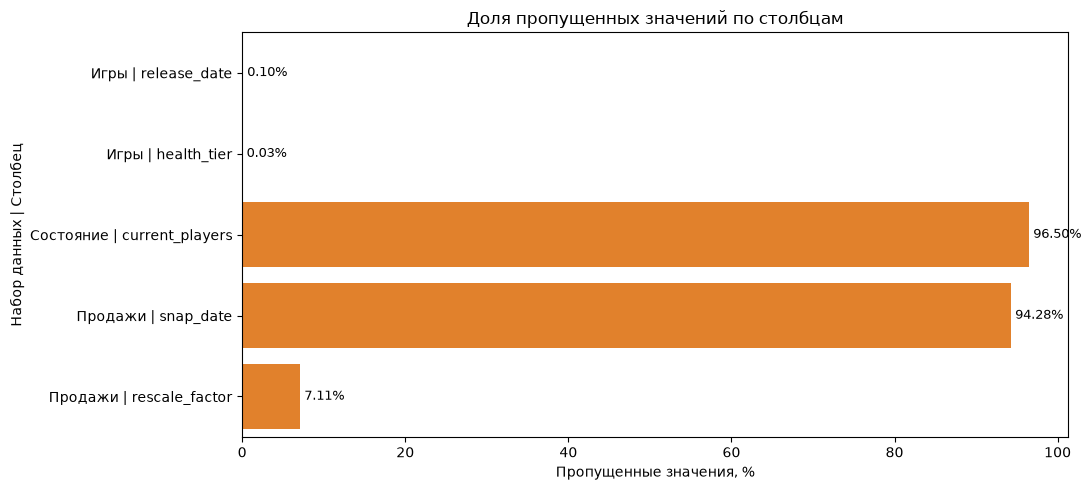

In [12]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Создаём список для результатов
missing_data = []

# Перебираем все наборы данных
for name, df in datasets.items():

    # Рассчитываем долю пропусков
    missing_pct = df.isna().mean() * 100

    # Сохраняем результаты
    for column, pct in missing_pct.items():
        missing_data.append({
            "dataset": name,
            "column": column,
            "missing_pct": pct
        })

# Преобразуем результаты в DataFrame
missing_df = pd.DataFrame(missing_data)

# Оставляем только столбцы с пропусками
missing_df = missing_df[missing_df["missing_pct"] > 0]

# Формируем подписи для графика
missing_df["label"] = (
    missing_df["dataset"] + " | " + missing_df["column"]
)

# Строим график
plt.figure(figsize=(11, 5))

sns.barplot(
    data=missing_df,
    x="missing_pct",
    y="label"
)

ax = sns.barplot(
    data=missing_df,
    x="missing_pct",
    y="label"
)

# Подписи значений
ax.bar_label(
    ax.containers[0],
    fmt="%.2f%%",
    padding=3,
    fontsize=9
)

plt.title("Доля пропущенных значений по столбцам")
plt.xlabel("Пропущенные значения, %")
plt.ylabel("Набор данных | Столбец")

plt.tight_layout()
plt.show()

__Анализ пропущенных значений__


Цель: оценить полноту исходных данных и выявить особенности распределения пропусков.

Методы: isna(), mean(), groupby(), визуализация средствами Seaborn.

Предварительные результаты:
* games — доля пропусков не превышает 0,10% по отдельным столбцам, приемлемо для базовой таблицы
* ccu — пропущенные значения отсутствуют.
* health — показатель current_players отсутствует в 96,5% записе - это плохо, часть аналитики отпадает.
* sales — показатель snap_date отсутствует в 94,28% записей - не критично. 

Предварительный вывод: наибольшие ограничения по полноте наблюдаются в таблицах health и sales. Перед использованием этих показателей необходимо определить причины пропусков. Удаление строк или заполнение значений без дополнительной проверки не обосновано.

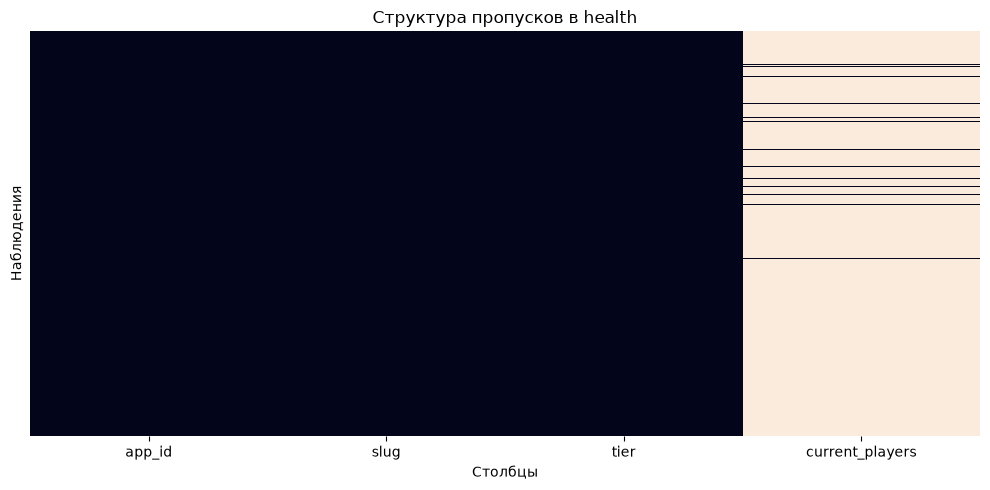

In [13]:
# Случайная выборка из 1000 строк
sample = health.sample(
    n=min(1000, len(health)),
    random_state=13
)

plt.figure(figsize=(10, 5))

sns.heatmap(
    sample.isna(),
    cbar=False,
    yticklabels=False
)

plt.title("Структура пропусков в health")
plt.xlabel("Столбцы")
plt.ylabel("Наблюдения")

plt.tight_layout()
plt.show()

Вывод: столбец current_players таблицы ccu имеет много недостающих значений. Соответственно использовать его для оценки данных будет проблематично и мы не будем их в дальнейшем использовать. 

In [14]:
# Проверим, как пропуски связаны с категориями игр в данных Health 
# Посмотрим на связь между пропусками в столбце current_players и tier (уровень активности)

tier_missing = (
    health
    .groupby("tier", dropna=False)
    .agg(
        total_games=("app_id", "count"),
        available_players=("current_players", "count")
    )
)

tier_missing["completeness_pct"] = (
tier_missing["available_players"] / tier_missing["total_games"] * 100
).round(2)

display(tier_missing)

,total_games,available_players,completeness_pct
tier,,,
cooling,975,43,4.41
dormant,662,7,1.06
healthy,3371,144,4.27
quiet,67269,2569,3.82
thriving,97,97,100.00
unknown,12470,110,0.88


Результаты анализа файла Health : 
* total_games — количество игр в категории.
* available_players — количество игр, для которых заполнено поле current_players.
* completeness_pct — доля заполненных значений в категории.

| Категория | Описание категории | Всего игр | Заполнено полей current_players | Заполненность ячеек, % | 
| --- | --- | --- | --- | --- | 
| cooling | Активно развивающиеся игры | 975 | 43 | 4,41% | 
| dormant | Игры с устойчивой активностью | 662	| 7 |	1,06%
| healthy | Игры со снижающейся активностью | 3 371 | 144 |	4,27%
| quiet | Игры с небольшой активностью | 67 269	| 2 569 | 3,82%
| thriving | Практически неактивные игры | 97 | 97 | 100%
| unknown | Состояние не определено | 12 470 | 110 |	0,88%



Есть не значительная связь между доступностью данных о текущем количестве игроков и категорией состояния игры (tier) - так в категории неактивные все пропуски и игры совпали. Пропуски распределены неравномерно между категориями. Следовательно удалять или очищать все сроки с пропущенными значениями нельзя, это может сказаться на выборке. 

Для первого этапа Steam Analytics нужно:
- tier сохранить как категориальный признак для описательного анализа.
- current_players пока исключить из расчёта основных рейтингов.
- Для оценки активности использовать max_players из ccu-daily-top2000.csv, но нужно проверить заполняемость данных.
- Не заполнять пропуски current_players нулями: отсутствие информации не означает отсутствие игроков.
- max_players — максимальное число одновременно активных игроков за день, а current_players — показатель текущего количества игроков на момент измерения. Они не взаимозаменяемы.




## Разведочный анализ данных ## 

In [15]:
# 1. Проверим типы данных в имеющихся таблицах
for name, df in datasets.items():
    print(f"\n=== {name} ===")
    display(df.dtypes)




=== Игры ===


app_id            int64
name                str
slug                str
release_date        str
is_free            bool
total_positive    int64
total_negative    int64
health_tier         str
dtype: object


=== Активность ===


app_id         int64
date             str
max_players    int64
dtype: object


=== Состояние ===


app_id               int64
slug                   str
tier                   str
current_players    float64
dtype: object


=== Продажи ===


app_id              int64
name                  str
slug                  str
release_date          str
era                   str
pc_only              bool
units               int64
units_sold_at         str
ref_url               str
reviews             int64
review_source         str
snap_date             str
rescale_factor    float64
ratio             float64
position              str
dtype: object

Важная заметка: 

Тип данных: 
- release_date   = str
- date   = str

После загрузки CSV даты нередко остаются строками. Это будет мешать при использовании данных столбцов для расчета дат. 

In [ ]:
# Преобразуем строковые значения в даты
games["release_date"] = pd.to_datetime(
    games["release_date"],
    errors="coerce"
)

ccu["date"] = pd.to_datetime(
    ccu["date"],
    errors="coerce"
)

# Проверяем результат по числу пропусков и типу данных - важно оценить как повлияли изменения на данные 
print(games["release_date"].dtype)
print(ccu["date"].dtype)

print("Пропусков release_date:", games["release_date"].isna().sum()) 
# Важно понять не изменилось число пропусков после изменения даты 
print("Пропусков date:", ccu["date"].isna().sum())
# Пропуски в date отсутствовали 

datetime64[us]
datetime64[us]
Пропусков release_date: 87
Пропусков date: 0


In [ ]:
# Проверим файлы на дубликаты все таблицы (ДУБЛИКАТЫ)

for name, df in datasets.items():
    print(
        name,
        "Полных дубликатов:",
        df.duplicated().sum()
    )

print("=" * 50)
print("Уникальных игр:", games["app_id"].nunique()) 
# Нужно также проверить повторения идентификаторов на всякий случай (рекомендация ИИ)
print("Всего строк:", len(games))

print("=" * 50)
print("Первая дата:", ccu["date"].min())
print("Последняя дата:", ccu["date"].max())

print("=" * 50)
print(
    "Количество дат в ссu:",
    ccu["date"].count()
)
print(
    "Количество дат в game [release_date]:",
    games["release_date"].count()
)
print(
    "Количество дат в sales [release_date]:",
    sales["release_date"].count()
)

Игры Полных дубликатов: 0
Активность Полных дубликатов: 0
Состояние Полных дубликатов: 0
Продажи Полных дубликатов: 0
Уникальных игр: 84843
Всего строк: 84843
Первая дата: 2026-08-06 00:00:00
Последняя дата: 2026-11-12 00:00:00
Количество дат в ссu: 189405
Количество дат в game [release_date]: 84756
Количество дат в sales [release_date]: 647


ВЫВОД: 

Проверка дубликатов: дубликатов во всех таблицах не выявлено. 
Число игр и идектификаторов совпало, значит дублей по играм нет. 

Итог: сохранить исходные данные без удаления строк. Для оценки исторической активности использовать max_players из таблицы ccu, а current_players не включать в основные расчёты до уточнения причин пропусков.

Провека дат на число значений для дальнейшего анализа. Очевидно, что в каждом датесете шфруются свои специфические даты. Надо выяснить с чем они связаны. 

In [ ]:
# Проведем стандартный разведочный анализ используя функцию .describe() к таблице ccu 
# Это предварительная проверка работоспособности функции и отображения данных
display(
    ccu["max_players"].describe()
)

count    1.894050e+05
mean     5.104002e+03
std      4.152382e+04
min      0.000000e+00
25%      1.410000e+02
50%      3.200000e+02
75%      1.095000e+03
max      1.450705e+06
Name: max_players, dtype: float64

In [ ]:
# Попробуем сделать разведочный анализ применив его ко всем таблицам
# В перспективе можно применить функцию def вместо цикла, но пока сделаем так
for name, df in datasets.items():
    print(f"\n===== {name} =====")

    display(
        df.describe(include="all").T
    )


===== Игры =====


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
app_id,84843.0,NaN,NaN,NaN,1977177.086807,10.0,937550.0,1793070.0,2884485.0,5475960.0,1234300.475762
name,84843,84413,Loop,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
slug,84843,84843,counter-strike-10,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
release_date,84756,NaN,NaN,NaN,2022-01-03 01:21:14.755769,1997-06-30 00:00:00,2019-06-29 18:00:00,2022-10-07 00:00:00,2025-01-19 00:00:00,2027-10-01 00:00:00,NaN
is_free,84843,2,False,68784,NaN,NaN,NaN,NaN,NaN,NaN,NaN
total_positive,84843.0,NaN,NaN,NaN,1851.368905,0.0,16.0,40.0,172.0,8554835.0,37839.372935
total_negative,84843.0,NaN,NaN,NaN,311.537522,0.0,4.0,11.0,43.0,1421486.0,7456.302116
health_tier,84816,6,quiet,67268,NaN,NaN,NaN,NaN,NaN,NaN,NaN



===== Активность =====


,count,mean,min,25%,50%,75%,max,std
app_id,189405.0,1124661.818511,10.0,410900.0,980610.0,1643320.0,5475960.0,838068.595813
date,189405,2026-09-24 16:11:24.248040,2026-08-06 00:00:00,2026-08-31 00:00:00,2026-09-25 00:00:00,2026-10-19 00:00:00,2026-11-12 00:00:00,NaN
max_players,189405.0,5104.001594,0.0,141.0,320.0,1095.0,1450705.0,41523.824583



===== Состояние =====


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
app_id,84844.0,NaN,NaN,NaN,1977212.160271,1234335.480516,10.0,937560.0,1793080.0,2884502.5,5475960.0
slug,84844,84844,counter-strike-10,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tier,84844,6,quiet,67269,NaN,NaN,NaN,NaN,NaN,NaN,NaN
current_players,2970.0,NaN,NaN,NaN,1835.693939,24539.483605,0.0,0.0,1.0,5.0,851846.0



===== Продажи =====


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
app_id,647.0,NaN,NaN,NaN,1542983.49459,1147760.63534,400.0,588970.0,1313140.0,2263265.0,4834070.0
name,647,647,Sid Meier's Civilization® IV,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
slug,647,647,sid-meier-s-civilization-iv-3900,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
release_date,647,570,2024-05-09,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
era,647,3,2020+,450,NaN,NaN,NaN,NaN,NaN,NaN,NaN
pc_only,647,2,False,491,NaN,NaN,NaN,NaN,NaN,NaN,NaN
units,647.0,NaN,NaN,NaN,4095139.993818,12287411.667337,1000.0,300000.0,1000000.0,3000000.0,225000000.0
units_sold_at,647,473,2025-09-30,23,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ref_url,647,580,https://www.gematsu.com/2025/11/capcom-platinu...,22,NaN,NaN,NaN,NaN,NaN,NaN,NaN
reviews,647.0,NaN,NaN,NaN,57248.820711,167127.640364,51.0,3182.0,10984.0,36671.0,2033872.0


Важные заметки по разведочному анализа 
1)	Таблица game-index
* В столбце release_date формат данных следующий 2019-06-29 18:00:00 
* Столбец is_free действительно имеет болевое распределение 
* Столбцы позитивные и негативные отзывы имеют 84843 ячейки – все ячейки.  
* Столбец health_tier имеет 84816 значений 

2)	Таблица ccu 
* Имеется множество записей 189 405 шт .
* Столбец   max_players     важные замечания: среднее число максимальных пользователей – 5104, медианное значение – 320, максимальное – 1 450 705, стандартное отклонение 41 523. 

3)	Таблица Health
* Столбец tier имеет 6 позиций. 

4)	Таблица Sales 
* Era – имеет 3 позиции 
* Столбец units важные замечания (число продаж): среднее число– 4 095 140, минимум – 1000, медианное значение – 1 000 000, максимальное – 225 000 000, стандартное отклонение 12 287 411. 
* Столбец reviews – Среднее 57 249 отзывов, стандартное отклонение – 167 127, минимум – 51, медиана 10984, максимум – 2 033 872
* rescale_factor 	Среднее 1,1943, стандартное отклонение – 0,1401, минимум – 0,7963, медиана 1,1639, максимум – 1,6301
* ratio	Среднее 1,1943 отзывов, стандартное отклонение – 4327, минимум – 5,194, медиана 69,3838, максимум 101449,27



In [ ]:
# Проверим число доступных уникальных игры по id и доступный дат наблюдений 
# Параллельно проверим сочетания id + дата на совпадения (совет ИИ, на случай дубликатов данных)

print("Уникальных игр:", ccu["app_id"].nunique())

print("Уникальных дат:", ccu["date"].nunique())

print(
    "Повторяющихся сочетаний app_id + date:",
    ccu.duplicated(subset=["app_id", "date"]).sum()
)

days_per_game = (
    ccu.groupby("app_id")["date"]
    .nunique()
)

display(days_per_game.describe())

Уникальных игр: 2000
Уникальных дат: 99
Повторяющихся сочетаний app_id + date: 0


count    2000.000000
mean       94.702500
std        16.496304
min         1.000000
25%        98.000000
50%        99.000000
75%        99.000000
max        99.000000
Name: date, dtype: float64

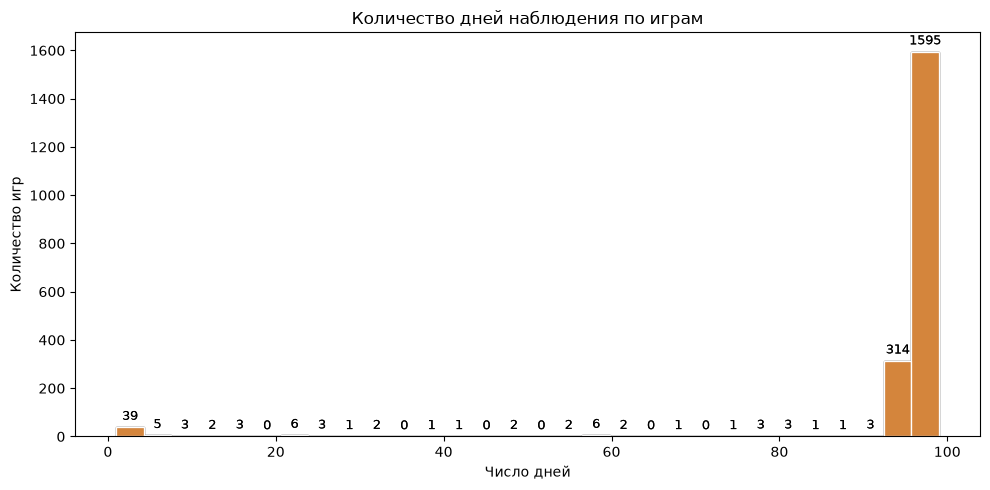

In [ ]:
# Распределение игр по числу наблюдений 

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.histplot(
    days_per_game,
    bins=30
)
# Подписи осей 
ax = sns.histplot(
    days_per_game,
    bins=30,
    edgecolor="white"
)

# Подписываем количество игр над столбцами
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%d",
        padding=3,
        fontsize=9
    )

plt.title("Количество дней наблюдения по играм")
plt.xlabel("Число дней")
plt.ylabel("Количество игр")

plt.tight_layout()
plt.show()

Диаграмма получилась слишком перегруженной, но в целом отражает динамику того, что большая часть из 2000 игр имеет наблюдения 93-99 дней, что дает достаточный набор данных. Но есть часть игр, которые имеют меньшее число наблюдений

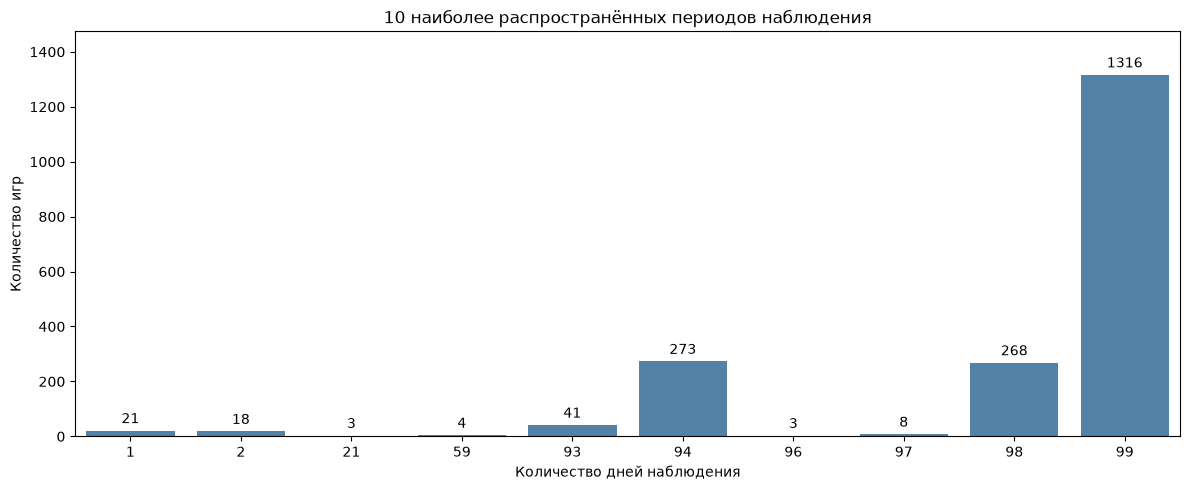

In [ ]:
# Чуть переделаем график и выделим на нем, только значимые наблюдения


# Считаем количество игр для каждого числа дней
days_counts = (
    days_per_game
    .value_counts()
    .sort_values(ascending=False)
    .head(10)
    .sort_index()
)
# Визуализируем график 
plt.figure(figsize=(12, 5))

ax = sns.barplot(
    x=days_counts.index,
    y=days_counts.values,
    color="steelblue"
)

# Добавляем подписи
for container in ax.containers:
    ax.bar_label(container, fmt="%d", padding=3)

plt.title("10 наиболее распространённых периодов наблюдения")
plt.xlabel("Количество дней наблюдения")
plt.ylabel("Количество игр")
plt.ylim(0, max(days_counts.values) * 1.12)

plt.tight_layout()
plt.show()


В целом выборка достаточная. чтобы сделать значимые заключения. Соответственно 1316 игр наблюдались 99 дней, 268 игр - 98 дней, 273 игры - 94 дня, 41 игра наблюдались 93 дня, а остальные игры до 21 шт наблюдались в различные периоды.

Таким образом, сформированный набор данных обладает высокой полнотой временных рядов и пригоден для дальнейшего анализа динамики пользовательской активности: 
* Среднее количество дней наблюдения — 94,7.
* Медианное количество дней — 99.
* Максимальное количество дней — 99.

In [ ]:
# Агрегируем активность по играм

# Агрегируем ежедневную статистику игроков Steam и формирует сводную таблицу, 
# в которой каждой игре соответствует одна строка.

game_activity = (                               # Собираем данные в один ДатаСет 
    ccu.groupby("app_id")                       # Группируем данные по id игры 
    .agg(
        mean_ccu=("max_players", "mean"),       # Среднее значение максимального значения игроков в ссu
        median_ccu=("max_players", "median"),   # Медиана 
        peak_ccu=("max_players", "max"),        # Максимум - пик нагрузки 
        observed_days=("date", "nunique")       # Число дней наблюдения 
    )
    .reset_index()
)

game_activity = game_activity.merge(            # Присоединим названия игр последним столбцом 
    games[["app_id", "name"]],
    on="app_id",
    how="left",
    validate="one_to_one"
)

display(game_activity.head())                   # Получим следующую таблицу 



,app_id,mean_ccu,median_ccu,peak_ccu,observed_days,name
0,10,9706.030303,9742.0,13509,99,Counter-Strike
1,50,100.676768,100.0,183,99,Half-Life: Opposing Force
2,70,791.161616,799.0,1404,99,Half-Life
3,80,394.949495,416.0,588,99,Counter-Strike: Condition Zero
4,220,1647.949495,1662.0,2549,99,Half-Life 2


In [ ]:
# рассчитаем полноту наблюдений 

total_days = ccu["date"].nunique()

game_activity["coverage_pct"] = (       # Доля наблюдаемых дней для каждой игры относительно полного периода исследования (100 дней)
    game_activity["observed_days"]
    / total_days
    * 100
).round(2)

# Построим ТОП-100 игр для анализа 
top100 = (
    game_activity[
        game_activity["observed_days"] >= 90        # Фильтр на полноту наблюдений более 90 дней для включения в ТОП-100 игр
    ]
    .sort_values(
        "mean_ccu",
        ascending=False
    )
    .head(100)
    .reset_index(drop=True)
)

display(                                # ТОП-100 соответствуют необходимым данным по наполняемости и достаточности 
    top100[
        [
            "name",
            "mean_ccu",
            "median_ccu",
            "peak_ccu",
            "observed_days",
            "coverage_pct"
        ]
    ]
)

# ВАЖНО: этот список представляет собой ТОП-100 по среднему ежедневному пиковому CCU среди игр с покрытием не менее 90 дней, 
# а не абсолютный ТОП-100 Steam за всё время.

,name,mean_ccu,median_ccu,peak_ccu,observed_days,coverage_pct
0,Counter-Strike 2,1.238948e+06,1240760.0,1450705,99,100.0
1,Dota 2,8.557898e+05,847552.0,1096364,99,100.0
2,PUBG: BATTLEGROUNDS,7.340374e+05,735738.0,816367,99,100.0
3,Apex Legends™,2.423776e+05,250670.0,290755,99,100.0
4,Bongo Cat,1.664485e+05,164019.0,193612,99,100.0
...,...,...,...,...,...,...
95,Kingdom Come: Deliverance II,1.410318e+04,13939.0,24383,99,100.0
96,Sid Meier's Civilization® V,1.405687e+04,14271.0,19089,99,100.0
97,Brawlhalla,1.373533e+04,13529.0,16858,99,100.0
98,S.T.A.L.K.E.R. 2: Heart of Chornobyl,1.360077e+04,9892.0,40937,99,100.0


In [ ]:
# Дополнительные данные для вывода по показателям ТОП-100
print("Количество игр:", len(top100))
print(
    "Среднее покрытие:",
    round(top100["coverage_pct"].mean(), 2), "%"
)
print(
    "Минимальное покрытие:",
    top100["coverage_pct"].min(), "%"
)
print(
    "Игр со 100% покрытием:",
    (top100["coverage_pct"] == 100).sum()
)
print(
    "Медиана среднего CCU:",
    round(top100["mean_ccu"].median())
)
print(
    "Максимальный средний CCU:",
    round(top100["mean_ccu"].max())
)
print(
    "Минимальный средний CCU:",
    round(top100["mean_ccu"].min())
)

Количество игр: 100
Среднее покрытие: 99.82 %
Минимальное покрытие: 93.94 %
Игр со 100% покрытием: 97
Медиана среднего CCU: 35836
Максимальный средний CCU: 1238948
Минимальный средний CCU: 13386


Особенность данных списка: этот список представляет собой ТОП-100 по среднему ежедневному пиковому CCU среди игр с покрытием не менее 90 дней, а не абсолютный ТОП-100 Steam за всё время. Аналогично мы будем ранжировать потом другие игры списка. 

__Вывод по ТОП-100 игр__ 

На основе агрегированных данных пользовательской активности сформирована выборка 100 игр Steam с наибольшими значениями среднего ежедневного максимального онлайна при наличии не менее 90 дней наблюдений из 99. 
Анализ выявил существенную дифференциацию популярности: лидирующие позиции занимают Counter-Strike 2, Dota 2 и PUBG: BATTLEGROUNDS, значительно превосходящие последующие игры по уровню активности. 

Общие цифровые заметки: 
* 97 игр имеют наблюдения за все 99 дней.
* Только 3 игры имеют неполные временные ряды.
* Минимальное покрытие составляет 93,94%, то есть даже наиболее неполная игра наблюдалась 93 дня из 99.
* Среднее покрытие 99,82% свидетельствует о незначительном количестве пропущенных наблюдений.

Анализ пользовательской активности выявил существенную дифференциацию популярности игр: средний ежедневный максимальный онлайн варьируется от 13 386 до 1 238 948 пользователей, а медианное значение составляет 35 836. Различие между крайними значениями достигает 92,6 раза. Полученные результаты подтверждают пригодность выборки для сравнительного анализа игровой активности с учётом различий в масштабе пользовательской аудитории.

In [27]:
top100.head(10)

,app_id,mean_ccu,median_ccu,peak_ccu,observed_days,name,coverage_pct
0,730,1.238948e+06,1240760.0,1450705,99,Counter-Strike 2,100.0
1,570,8.557898e+05,847552.0,1096364,99,Dota 2,100.0
2,578080,7.340374e+05,735738.0,816367,99,PUBG: BATTLEGROUNDS,100.0
3,1172470,2.423776e+05,250670.0,290755,99,Apex Legends™,100.0
4,3419430,1.664485e+05,164019.0,193612,99,Bongo Cat,100.0
5,252490,1.248069e+05,124449.0,197931,99,Rust,100.0
6,1623730,1.227827e+05,78646.0,417043,99,Palworld,100.0
7,2507950,1.214686e+05,121289.0,147031,99,Delta Force,100.0
8,431960,1.106490e+05,110602.0,126084,99,Wallpaper Engine,100.0
9,892970,1.081761e+05,92424.0,308360,99,Valheim,100.0


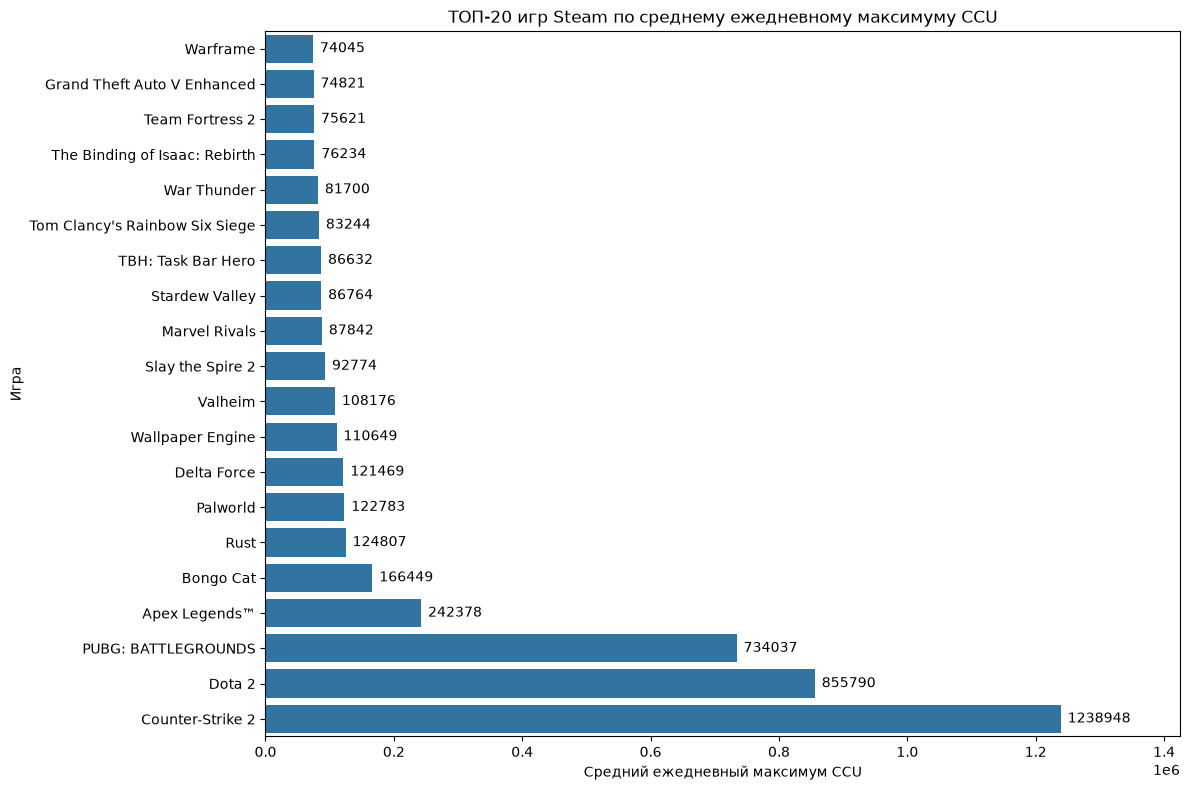

In [96]:

top20 = top100.head(20).sort_values("mean_ccu")

plt.figure(figsize=(12, 8))

ax = sns.barplot(
    data=top20,
    x="mean_ccu",
    y="name"
)

# Добавляем значения справа от столбцов
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.0f",
        padding=5,
        fontsize=10
    )

# Добавляем пространство для подписей
ax.set_xlim(0, top20["mean_ccu"].max() * 1.15)

plt.title("ТОП-20 игр Steam по среднему ежедневному максимуму CCU")
plt.xlabel("Средний ежедневный максимум CCU")
plt.ylabel("Игра")

plt.tight_layout()
plt.show()


__Вывод__

Есть явно выраженная тройка лидеров игр с максимом более 700 тысяч игроков и десятка лидеров с максимум в 100 тысяч игроков. 

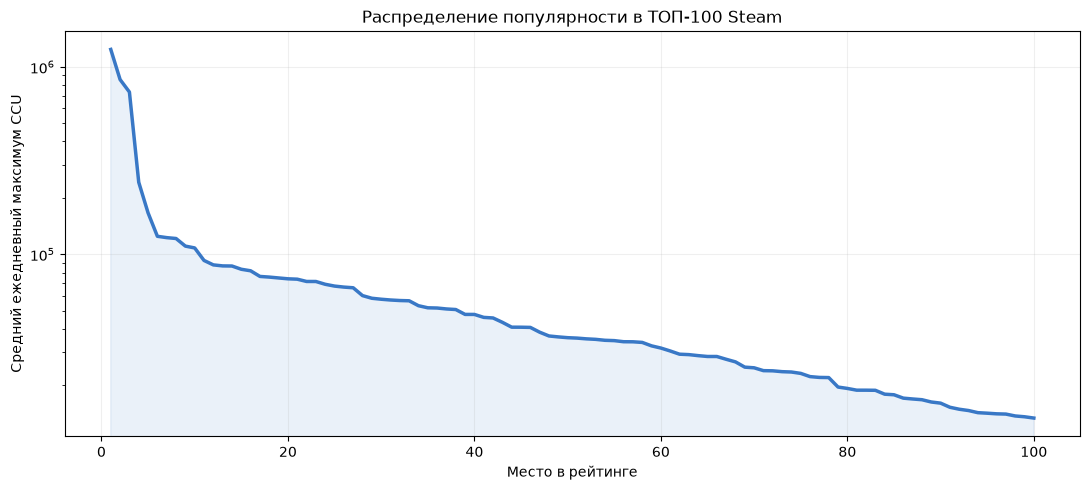

In [ ]:
# ТОП-100 — насколько сильно различается популярность
# Посмотрим насколько сильно различается пользовательская активность между лидерами рейтинга и остальными играми 
# Построим для этого кривую распределения 

import matplotlib.pyplot as plt
import numpy as np

ranking = top100.sort_values(                           # Сортирует игры по убыванию среднего ежедневного максимального CCU
    "mean_ccu", ascending=False
).reset_index(drop=True).copy()                         # Создаёт новую последовательную индексацию от 0 до 99 и делаем копию дата фарейма 

ranking["rank"] = np.arange(1, len(ranking) + 1)        # Создаем последовательность цифр рейтинга по списку +1

fig, ax = plt.subplots(figsize=(11, 5))                 # Строим график 

ax.plot(                                                # настрока оси Х
    ranking["rank"],
    ranking["mean_ccu"],
    linewidth=2.5,
    color="#3978C6"
)

ax.fill_between(
    ranking["rank"],
    ranking["mean_ccu"],
    alpha=0.10,
    color="#3978C6"
)

# Логарифмическая шкала позволяет лучше увидеть относительные различия между играми
ax.set_yscale("log")                                   # Убирает CS с 1,4 млн. пользователей, делая восприятие более приятными по другим играм

ax.set_title("Распределение популярности в ТОП-100 Steam")
ax.set_xlabel("Место в рейтинге")
ax.set_ylabel("Средний ежедневный максимум CCU")
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

__Вывод__

Анализ распределения среднего ежедневного максимального количества одновременно активных пользователей в ТОП-100 игр Steam выявил существенную неоднородность пользовательской активности. Наиболее высокие показатели сосредоточены у лидеров рейтинга, тогда как последующие позиции характеризуются значительно меньшими значениями CCU. Разница между максимальным и минимальным показателями составляет около 92,6 раза, а медианное значение равно 35 836 пользователей. Полученные результаты указывают на выраженную дифференциацию популярности игр и необходимость учитывать масштаб пользовательской аудитории при дальнейшем сравнительном анализе игровых механик.

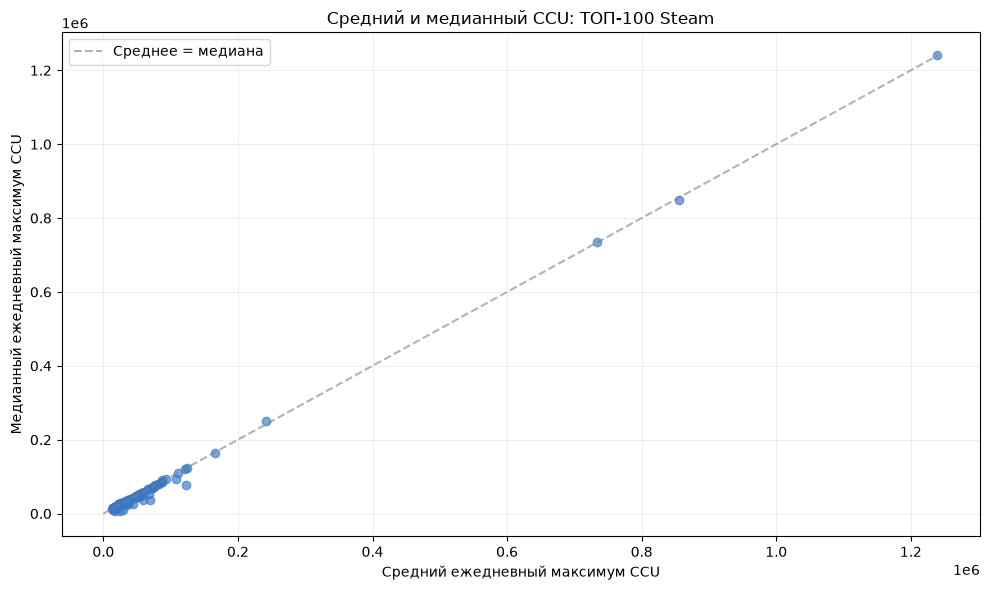

In [ ]:
# ТОП-100 — насколько стабильна аудитория
# Построим диаграмму рассеяния (Scatter Plot), которая позволяет сравнить среднее и медианное значения 
# ежедневного максимального онлайна для 100 наиболее популярных игр Steam.


fig, ax = plt.subplots(figsize=(10, 6))

ax.scatter(                         # Строим диаграмму рассеивания 
    top100["mean_ccu"],             # Среднее значение по оси Х
    top100["median_ccu"],           # Медианное значение по оси Y 
    alpha=0.65,
    color="#3978C6"
)

max_ccu = max(
    top100["mean_ccu"].max(),
    top100["median_ccu"].max()
)

ax.plot(                            # Строим линию
    [0, max_ccu],
    [0, max_ccu],
    linestyle="--",
    color="gray",
    alpha=0.6,
    label="Среднее = медиана"
)

ax.set_title("Средний и медианный CCU: ТОП-100 Steam")      # Подписи значений 
ax.set_xlabel("Средний ежедневный максимум CCU")
ax.set_ylabel("Медианный ежедневный максимум CCU")
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

__Вывод__

Интерпретация положения точек:
- На линии: среднее и медиана совпадают.
- Ниже линии: среднее больше медианы. Возможно влияние отдельных высоких значений.
- Выше линии: медиана больше среднего. Возможно влияние отдельных низких значений.

Наблюдение 1. Для Counter-Strike 2, Dota 2 и PUBG (тройка лидеров) среднее и медиана отличаются менее чем на 1%. Это показывает, что их средние значения не сильно смещены относительно медианных.
Наблюдение 2. Для S.T.A.L.K.E.R. 2 среднее выше медианы примерно на 40%. Это может быть связано с отдельными днями повышенной активности, например после обновлений или игровых событий. Однако установить причину по двум агрегированным показателям нельзя.
Наблюдение 3. У игр с относительно небольшим онлайнoм точки будут сгруппированы около начала координат, потому что масштаб осей определяется играми-миллионниками. Это затрудняет визуальное сравнение.

## API запросы к серверу и дополнение Dataset 
 
 Дополним данные дополнительным набором добавив значения через онлайн с серверов Steam напрямую через API
 Сначало посмотрим на структуру получаемых данных через API 
 Особенности подключения взяты по ранее приведенной ссылке

In [ ]:
# Загрузим пробные данные по CS под номером id=730
# HTTP-запрос к Steam Store API
import requests                                         # Python-библиотека для выполнения HTTP-запросов к сайтам и API.

url = "https://store.steampowered.com/api/appdetails"   # Ресурс для подключения 

params = {                                              # Параметры запроса к серверу по игре 730
    "appids": 730,
    "l": "english",                                     # Язык запроса 
    "cc": "us"                                          # Данные по региону США
}

response = requests.get(                                # Функция непосредственной отправки HTTP-запроса 
    url,
    params=params,
    timeout=15                                          # Ожидание (задержка в 15 сек)
)

response.raise_for_status()                             # Проверка возможной ошибки 

result = response.json()                                # Метод .json() преобразует JSON-ответ в соответствующие объекты Python, обычно словари и списки.
# Тут было несколько исправлений кода, т.к. данные получали, либо с ошибкой, либо не полностью
# Методом проб и ошибок был получен этот код по выгрузке 
game = result["730"]                                    # Проверяем соответствует ли полученный результат идентификатора тому что нашем Дата Фрейме

if game.get("success"):                                 # Провека успешности полученных данных 
    details = game["data"]

    print("Название:", details.get("name"))             # Печатаем результаты 
    print("Тип:", details.get("type"))
    print("Жанры:", details.get("genres"))
    print("Категории:", details.get("categories"))
else:
    print("Steam не вернул данные об игре")


Название: Counter-Strike 2
Тип: game
Жанры: [{'id': '1', 'description': 'Action'}, {'id': '37', 'description': 'Free To Play'}]
Категории: [{'id': 1, 'description': 'Multi-player'}, {'id': 27, 'description': 'Cross-Platform Multiplayer'}, {'id': 29, 'description': 'Steam Trading Cards'}, {'id': 51, 'description': 'Steam Workshop'}, {'id': 30, 'description': 'Steam Workshop'}, {'id': 35, 'description': 'In-App Purchases'}, {'id': 64, 'description': 'Adjustable Text Size'}, {'id': 67, 'description': 'Camera Comfort'}, {'id': 66, 'description': 'Color Alternatives'}, {'id': 68, 'description': 'Custom Volume Controls'}, {'id': 74, 'description': 'Playable without Timed Input'}, {'id': 69, 'description': 'Stereo Sound'}, {'id': 70, 'description': 'Surround Sound'}, {'id': 8, 'description': 'Valve Anti-Cheat enabled'}, {'id': 15, 'description': 'Stats'}, {'id': 41, 'description': 'Remote Play on Phone'}, {'id': 42, 'description': 'Remote Play on Tablet'}, {'id': 43, 'description': 'Remote Pl

__Выводы по полученным данным__

Steam API возвращает данные в формате JSON, а библиотека requests преобразует их в словарь Python (dict).
Таким образом, и жанры, и категории представлены списками словарей.

БД genres содержит данные о жанре и у CS оказывается есть 2 типа данных жанра:  
- Action -  id 1
- Free To Play - id 37

БД categories содержит сведения тоже по нескольким категориям, на примере CS это: 
| id категории | Название из БД | Пояснение 
| --- | --- | --- | 
| 1 | Multi-player | Многопользовательский режим
| 27 |  Cross-Platform Multiplayer | Кроссплатформенный мультиплеер
| 29 | Steam Trading Cards | Торговые карточки Steam
| 51 | Steam Workshop (№51) |  Мастерская Steam
| 30 | Steam Workshop (№30) | Мастерская Steam
| 35 | In-App Purchases | Покупки в приложении
| 64 | Adjustable Text Size | Возможность изменять размер текста
| 67 | Camera Comfort | Удобство работы с камерой
| 66 | Color Alternatives | Варианты цветов
| 68 | Custom Volume Controls | Настраиваемые регуляторы громкости
| 74 | Playable without Timed Input | Возможность воспроизведения без предварительного ввода
| 69 |  Stereo Sound | Стереозвук 
| 70 | Surround Sound | Объемный звук
| 8 | Valve Anti-Cheat enabled | Защита от читов Valve включена 
| 15 | Stats | Статистика 
| 41 | Remote Play on Phone | Удаленное воспроизведение на телефоне
| 42 | Remote Play on Tablet | Удаленное воспроизведение на планшете
| 43 | Remote Play on TV | Удаленное воспроизведение на телевизоре
| 63 | Steam Timeline | Временная шкала Steam

Очевидно что категорий много и нужно будет лишние категории не относящиеся с исследователькой части геймификации удалять + надо выяснить характеристики других категорий и понять что кроется за данным описанием категорий (конкретные требования, параметры и т.д.)


In [ ]:
import sys                              # Устанавливаем библиотеку sys для управления файлами - перенесена в начало 
import duckdb                           # Установка библиотеке по работе с БД - перенес в начало 

print("Python:", sys.executable)
print("DuckDB:", duckdb.__version__)

Python: C:\Users\truni\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe
DuckDB: 2.0.0


## Создаем базу данных DuckDB

Используя библиотеку duckdb создали БД и указываем путь к ней. 

In [ ]:
# Создаем файл базы данных 

# Папка для базы данных
# Важно: эта строка пока не создаёт папку на диске, а только описывает путь к ней.
# Поскольку путь относительный, он отсчитывается от текущей рабочей директории Python.
# База данных: C:\Users\truni\OneDrive\Рабочий стол\LifeStyle\_Иннополис\_1 - Attestation\data\database\steam_analytics.duckdb

db_dir = Path("data/database")                  # Указываем папку для БД 
db_dir.mkdir(parents=True, exist_ok=True)       # Метод .mkdir() создаёт директорию

# Формируем путь к файлу базы данных - это эквивалентно db_path = Path("data/database/steam_analytics.duckdb")
db_path = db_dir / "steam_analytics.duckdb"

# Подключаемся к DuckDB
con = duckdb.connect(str(db_path))              # .connect Открывает соединение с базой и Преобразует объект Path в строку (str) и записываем все в переменную con

print("База данных:", db_path.resolve())

База данных: C:\Users\truni\OneDrive\Рабочий стол\LifeStyle\_Иннополис\_1 - Attestation\data\database\steam_analytics.duckdb


## Создаем SQL-запросы 

Создаем таблицы в нашей БД, используя SQL-запросы для переноса данных 

In [ ]:
# Регистрируем DataFrame в DuckDB
# Переносим четыре набора данных из Pandas в базу данных DuckDB. Метод con.register() регистрирует существующий DataFrame под определённым именем в текущем соединении DuckDB.
con.register("df_games", games)         # con — соединение с базой DuckDB.
con.register("df_ccu", ccu)             # .register() — метод регистрации объекта Python.
con.register("df_health", health)       # df_games \ df_ccu \ df_health \ df_sales — имена, под которыми DuckDB будет видеть DataFrame
con.register("df_sales", sales)         # games \ ccu \ health \ sales — существующая переменная Pandas с данными об играх.
# Важно: register() не создаёт постоянную таблицу и не копирует весь DataFrame в файл базы данных. 
# Он делает данные доступными для SQL-запросов в рамках соединения.

# Создаём или заменяем существующую таблицу (если есть) и даем новое название games. Потом выбрать все столбцы и получить данные из зарегистрированного DataFrame df_games
con.execute("""
    CREATE OR REPLACE TABLE games AS 
    SELECT * FROM df_games
""")

con.execute("""
    CREATE OR REPLACE TABLE ccu_daily AS
    SELECT * FROM df_ccu
""")

con.execute("""
    CREATE OR REPLACE TABLE health AS
    SELECT * FROM df_health
""")

con.execute("""
    CREATE OR REPLACE TABLE sales AS
    SELECT * FROM df_sales
""")

print("Все четыре таблицы созданы!")

Все четыре таблицы созданы!


| DataFrame Python | Зарегистрированное имя |	Таблица DuckDB
| --- | --- | --- | 
| games | df_games | games
| ccu | df_ccu |	ccu_daily
| health |	df_health |	health
| sales |	df_sales |	sales

Зарегистрированный DataFrame доступен через текущее соединение и зависит от существующего объекта Python.
Физическая таблица сохраняется в файле базы данных и может использоваться после перезапуска Jupyter и повторного подключения к DuckDB.

In [35]:
# Проверяем таблицы 
con.sql("""
    SHOW TABLES
""").df()

,name
0,ccu_daily
1,df_ccu
2,df_games
3,df_health
4,df_sales
5,games
6,health
7,sales


__Данные DuckDB__

С учётом структуры нашего проекта:

| Таблица | Основные данные в таблице  | Справка |
| --- | --- | --- |
| games |	app_id, name, release_date, отзывы | 	Справочник игр
| ccu_daily |	app_id, date, max_players |	Анализ пользовательской активности
| health |	app_id, tier, current_players |	Дополнительные показатели состояния игр
| sales |	app_id, units, reviews и другие| Анализ и калибровка оценок продаж

ВАЖНО: таблица sales содержит отдельную выборку с данными о продажах и не обязательно охватывает все 2000 игр.

In [ ]:
# Проверим количество строк в нашей БД и сравним с первичными результатом. 
# P.S. - данные перенесены корректно

con.sql("""
    SELECT
        'games' AS table_name,
        COUNT(*) AS row_count
    FROM games

    UNION ALL

    SELECT
        'ccu_daily',
        COUNT(*)
    FROM ccu_daily

    UNION ALL

    SELECT
        'health',
        COUNT(*)
    FROM health

    UNION ALL

    SELECT
        'sales',
        COUNT(*)
    FROM sales
""").df()

,table_name,row_count
0,games,84843
1,ccu_daily,189405
2,health,84844
3,sales,647


In [ ]:
# Создаём первое SQL VIEW. Собираем таблицу в общую таблицу! 
# Создаем представление vw_game_activity

con.execute("""
    CREATE OR REPLACE VIEW vw_game_activity AS

    SELECT
        c.app_id,
        g.name,

        AVG(c.max_players) AS mean_ccu,
        MEDIAN(c.max_players) AS median_ccu,
        MAX(c.max_players) AS peak_ccu,

        COUNT(DISTINCT c.date) AS observed_days

    FROM ccu_daily AS c

    LEFT JOIN games AS g
        ON c.app_id = g.app_id

    GROUP BY
        c.app_id,
        g.name
""")

In [ ]:
# Посмотрим результат представление vw_game_activity и выведем результат 

con.sql("""
    SELECT *
    FROM vw_game_activity
    ORDER BY mean_ccu DESC
    LIMIT 10
""").df()

,app_id,name,mean_ccu,median_ccu,peak_ccu,observed_days
0,730,Counter-Strike 2,1.238948e+06,1240760.0,1450705,99
1,570,Dota 2,8.557898e+05,847552.0,1096364,99
2,578080,PUBG: BATTLEGROUNDS,7.340374e+05,735738.0,816367,99
3,4115450,Phantom Blade Zero,6.117846e+05,606065.0,832967,14
4,3393110,AION 2,2.615349e+05,243554.0,397356,39
5,1172470,Apex Legends™,2.423776e+05,250670.0,290755,99
6,1867240,WARDOGS,2.192442e+05,199487.0,428219,63
7,4262460,ROB RUN,1.733316e+05,150970.0,290876,7
8,3419430,Bongo Cat,1.664485e+05,164019.0,193612,99
9,4348910,Probably Stolen - Cyberpunk Shopkeeper Sim,1.565453e+05,160740.0,185807,15


In [ ]:
# Создаем ТОП-100 через SQL по аналогичной методологии группировки как в Pandas, используя за основу DuckDB
# Выведем результат

top100_sql = con.sql("""
    SELECT
        app_id,
        name,
        ROUND(mean_ccu, 2) AS mean_ccu,
        median_ccu,
        peak_ccu,
        observed_days

    FROM vw_game_activity

    WHERE observed_days >= 90

    ORDER BY mean_ccu DESC

    LIMIT 100
""").df()

display(top100_sql.head(10))

,app_id,name,mean_ccu,median_ccu,peak_ccu,observed_days
0,730,Counter-Strike 2,1238948.45,1240760.0,1450705,99
1,570,Dota 2,855789.77,847552.0,1096364,99
2,578080,PUBG: BATTLEGROUNDS,734037.35,735738.0,816367,99
3,1172470,Apex Legends™,242377.59,250670.0,290755,99
4,3419430,Bongo Cat,166448.55,164019.0,193612,99
5,252490,Rust,124806.94,124449.0,197931,99
6,1623730,Palworld,122782.67,78646.0,417043,99
7,2507950,Delta Force,121468.57,121289.0,147031,99
8,431960,Wallpaper Engine,110649.04,110602.0,126084,99
9,892970,Valheim,108176.11,92424.0,308360,99


In [ ]:
# Проверим, совпадают ли результаты Pandas и SQL в DuckDB

# Сравниваем идентификаторы и порядок игр используя булевую переменную для простоты и скорости сравнения 
same_ids = (
    top100["app_id"].tolist()
    == top100_sql["app_id"].tolist()
)

print("Порядок игр совпадает:", same_ids)

Порядок игр совпадает: True


__ВЫВОД__

Результаты переноса данных в БД и сборка в Pandas оказались идентичными. Можно продолжать работу и дополнительная коррекция и правки не требуются. 

In [ ]:
# ЭКСПЕРИМЕНТ - Первый практический эксперимент: получаем данные одной игры
# Код копируем для вывода результатов, чтобы понять какие поля скопировать и настроить копирование данных с сервера 

import requests

url = "https://store.steampowered.com/api/appdetails"

params = {
    "appids": 730,
    "l": "english",
    "cc": "us"
}

response = requests.get(
    url,
    params=params,
    timeout=15
)

response.raise_for_status()

result = response.json()

game = result["730"]

if game.get("success"):
    details = game["data"]

    print("Название:", details.get("name"))
    print("Тип:", details.get("type"))
    print("Жанры:", details.get("genres"))
    print("Категории:", details.get("categories"))
else:
    print("Steam не вернул данные об игре")


Название: Counter-Strike 2
Тип: game
Жанры: [{'id': '1', 'description': 'Action'}, {'id': '37', 'description': 'Free To Play'}]
Категории: [{'id': 1, 'description': 'Multi-player'}, {'id': 27, 'description': 'Cross-Platform Multiplayer'}, {'id': 29, 'description': 'Steam Trading Cards'}, {'id': 51, 'description': 'Steam Workshop'}, {'id': 30, 'description': 'Steam Workshop'}, {'id': 35, 'description': 'In-App Purchases'}, {'id': 64, 'description': 'Adjustable Text Size'}, {'id': 67, 'description': 'Camera Comfort'}, {'id': 66, 'description': 'Color Alternatives'}, {'id': 68, 'description': 'Custom Volume Controls'}, {'id': 74, 'description': 'Playable without Timed Input'}, {'id': 69, 'description': 'Stereo Sound'}, {'id': 70, 'description': 'Surround Sound'}, {'id': 8, 'description': 'Valve Anti-Cheat enabled'}, {'id': 15, 'description': 'Stats'}, {'id': 41, 'description': 'Remote Play on Phone'}, {'id': 42, 'description': 'Remote Play on Tablet'}, {'id': 43, 'description': 'Remote Pl

In [ ]:
# Эта часть кода переделывалась несколько раз, т.к. были ошибки при копировании.
# 
# Сохраним результат в DuckDB

api_game = pd.DataFrame([{
    "app_id": 730,
    "api_name": details.get("name"),
    "app_type": details.get("type"),
    "genres": ", ".join(
        x["description"]
        for x in details.get("genres", [])
    ),
    "categories": ", ".join(
        x["description"]
        for x in details.get("categories", [])
    ),
    "short_description": details.get("short_description")
}])

con.register("api_game_df", api_game)

con.execute("""
    CREATE OR REPLACE TABLE steam_app_details AS
    SELECT * FROM api_game_df
""")

In [43]:
# Создаём расширенное аналитическое VIEW
con.execute("""
CREATE OR REPLACE VIEW vw_game_analytics AS

SELECT
    a.app_id,
    a.name,
    a.mean_ccu,
    a.median_ccu,
    a.peak_ccu,
    a.observed_days,

    d.app_type,
    d.genres,
    d.categories,
    d.short_description

FROM vw_game_activity AS a

LEFT JOIN steam_app_details AS d
    ON a.app_id = d.app_id;
    
""")

In [44]:
# Проверим полученное представление 
df = con.execute("""
SELECT *
FROM vw_game_analytics
LIMIT 10
""").df()

display(df)

,app_id,name,mean_ccu,median_ccu,peak_ccu,observed_days,app_type,genres,categories,short_description
0,1324780,Easy Red 2,1055.071429,951.0,2557,98,None,None,None,None
1,1369320,Virtual Cottage,110.255102,108.5,145,98,None,None,None,None
2,1369630,ENDER LILIES: Quietus of the Knights,227.606061,213.0,517,99,None,None,None,None
3,1369670,Motor Town: Behind The Wheel,669.846939,628.5,1405,98,None,None,None,None
4,1442430,Storage Hunter Simulator,239.978723,209.0,607,94,None,None,None,None
5,1450900,Desynced,91.585106,88.0,202,94,None,None,None,None
6,1451940,NEEDY GIRL OVERDOSE,317.939394,293.0,682,99,None,None,None,None
7,1477590,EZ2ON REBOOT : R,122.816327,118.0,318,98,None,None,None,None
8,1668520,The Legend of Heroes: Trails to Azure,44.655556,43.5,77,90,None,None,None,None
9,1769420,Noble Fates,33.436170,24.5,98,94,None,None,None,None


__Вывод__ 

Создали дополнительные столбцы с данными: жанр и категории, но есть проблемы. НО эти столбцы имеют несколько параметров описания. 

После добавления API-данных сможем исследовать:
- Какие жанры чаще встречаются среди популярных игр?
- Отличается ли активность одиночных и многопользовательских игр?
- Какие категории игр связаны с более устойчивой аудиторией?
- Можно ли автоматически извлекать игровые механики из описаний?

In [ ]:
# ЭТО был первый и пилотный прогон подключения к данным по API для первой десятки рейтинга 
# 1-я попытка оказалась не удачной - загрузка длилась 2,5 часа и встала по сути, пришлось все сбросить. Причина оказалась в тайминге доступа к данным
# 2-я попытка тоже привела к серии ошибок и пришлось несколько раз вносить правки 
# 3-я попытка дала уже успешный результат, но данные записались с ошибкой, пришлось сбросить все и начать снова
# 4-я попытка оказалась более успешной, но подробности ниже 
"""  
Этот код представляет собой усовершенствованный механизм получения данных об играх через Steam API. 
В отличие от нашего первого запроса к Counter-Strike 2, здесь предусмотрены ограничения частоты запросов, 
повторные попытки подключения, обработка HTTP-ошибок и ожидание при временной блокировке со стороны сервера.


"""

import requests                                     # Импорт основных библиотек 
import time                                         
from datetime import datetime, timezone
from email.utils import parsedate_to_datetime

session = requests.Session()                        # Создание HTTP-сессии 
# Session() создаёт объект HTTP-сессии, который позволяет повторно использовать TCP-соединения, сохранять cookies и общие настройки запросов.
# Время последнего запроса
last_request_time = 0.0                             # Сохранение времени частоты запросов 
# max_retries в твоей реализации обозначает общее число попыток, а не количество повторов после первой попытки.
def get_steam_game(app_id, max_retries=3):          # Создании функции с 2 переменными: app_id - Идентификатор игры Steam и max_retries=3 - Максимальное количество попыток отправить запрос
    global last_request_time                        # Обращение к глобальной переменной и ее изменение, за пределами функции 

    url = "https://store.steampowered.com/api/appdetails"       # Задаем адрес подключения к API

    params = {
        "appids": int(app_id),                      # Преобразование индификатора игры в целое число
        "l": "english",                             # Язык ответа Английский 
        "cc": "us"                                  # регион США
    }

    for attempt in range(max_retries):                  # Цикл повторных попыток обращения к серверу 

        # Ограничение частоты запросов. Если max_retries=3, функция range(3) создаст последовательность: 0, 1, 2
        elapsed = time.monotonic() - last_request_time      # Вычисляет, сколько времени прошло с момента начала предыдущего запроса.

        if elapsed < 1:                                     # Если прошло меньше одной секунды, программа ожидает недостающее время.
            time.sleep(1 - elapsed)

        last_request_time = time.monotonic()                # Обновляет время последнего запроса.

        try:                                        # Отправка запроса и обработка исключений
            response = session.get(
                url,                        # Отправляется GET-запрос 
                params=params,              # Берем значения из переменной papams в начале функции 
                timeout=20                  # ограничивает ожидание сетевых операций, но не гарантирует, что полный запрос завершится ровно через 20 секунд. Если возникнет сетевая ошибка, управление перейдёт к блоку except.
            )

            # Превышен лимит запросов
            if response.status_code == 429:             # Обработка ошибки HTTP 429. Сервер сообщает, что клиент отправляет слишком много запросов.

                retry_after = response.headers.get(
                    "Retry-After", "10"
                )
# Сервер может передать HTTP-заголовок Retry-After, который сообщает, когда рекомендуется повторить запрос. В нашем случае через 10 секунд

                try:                                            # Преобразование значения в секунды
                    wait_time = float(retry_after)              # Если Retry-After содержит число, оно преобразуется в float
                except ValueError:                              # Если значение не является числом, возникает ValueError, после чего программа пробует разобрать дату:
                    try:
                        retry_date = parsedate_to_datetime(
                            retry_after
                        )
                        wait_time = (
                            retry_date
                            - datetime.now(timezone.utc)        # Здесь вычисляется разница между датой, указанной сервером, и текущим временем UTC.
                        ).total_seconds()                       # total_seconds() возвращает продолжительность в секундах.
                    except (TypeError, ValueError):
                        wait_time = 10

                wait_time = max(0, wait_time)                   # Гарантирует, что значение не будет отрицательным.

                print(
                    f"HTTP 429. Ожидание {wait_time:.1f} сек."  # Пояснение от ИИ: при ошибке 429 последняя попытка тоже расходуется. Если сервер вернёт 429 три раза подряд, функция завершится с None, даже если каждый раз добросовестно ожидала.
                )

                time.sleep(wait_time)                           # Программа ожидает нужное время, а continue переводит цикл к следующей попытке.
                continue
# Проверка ответа и преобразование JSON
            response.raise_for_status()         # response.raise_for_status() проверяет HTTP-статус. При ошибках 4xx и 5xx возникает исключение.

            result = response.json()            # response.json() преобразует JSON в Python-объекты, обычно словари и списки.
            game = result.get(str(app_id), {})  # result.get(str(app_id), {}) пытается извлечь данные конкретной игры.

            if game.get("success"):             # Проверка успешности и возврат данных. 
                return game.get("data")         # Если Steam сообщил об успешной обработке запроса, функция возвращает содержимое data.

            print(f"Нет данных для app_id={app_id}")
            return None                         # Если сервер не предоставил данные, функция возвращает None

        except requests.RequestException as e:          # Обработка сетевых ошибок
            print(f"Ошибка запроса {app_id}: {e}")

            if attempt < max_retries - 1:       # Этот блок обрабатывает исключения библиотеки requests, например ошибки соединения, тайм-ауты и HTTP-ошибки, возникшие после raise_for_status().
                time.sleep(2 ** attempt)        # Это простая разновидность экспоненциальной задержки (exponential backoff)

    return None                                 # После исчерпания попыток присваивается значение None. Функция завершает работу без данных.



details = get_steam_game(730)                   # Проверка функции на Counter-Strike 2

if details:                                     # Выводим данные извлекая 3 поля
    print("Игра:", details.get("name"))
    print("Жанры:", details.get("genres"))
    print("Категории:", details.get("categories"))

Ошибка запроса 730: HTTPSConnectionPool(host='store.steampowered.com', port=443): Max retries exceeded with url: /api/appdetails?appids=730&l=english&cc=us (Caused by NameResolutionError("HTTPSConnection(host='store.steampowered.com', port=443): Failed to resolve 'store.steampowered.com' ([Errno 11001] getaddrinfo failed)"))
Ошибка запроса 730: HTTPSConnectionPool(host='store.steampowered.com', port=443): Max retries exceeded with url: /api/appdetails?appids=730&l=english&cc=us (Caused by NameResolutionError("HTTPSConnection(host='store.steampowered.com', port=443): Failed to resolve 'store.steampowered.com' ([Errno 11001] getaddrinfo failed)"))
Ошибка запроса 730: HTTPSConnectionPool(host='store.steampowered.com', port=443): Max retries exceeded with url: /api/appdetails?appids=730&l=english&cc=us (Caused by NameResolutionError("HTTPSConnection(host='store.steampowered.com', port=443): Failed to resolve 'store.steampowered.com' ([Errno 11001] getaddrinfo failed)"))


__Вывод:__ 

жанры и категории возвращаются не строками, а списками словарей. Это влияет на то, как правильно спроектировать базу данных.

Например, у Counter-Strike 2:
- Жанры: Action, Free To Play.
- Категории: Multi-player, Steam Workshop, In-App Purchases, Stats и другие.
- Steam Workshop встречается дважды, но с разными идентификаторами — 51 и 30
Последний момент особенно интересен: при анализе категорий нельзя автоматически считать каждую запись отдельной уникальной характеристикой игры.


Для аналитической базы лучше использовать отдельные связанные таблицы. 
Разобъем данные = steam_app_details
app_id · name · type · description · fetched_at
- 1. steam_app_genres
app_id · genre_id · genre_name
- 2. steam_app_categories
app_id · category_id · category_name




In [ ]:
# Создадим таблицы согласно новым вводным тестового запроса к данным
# Создаем таблицу по жанрам и категориям 
# создаёт три взаимосвязанные по смыслу таблицы в DuckDB для хранения информации об играх Steam, их жанрах и категориях.

con.execute("""
    CREATE TABLE IF NOT EXISTS steam_app_details (
        app_id INTEGER PRIMARY KEY,
        name VARCHAR,
        app_type VARCHAR,
        short_description VARCHAR,
        fetched_at TIMESTAMP
    )
""")

con.execute("""
    CREATE TABLE IF NOT EXISTS steam_app_genres (
        app_id INTEGER,
        genre_id VARCHAR,
        genre_name VARCHAR,
        PRIMARY KEY (app_id, genre_id)
    )
""")

con.execute("""
    CREATE TABLE IF NOT EXISTS steam_app_categories (
        app_id INTEGER,
        category_id INTEGER,
        category_name VARCHAR,
        PRIMARY KEY (app_id, category_id)
    )
""")

__Первая таблица — steam_app_details__

| Столбец |	Тип |	Назначение |
| --- | --- | --- |
| app_id |	INTEGER	| Уникальный идентификатор игры в Steam
| name |	VARCHAR	| Название игры
| app_type |	VARCHAR	| Тип приложения, например game
| short_description |	VARCHAR	| Краткое описание игры
| fetched_at |	TIMESTAMP |	Дата и время получения данных из API

__Вторая таблица — steam_app_genres__

Теперь одна игра может занимать несколько строк, поскольку принадлежит нескольким жанрам.

__Третья таблица — steam_app_categories__

Эта таблица хранит категории Steam — функциональные характеристики игр.





In [ ]:
# Показывает структуру таблицы steam_app_details в базе данных DuckDB: названия столбцов, их типы данных и ограничения.

con.execute("""
DESCRIBE steam_app_details
""").df()



,column_name,column_type,null,key,default,extra
0,app_id,BIGINT,YES,None,None,None
1,api_name,VARCHAR,YES,None,None,None
2,app_type,VARCHAR,YES,None,None,None
3,genres,VARCHAR,YES,None,None,None
4,categories,VARCHAR,YES,None,None,None
5,short_description,VARCHAR,YES,None,None,None


In [ ]:
# Проведем проверку таблицы steam_app_details на наличие дубликатов по идентификатору игры (app_id).

con.execute("""
SELECT
    app_id,
    COUNT(*) AS cnt
FROM steam_app_details
GROUP BY app_id
HAVING COUNT(*) > 1
""").df()

# Если результат содержит только заголовки app_id и cnt, значит, повторяющихся идентификаторов нет.
# Если присутствуют строки, столбец cnt показывает, сколько раз встречается соответствующий app_id.

,app_id,cnt


In [ ]:
# 

con.execute("""
SELECT COUNT(*) AS null_count
FROM steam_app_details
WHERE app_id IS NULL
""").df()

,null_count
0,0


In [ ]:
# Добавляет первичный ключ (PRIMARY KEY) к существующей таблице steam_app_details в DuckDB.

con.execute("""
ALTER TABLE steam_app_details
ADD PRIMARY KEY (app_id)
""")

In [ ]:
# Перезапишем данные - пробная запись с учетом новой конфигурации данных на примере id_730 CS
# 

app_id = 730

# выполняет SQL-запрос через подключение DuckDB. INSERT INTO — добавляет запись в таблицу.
# steam_app_details — таблица, в которую записываем данные. Перечисленные в скобках названия определяют столбцы для записи.
# Передаём значения через параметры VALUES (?, ?, ?, ?, ?). Пять знаков ? — это параметры SQL-запроса, которые будут заменены значениями из списка Python
# Потом проверяем конфликт первичного ключа ON CONFLICT (app_id) DO UPDATE SET
# Затем обновляем существующую запись app_type = excluded.app_type, ... short_description = excluded.short_description

con.execute("""
    INSERT INTO steam_app_details (
        app_id,
        app_type,
        genres,
        categories,
        short_description
    )
    VALUES (?, ?, ?, ?, ?)

    ON CONFLICT (app_id) DO UPDATE SET
        app_type = excluded.app_type,
        genres = excluded.genres,
        categories = excluded.categories,
        short_description = excluded.short_description
""", [
    app_id,
    details.get("type"),
    str(details.get("genres")),
    str(details.get("categories")),
    details.get("short_description")
])

# Пять знаков ? — это параметры SQL-запроса, которые будут заменены значениями из списка Python

In [ ]:
# Выведем полученную запись для дальнейшего анализа 

display(con.execute("""
    SELECT *
    FROM steam_app_details
    WHERE app_id = 730
""").df())

,app_id,api_name,app_type,genres,categories,short_description
0,730,Counter-Strike 2,game,"[{'id': '1', 'description': 'Action'}, {'id': ...","[{'id': 1, 'description': 'Multi-player'}, {'i...","For over two decades, Counter-Strike has offer..."


In [ ]:
# Показывает структуру таблицы steam_app_details в базе данных DuckDB, а не сами сведения об играх.

display(con.execute("""
    DESCRIBE steam_app_details
""").df())

,column_name,column_type,null,key,default,extra
0,app_id,BIGINT,NO,PRI,None,None
1,api_name,VARCHAR,YES,NaN,None,None
2,app_type,VARCHAR,YES,NaN,None,None
3,genres,VARCHAR,YES,NaN,None,None
4,categories,VARCHAR,YES,NaN,None,None
5,short_description,VARCHAR,YES,NaN,None,None


In [ ]:
# Были ошибки по запросам и пришлось несколько раз вносить и переписывать код 
import json                             # модуль Python для работы с форматом JSON

app_id = 730
# Ранее мы уже получили информацию об этой игре через функцию get_steam_game() и сохранили ответ API в переменную details. 
# И ниже перечисленны столбцы в которые будут переданы данные 
# Далее если игры нет, создается строка, а если есть делается update данных 

con.execute("""
    INSERT INTO steam_app_details (
        app_id,
        api_name,
        app_type,
        genres,
        categories,
        short_description
    )
    VALUES (?, ?, ?, ?, ?, ?)

    ON CONFLICT (app_id) DO UPDATE SET
        api_name = excluded.api_name,
        app_type = excluded.app_type,
        genres = excluded.genres,
        categories = excluded.categories,
        short_description = excluded.short_description
""", [
    app_id,
    details.get("name"),
    details.get("type"),
    json.dumps(details.get("genres", []), ensure_ascii=False),
    json.dumps(details.get("categories", []), ensure_ascii=False),
    details.get("short_description")
])

# Выше содержатся 6 значений соответствующих значкам VALUES (?, ?, ?, ?, ?, ?)
# details.get() извлекает данные из словаря, полученного от Steam API.
# Главное отличие — переход от str() к json.dumps() - Здесь больше описана последовательность работ. По логике надо убрать весь лишний код, оставив только важное
# JSON имеет строгий синтаксис, поэтому второй вариант гораздо удобнее для хранения и последующего анализа.

# ВАЖНО: json.dumps() формирует JSON-строку, но сам по себе не меняет тип столбца DuckDB на JSON. 
# Если столбец имеет тип VARCHAR, в нём будет храниться текст с корректным JSON-содержимым.

In [ ]:
# Проверим результат - визуализируем в виде таблицы 

display(con.execute("""
    SELECT
        app_id,
        api_name,
        app_type,
        genres,
        categories,
        short_description
    FROM steam_app_details
    WHERE app_id = 730
""").df())

,app_id,api_name,app_type,genres,categories,short_description
0,730,Counter-Strike 2,game,"[{""id"": ""1"", ""description"": ""Action""}, {""id"": ...","[{""id"": 1, ""description"": ""Multi-player""}, {""i...","For over two decades, Counter-Strike has offer..."


In [ ]:
# Показывает структуру таблицы steam_app_details в базе данных DuckDB: какие в ней существуют столбцы, какие у них типы данных и ограничения.

display(con.execute("DESCRIBE steam_app_details").df())

,column_name,column_type,null,key,default,extra
0,app_id,BIGINT,NO,PRI,None,None
1,api_name,VARCHAR,YES,NaN,None,None
2,app_type,VARCHAR,YES,NaN,None,None
3,genres,VARCHAR,YES,NaN,None,None
4,categories,VARCHAR,YES,NaN,None,None
5,short_description,VARCHAR,YES,NaN,None,None


In [ ]:
# Проверка корректности чтения данных по жанрам в базе данных DuckDB
con.execute("""
SELECT
    app_id,
    api_name,
    json_extract_string(genres, '$[0].description') AS first_genre,
    json_extract_string(categories, '$[0].description') AS first_category
FROM steam_app_details
WHERE app_id = 730
""").df()

,app_id,api_name,first_genre,first_category
0,730,Counter-Strike 2,Action,Multi-player


In [ ]:
# Проверка корректности работы: итоговое аналитическое представление
# выполняет SQL-запрос к аналитическому представлению vw_game_analytics в DuckDB

con.execute("""
SELECT
    app_id,
    name,
    mean_ccu,
    median_ccu,
    peak_ccu,
    observed_days,
    app_type,
    genres
FROM vw_game_analytics
WHERE app_id = 730
""").df()

# vw_game_activity предоставляет рассчитанные показатели активности.
# steam_app_details предоставляет характеристики игры, полученные из API.
# LEFT JOIN объединяет данные по app_id.

,app_id,name,mean_ccu,median_ccu,peak_ccu,observed_days,app_type,genres
0,730,Counter-Strike 2,1.238948e+06,1240760.0,1450705,99,game,"[{""id"": ""1"", ""description"": ""Action""}, {""id"": ..."


In [ ]:
# Проверим цельное представление данных в vw_game_analytics в DuckDB.

con.execute("""
SELECT
    COUNT(*) AS total_rows,
    COUNT(DISTINCT app_id) AS unique_games,
    COUNT(*) FILTER (
        WHERE app_type IS NOT NULL
    ) AS games_with_details,
    COUNT(*) FILTER (
        WHERE app_type IS NULL
    ) AS games_without_details
FROM vw_game_analytics
""").df()

,total_rows,unique_games,games_with_details,games_without_details
0,2000,2000,1,1999


__Вывод__

Аналитическое представление vw_game_analytics сформировано корректно по количеству записей, но дополнительные сведения из Steam API загружены пока только для одной игры. Теперь приступим к следующему этапу. 

In [ ]:
# Теперь значения типа 1.238948e+06 будут отображаться как 1,238,948.00
# Это исправление вставлено как часть решения проблем ниже стоящего кода

pd.options.display.float_format = '{:,.2f}'.format

In [ ]:
# Найдём игры, для которых отсутствуют сведения
# Сформируем список для дальнейшей работы: выявления игр, по которым ещё не загружены дополнительные сведения из Steam API.

con.execute("""
SELECT
    app_id,
    name,
    mean_ccu,
    peak_ccu
FROM vw_game_analytics
WHERE app_type IS NULL
ORDER BY mean_ccu DESC
LIMIT 10
""").df()

,app_id,name,mean_ccu,peak_ccu
0,570,Dota 2,"855,789.77",1096364
1,578080,PUBG: BATTLEGROUNDS,"734,037.35",816367
2,4115450,Phantom Blade Zero,"611,784.64",832967
3,3393110,AION 2,"261,534.92",397356
4,1172470,Apex Legends™,"242,377.59",290755
5,1867240,WARDOGS,"219,244.19",428219
6,4262460,ROB RUN,"173,331.57",290876
7,3419430,Bongo Cat,"166,448.55",193612
8,4348910,Probably Stolen - Cyberpunk Shopkeeper Sim,"156,545.33",185807
9,252490,Rust,"124,806.94",197931


In [70]:
# Проверим, что находится в таблицах

display(con.sql("""
    SELECT *
    FROM steam_app_genres
    WHERE app_id = 730
""").df())

display(con.sql("""
    SELECT *
    FROM steam_app_categories
    WHERE app_id = 730
""").df())

,app_id,genre_id,genre_name


,app_id,category_id,category_name


# Загрузка данных по API по 2000 игр из Steam 

In [133]:
# Создадим функцию сохранения данных API
# Ранее мы сохраняли данные Counter-Strike 2 вручную. Теперь объединим эту логику в одну функцию.
# Тут было много ошибок, поэтому загрузка проводится итерациями, чтобы обеспечить стабильность поступления данных.
# Удивительно, но код стал работать с 2-3 раза. Здесь много процессов сделаны в автоматическом режиме. 
# Для тестового прогона взяли 10 первых игр рейтинга 

from datetime import datetime, timezone

import json
from datetime import datetime, timezone

def save_steam_game(app_id, details):

    app_id = int(app_id)

    if not details or not isinstance(details, dict):
        raise ValueError(f"Пустой или некорректный ответ API: {app_id}")

    api_name = details.get("name")

    if not api_name:
        raise ValueError(
            f"API не вернул название для app_id={app_id}"
        )

    # Проверяем наличие игры в исходном датасете
    expected = con.execute("""
        SELECT name
        FROM games
        WHERE app_id = ?
    """, [app_id]).fetchone()

    if expected is None:
        raise ValueError(
            f"Игра {app_id} отсутствует в games"
        )

    csv_name = expected[0]

    # Различия названий больше не блокируют загрузку
    
    if str(csv_name).casefold().strip() != str(api_name).casefold().strip():
        print(
            f"Различие названий app_id={app_id}: "
            f"CSV='{csv_name}', API='{api_name}'"
        )

    # Утверждённое название
    final_name = (
        "ParanormalHK"
        if app_id == 1178490
        else api_name
    )

    genres = details.get("genres") or []
    categories = details.get("categories") or []

    con.execute("BEGIN TRANSACTION")

    try:
        # Основная таблица
        con.execute("""
            INSERT INTO steam_app_details (
                app_id,
                api_name,
                final_name,
                app_type,
                genres,
                categories,
                short_description
            )
            VALUES (?, ?, ?, ?, ?, ?, ?)

            ON CONFLICT (app_id) DO UPDATE SET
                api_name = excluded.api_name,
                final_name = excluded.final_name,
                app_type = excluded.app_type,
                genres = excluded.genres,
                categories = excluded.categories,
                short_description = excluded.short_description
        """, [
            app_id,
            api_name,
            final_name,
            details.get("type"),
            json.dumps(genres, ensure_ascii=False),
            json.dumps(categories, ensure_ascii=False),
            details.get("short_description")
        ])

        # Жанры
        con.execute("""
            DELETE FROM steam_app_genres
            WHERE app_id = ?
        """, [app_id])

        for genre in genres:
            con.execute("""
                INSERT INTO steam_app_genres (
                    app_id,
                    genre_id,
                    genre_name
                )
                VALUES (?, ?, ?)
            """, [
                app_id,
                str(genre["id"]),
                genre["description"]
            ])

        # Категории
        con.execute("""
            DELETE FROM steam_app_categories
            WHERE app_id = ?
        """, [app_id])

        for category in categories:
            con.execute("""
                INSERT INTO steam_app_categories (
                    app_id,
                    category_id,
                    category_name
                )
                VALUES (?, ?, ?)
            """, [
                app_id,
                int(category["id"]),
                category["description"]
            ])

        con.execute("COMMIT")

        print(f"Сохранено: {app_id} — {final_name}")

    except Exception:
        con.execute("ROLLBACK")
        raise




In [ ]:
# Получим данные для 10 игр

# Берём 10 самых популярных игр
app_ids = top100["app_id"].head(10).tolist()            # Автоматическая обработка первой десятки игр

loaded = []                                             # loaded — список игр, успешно загруженных в текущем запуске.
failed = []                                             # failed — список игр, для которых API вернул None.

for app_id in app_ids:                                  # Цикл последовательно обрабатывает каждый идентификатор из списка.

    print(f"Обрабатываем игру {app_id}...")

    # Проверяем, загружена ли игра ранее
    existing = con.execute("""
        SELECT COUNT(*)
        FROM steam_app_details
        WHERE app_id = ?
    """, [int(app_id)]).fetchone()[0]

    if existing > 0:
        print("Уже загружена, пропускаем")
        continue

    # Запрашиваем данные Steam
    details = get_steam_game(app_id)

    if details is None:
        failed.append(app_id)
        continue

    # Сохраняем результат
    save_steam_game(app_id, details)

    loaded.append(app_id)

print("\nЗагружено:", len(loaded))
print("Ошибки:", len(failed))
print("Не удалось загрузить:", failed)

__Вывод__

Разработан механизм автоматизированной загрузки и сохранения метаданных игр Steam с использованием функций Python и аналитической базы данных DuckDB. Реализована предварительная проверка корректности полученных сведений посредством сопоставления идентификаторов и названий игр с исходным набором данных. Для обеспечения целостности записей применяется транзакционный механизм с подтверждением успешных операций и откатом изменений при возникновении ошибок.

Сведения об играх сохраняются в основной таблице steam_app_details, а жанры и категории дополнительно структурируются в отдельных связанных таблицах. Разработанный алгоритм предусматривает проверку ранее загруженных записей, последовательное обращение к Steam API и учёт результатов обработки. Такой подход формирует основу для масштабирования сбора метаданных и последующего анализа взаимосвязей между характеристиками игр и показателями пользовательской активности.

Возникли проблемы с 1 загрузкой по Dota2. Как я понял, из-за того, что после 1-го прогона сохранились данные в переменных при запуске алгоритма загрузки данные полученые через API и данные под id имели разные номера, пришлось повторно загрузить данные и проверить другие записи, но все оказалось ок, только по Dota2 нужно было перезаписать значения.

При работе над 64 ошибками загрузки данных из Steam пришлось скорректировать функцию save_steam_game чтобы дозагрузить по API дополонительные данные. Поэтому первичный код ячейки сохраню тут ниже: 

====================================================================================================================================
# Создадим функцию сохранения данных API
# Ранее мы сохраняли данные Counter-Strike 2 вручную. Теперь объединим эту логику в одну функцию.
# Тут было много ошибок, поэтому загрузка проводится итерациями, чтобы обеспечить стабильность поступления данных.
# Удивительно, но код стал работать с 2-3 раза. Здесь много процессов сделаны в автоматическом режиме. 
# Для тестового прогона взяли 10 первых игр рейтинга 

from datetime import datetime, timezone

import json
from datetime import datetime, timezone

def save_steam_game(app_id, details):               # Создаем функцию с аргументами app_id, details

    app_id = int(app_id)                            # Функция int() преобразует идентификатор в целое число.

    # Проверяем, что данные вообще получены         # Здесь проверяется, содержит ли переменная details данные.
    if not details:                                 # Если details равно None или представляет собой пустой словарь {}, возникнет исключение ValueError.
        raise ValueError("Пустой ответ API")        # Это защищает нас от попыток записывать пустые ответы Steam API.

    api_name = details.get("name")                  # Проверка названия игры. 

    if not api_name:                                # Сначала извлекаем название игры из словаря details.
        raise ValueError(
            f"API не вернул название для app_id={app_id}"
        )

    # Проверяем соответствие названию из исходного датасета. Используем SQL
    expected = con.execute("""
        SELECT name
        FROM games
        WHERE app_id = ?
    """, [app_id]).fetchone()                       # Метод .fetchone() извлекает одну строку результата SQL-запроса в виде кортежа (tuple).

    if expected is None:                            # Проверяет, удалось ли найти игру.
        raise ValueError(
            f"Игра {app_id} отсутствует в games"
        )

    expected_name = expected[0]                     # Извлекает первый элемент кортежа — название игры.

    # Проверка на грубое несоответствие .casefold() — приводит текст к форме для сравнения без учёта регистра .strip() — удаляет пробелы и другие пробельные символы в начале и конце строки.
    if expected_name.casefold().strip() != api_name.casefold().strip(): 
        raise ValueError(
            f"Несоответствие app_id={app_id}: "
            f"CSV='{expected_name}', API='{api_name}'"
        )

    genres = details.get("genres") or []                # Проверка жанров 
    categories = details.get("categories") or []        # Провека категорий 

    con.execute("BEGIN TRANSACTION")
# Начинает транзакцию базы данных — группу операций, которые должны быть выполнены как единое целое.
    try:
        # Основная таблица. 
        con.execute("""
            INSERT INTO steam_app_details (
                app_id,
                api_name,
                app_type,
                genres,
                categories,
                short_description
            )
            VALUES (?, ?, ?, ?, ?, ?)

            ON CONFLICT (app_id) DO UPDATE SET
                api_name = excluded.api_name,
                app_type = excluded.app_type,
                genres = excluded.genres,
                categories = excluded.categories,
                short_description = excluded.short_description
        """, [
            app_id,
            api_name,
            details.get("type"),
            json.dumps(genres, ensure_ascii=False),
            json.dumps(categories, ensure_ascii=False),
            details.get("short_description")
        ])

        # Обновляем жанры
        con.execute(
            "DELETE FROM steam_app_genres WHERE app_id = ?",
            [app_id]
        )

        for genre in genres:
            con.execute("""
                INSERT INTO steam_app_genres
                (app_id, genre_id, genre_name)
                VALUES (?, ?, ?)
            """, [
                app_id,
                str(genre["id"]),
                genre["description"]
            ])

        # Обновляем категории
        con.execute(
            "DELETE FROM steam_app_categories WHERE app_id = ?",
            [app_id]
        )

        for category in categories:
            con.execute("""
                INSERT INTO steam_app_categories
                (app_id, category_id, category_name)
                VALUES (?, ?, ?)
            """, [
                app_id,
                int(category["id"]),
                category["description"]
            ])

        con.execute("COMMIT")                           # Завершение транзакции 

        print(f"Сохранено: {app_id} — {api_name}")

    except Exception:
        con.execute("ROLLBACK")
        raise


# Получим данные для 10 игр

# Берём 10 самых популярных игр
app_ids = top100["app_id"].head(10).tolist()            # Автоматическая обработка первой десятки игр

loaded = []                                             # loaded — список игр, успешно загруженных в текущем запуске.
failed = []                                             # failed — список игр, для которых API вернул None.

for app_id in app_ids:                                  # Цикл последовательно обрабатывает каждый идентификатор из списка.

    print(f"Обрабатываем игру {app_id}...")

    # Проверяем, загружена ли игра ранее
    existing = con.execute("""
        SELECT COUNT(*)
        FROM steam_app_details
        WHERE app_id = ?
    """, [int(app_id)]).fetchone()[0]

    if existing > 0:
        print("Уже загружена, пропускаем")
        continue

    # Запрашиваем данные Steam
    details = get_steam_game(app_id)

    if details is None:
        failed.append(app_id)
        continue

    # Сохраняем результат
    save_steam_game(app_id, details)

    loaded.append(app_id)

print("\nЗагружено:", len(loaded))
print("Ошибки:", len(failed))
print("Не удалось загрузить:", failed)

In [ ]:
# Исправим Дота 2 
app_id = 570

dota_details = get_steam_game(app_id)

if dota_details is not None:
    print("Получено:", dota_details.get("name"))

    save_steam_game(app_id, dota_details)

Получено: Dota 2
Сохранено: 570 — Dota 2


На этом этапе из-за особенностей прошлого кода и последовательности операций произошло смещение записи данных на тестовых 10 играх, под id оказались не те данные которые нужно было. 

In [ ]:
# Проверим исправления Dota 2 и Valheim = корректно ли сохранились данные - оказалось все ОК
display(con.sql("""
    SELECT
        app_id,
        api_name,
        app_type
    FROM steam_app_details
    WHERE app_id IN (570, 892970)
    ORDER BY app_id
""").df())

,app_id,api_name,app_type
0,570,Dota 2,game
1,892970,Valheim,game


In [81]:
# Проверим наличие жанров 
display(con.sql("""
    SELECT
        d.api_name,
        g.genre_name
    FROM steam_app_details d
    LEFT JOIN steam_app_genres g
        ON d.app_id = g.app_id
    WHERE d.app_id IN (570, 892970)
    ORDER BY d.app_id, g.genre_name
""").df())

,api_name,genre_name
0,Dota 2,Action
1,Dota 2,Free To Play
2,Dota 2,Strategy
3,Valheim,NaN


In [ ]:
# Проверим полученные структуры основных таблиц 
# 1. Структура основной таблицы
print("=== steam_app_details ===")

display(con.sql("""
    DESCRIBE steam_app_details
""").df())


# 2. Все загруженные игры
print("=== Загруженные игры ===")

display(con.sql("""
    SELECT
        app_id,
        api_name,
        app_type
    FROM steam_app_details
    ORDER BY app_id
""").df())


# 3. Структура связанных таблиц
print("=== Таблицы жанров и категорий ===")

display(con.sql("""
    SHOW TABLES
""").df())

=== steam_app_details ===


,column_name,column_type,null,key,default,extra
0,app_id,BIGINT,NO,PRI,None,None
1,api_name,VARCHAR,YES,NaN,None,None
2,app_type,VARCHAR,YES,NaN,None,None
3,genres,VARCHAR,YES,NaN,None,None
4,categories,VARCHAR,YES,NaN,None,None
5,short_description,VARCHAR,YES,NaN,None,None


=== Загруженные игры ===


,app_id,api_name,app_type
0,570,Valheim,game
1,730,Counter-Strike 2,game
2,252490,Rust,game
3,431960,Wallpaper Engine,game
4,578080,PUBG: BATTLEGROUNDS,game
5,892970,Valheim,game
6,1172470,Apex Legends™,game
7,1623730,Palworld,game
8,2507950,Delta Force,game
9,3419430,Bongo Cat,game


=== Таблицы жанров и категорий ===


,name
0,api_game_df
1,ccu_daily
2,df_ccu
3,df_games
4,df_health
5,df_sales
6,games
7,health
8,sales
9,steam_app_categories


In [82]:
# Проверим загрузки всех 10 игр 
display(con.sql("""
    SELECT
        g.app_id,
        g.name AS csv_name,
        d.api_name,
        CASE
            WHEN LOWER(TRIM(g.name)) =
                 LOWER(TRIM(d.api_name))
            THEN 'OK'
            ELSE 'CHECK'
        END AS validation_status
    FROM games g
    JOIN steam_app_details d
        ON g.app_id = d.app_id
    ORDER BY g.app_id
""").df())

,app_id,csv_name,api_name,validation_status
0,570,Dota 2,Dota 2,OK
1,730,Counter-Strike 2,Counter-Strike 2,OK
2,252490,Rust,Rust,OK
3,431960,Wallpaper Engine,Wallpaper Engine,OK
4,578080,PUBG: BATTLEGROUNDS,PUBG: BATTLEGROUNDS,OK
5,892970,Valheim,Valheim,OK
6,1172470,Apex Legends™,Apex Legends™,OK
7,1623730,Palworld,Palworld,OK
8,2507950,Delta Force,Delta Force,OK
9,3419430,Bongo Cat,Bongo Cat,OK


# Модифицируем загрузчик для 2000 игр 


In [83]:
# Все игры из исследуемой выборки CCU
all_game_ids = (
    ccu["app_id"]
    .dropna()
    .astype(int)
    .unique()
    .tolist()
)

# Уже загруженные игры
loaded_ids = set(
    con.sql("""
        SELECT app_id
        FROM steam_app_details
    """).df()["app_id"].astype(int)
)

# Только отсутствующие игры
remaining_ids = [
    app_id
    for app_id in all_game_ids
    if app_id not in loaded_ids
]

print("Всего игр:", len(all_game_ids))
print("Уже загружено:", len(set(all_game_ids) & loaded_ids))
print("Осталось:", len(remaining_ids))

Всего игр: 2000
Уже загружено: 10
Осталось: 1990


In [ ]:
# Итоговая версия загрузчика 

import time

loaded = []                                                         
failed = []
skipped = []                                                # Добавлен учет пропущенных игр (третий список — skipped)

start_time = time.monotonic()                               # Здесь мы запоминаем момент начала работы загрузчика.

for index, app_id in enumerate(remaining_ids, start=1):     
# Функция enumerate() позволяет одновременно получать:index — порядковый номер текущей итерации и app_id — идентификатор обрабатываемой игры
    print(
        f"[{index}/{len(remaining_ids)}] "
        f"Обрабатываем app_id={app_id}..."
    )

    # Повторная проверка на случай перезапуска. Этот SQL-запрос проверяет, существует ли игра в таблице steam_app_details.
    exists = con.execute("""
        SELECT COUNT(*)
        FROM steam_app_details
        WHERE app_id = ?
    """, [app_id]).fetchone()[0]

    if exists:
        skipped.append(app_id)
        print("Уже загружена, пропускаем")
        continue

    try:
        # Функция сама ограничивает частоту запросов
        # Если при обработке одной игры возникает исключение, программа: 1. Перехватывает его через except.
        # 2. Сохраняет идентификатор проблемной игры в failed. 3. Выводит сообщение об ошибке. 4. Продолжает обработку следующей игры.
        details = get_steam_game(app_id)

        if details is None:
            failed.append(app_id)
            print("Не удалось получить данные")
            continue

        # Сохранение в DuckDB
        save_steam_game(app_id, details)

        loaded.append(app_id)

    except Exception as e:
        failed.append(app_id)
        print(f"Ошибка: {e}")

    # Периодический отчёт. Добавлен периодический отчёт о прогрессе.
    if index % 10 == 0:
        elapsed = time.monotonic() - start_time

        print(
            f"\nПрогресс: {index}/{len(remaining_ids)}"
            f" | Загружено: {len(loaded)}"
            f" | Ошибок: {len(failed)}"
            f" | Время: {elapsed:.1f} сек.\n"
        )
# Добавлена итоговая статистика
print("\n=== ИТОГ ===")
print("Загружено:", len(loaded))
print("Пропущено:", len(skipped))
print("Ошибок:", len(failed))
print("Не удалось загрузить:", failed)
print(
    "Общее время:",
    round(time.monotonic() - start_time, 1),
    "сек."
)

[1/1990] Обрабатываем app_id=10...
Сохранено: 10 — Counter-Strike
[2/1990] Обрабатываем app_id=50...
Сохранено: 50 — Half-Life: Opposing Force
[3/1990] Обрабатываем app_id=70...
Сохранено: 70 — Half-Life
[4/1990] Обрабатываем app_id=80...
Сохранено: 80 — Counter-Strike: Condition Zero
[5/1990] Обрабатываем app_id=220...
Сохранено: 220 — Half-Life 2
[6/1990] Обрабатываем app_id=240...
Сохранено: 240 — Counter-Strike: Source
[7/1990] Обрабатываем app_id=300...
Сохранено: 300 — Day of Defeat: Source
[8/1990] Обрабатываем app_id=320...
Сохранено: 320 — Half-Life 2: Deathmatch
[9/1990] Обрабатываем app_id=400...
Сохранено: 400 — Portal
[10/1990] Обрабатываем app_id=440...
Сохранено: 440 — Team Fortress 2

Прогресс: 10/1990 | Загружено: 10 | Ошибок: 0 | Время: 9.4 сек.

[11/1990] Обрабатываем app_id=500...
Сохранено: 500 — Left 4 Dead
[12/1990] Обрабатываем app_id=550...
Сохранено: 550 — Left 4 Dead 2
[13/1990] Обрабатываем app_id=620...
Сохранено: 620 — Portal 2
[14/1990] Обрабатываем app_i

In [ ]:
# Посмотрим на фактическое состояние DuckDB
display(con.execute("""
    SELECT
        COUNT(*) AS total_games,
        COUNT(DISTINCT app_id) AS unique_games
    FROM steam_app_details
""").df())

,total_games,unique_games
0,1936,1936


__Вывод__ 

В таблице steam_app_details успешно сохранены сведения о 1936 уникальных играх Steam. Совпадение общего количества записей и числа уникальных идентификаторов свидетельствует об отсутствии дублирования app_id. При сопоставлении с исходной выборкой из 2000 игр предварительная полнота загрузки составляет 96,8%. Для завершения формирования набора данных необходимо выявить причины отсутствия метаданных по оставшимся играм и провести дополнительную проверку корректности сохранённых сведений.

* Загружено 1936 игр 
* Выявлено 64 ошибки загрузки, из них 47 игр по несовпадению названий CSV и API и еще по 17 играм не удалось получить данные
* Время загрузки 44 минуты

Пример ошибок: 

| app_id |	Название в CSV |	Название в API |
| --- | --- | --- | 
| 604500 |	Tank Force |	Tank Force: Online Shooter Game
| 942970 |	Unheard	| Unheard - Voices of Crime
| 1295660 |	Sid Meier's Civilization® VII |	Sid Meier's Civilization VII
| 2669320 |	EA SPORTS FC 25 |	EA SPORTS FC™ 25

# Работа с выявленными 64 ошибками 

Я принял решение проверить данные в ручном режиме, т.к. всего 64 записи и это не так много

In [ ]:
# Найдём недостающие игры

missing_games = con.execute("""
    SELECT
        c.app_id,
        g.name AS csv_name
    FROM (
        SELECT DISTINCT app_id
        FROM ccu_daily
    ) AS c
    LEFT JOIN steam_app_details AS d
        ON c.app_id = d.app_id
    LEFT JOIN games AS g
        ON c.app_id = g.app_id
    WHERE d.app_id IS NULL
    ORDER BY c.app_id
""").df()

print(f"Не хватает игр: {len(missing_games)}")
display(missing_games)

# Если исходная выборка действительно состоит из этих 2000 игр, результат должен содержать 64 записи.

Не хватает игр: 64


,app_id,csv_name
0,240720,Getting Over It with Bennett Foddy
1,242050,Assassin’s Creed® IV Black Flag™
2,392160,X4: Foundations
3,393380,Squad
4,604500,Tank Force
...,...,...
59,2669320,EA SPORTS FC 25
60,2776450,诸天刷宝录
61,2880730,AI2U-With You ‘Til The End
62,3003300,桌面精灵


In [ ]:
# Получим названия отсутствующих игр из Steam API
# Проверим данные, ничего не записывая в DuckDB

import requests
import time
import pandas as pd

session = requests.Session()

results = []

for i, row in enumerate(missing_games.itertuples(index=False), start=1):
    app_id = int(row.app_id)
    csv_name = row.csv_name

    api_name = None
    status = "unknown"

    try:
        response = session.get(
            "https://store.steampowered.com/api/appdetails",
            params={
                "appids": app_id,
                "l": "english",
                "cc": "us"
            },
            timeout=20
        )

        if response.status_code == 200:
            payload = response.json()
            item = payload.get(str(app_id), {})

            if item.get("success") and item.get("data"):
                api_name = item["data"].get("name")
                status = "success"
            else:
                status = "not_found"

        elif response.status_code == 429:
            status = "rate_limited"

        else:
            status = f"http_{response.status_code}"

    except (requests.RequestException, ValueError) as e:
        status = f"error: {str(e)[:100]}"

    results.append({
        "app_id": app_id,
        "csv_name": csv_name,
        "api_name": api_name,
        "status": status
    })

    print(f"[{i}/{len(missing_games)}] {app_id}: {status}")

    time.sleep(1.5)

comparison_df = pd.DataFrame(results)

display(comparison_df)

[1/64] 240720: success
[2/64] 242050: success
[3/64] 392160: success
[4/64] 393380: success
[5/64] 604500: success
[6/64] 612020: success
[7/64] 612880: success
[8/64] 613100: success
[9/64] 688470: success
[10/64] 875210: success
[11/64] 884660: success
[12/64] 885970: success
[13/64] 939400: success
[14/64] 942970: success
[15/64] 976310: success
[16/64] 994280: success
[17/64] 994910: success
[18/64] 1041320: success
[19/64] 1094520: success
[20/64] 1097430: success
[21/64] 1140150: success
[22/64] 1162520: success
[23/64] 1176470: success
[24/64] 1178490: success
[25/64] 1238000: success
[26/64] 1295660: success
[27/64] 1360810: success
[28/64] 1416920: success
[29/64] 1437820: success
[30/64] 1437830: success
[31/64] 1437840: success
[32/64] 1437860: success
[33/64] 1437880: success
[34/64] 1451940: success
[35/64] 1466060: success
[36/64] 1466860: success
[37/64] 1476970: success
[38/64] 1520470: success
[39/64] 1526490: success
[40/64] 1584090: success
[41/64] 1638220: success
[

,app_id,csv_name,api_name,status
0,240720,Getting Over It with Bennett Foddy,Getting Over It with Bennett Foddy,success
1,242050,Assassin’s Creed® IV Black Flag™,Assassin’s Creed® IV Black Flag™,success
2,392160,X4: Foundations,X4: Foundations,success
3,393380,Squad,Squad,success
4,604500,Tank Force,Tank Force: Online Shooter Game,success
...,...,...,...,...
59,2669320,EA SPORTS FC 25,EA SPORTS FC™ 25,success
60,2776450,诸天刷宝录,Multiverse Loot Hunter,success
61,2880730,AI2U-With You ‘Til The End,AI2U: With You 'Til The End,success
62,3003300,桌面精灵,ZM Desktop Elf,success


In [115]:
# Создадим Excel для ручной проверки + новая библиотека openpyxl
import openpyxl

comparison_df["final_name"] = comparison_df["api_name"].fillna(
    comparison_df["csv_name"]
)

comparison_df["decision"] = ""
comparison_df["comment"] = ""

comparison_df.to_excel(
    "steam_missing_games_review.xlsx",
    index=False
)

print("Файл для проверки создан.")

Файл для проверки создан.


In [116]:
# Основное название берём из Steam API
comparison_df["final_name"] = comparison_df["api_name"].fillna(
    comparison_df["csv_name"]
)

# Исключение для ParanormalHK
comparison_df.loc[
    comparison_df["app_id"] == 1178490,
    "final_name"
] = "ParanormalHK"

# Решение о загрузке
comparison_df["decision"] = comparison_df["status"].apply(
    lambda status: "load" if status == "success" else "retry"
)

# Проверим результат
display(
    comparison_df.loc[
        comparison_df["app_id"] == 1178490
    ]
)

comparison_df.to_excel(
    "steam_missing_games_review_final.xlsx",
    index=False
)

print("Готово!")
print(comparison_df["decision"].value_counts())

,app_id,csv_name,api_name,status,final_name,decision,comment
23,1178490,港詭實錄ParanormalHK,港詭實錄ParanormalHK,success,ParanormalHK,load,


Готово!
decision
load    64
Name: count, dtype: int64


In [ ]:
# Добавим столбец с final_name, который потом войдет во все отчеты. Мы его взяли по API
con.execute("""
    ALTER TABLE steam_app_details
    ADD COLUMN IF NOT EXISTS final_name VARCHAR
""")

In [ ]:
# Заполним его для существующих 1936 игр названиями из Steam API:
con.execute("""
    UPDATE steam_app_details
    SET final_name = api_name
    WHERE final_name IS NULL
""")

In [ ]:
# Добавим запись исключение 
con.execute("""
    UPDATE steam_app_details
    SET final_name = 'ParanormalHK'
    WHERE app_id = 1178490
""")

In [ ]:
# тестовая дозагрузка после всех изменений и изменений функции save_steam_game

test_id = 1178490

if test_id in remaining_ids:
    details = get_steam_game(test_id)

    if details is not None:
        save_steam_game(test_id, details)

Сохранено: 1178490 — 港詭實錄ParanormalHK


In [126]:
# Подготовим список оставшихся игр
remaining_ids = con.execute("""
    SELECT DISTINCT c.app_id
    FROM ccu_daily AS c
    LEFT JOIN steam_app_details AS d
        ON c.app_id = d.app_id
    WHERE d.app_id IS NULL
    ORDER BY c.app_id
""").df()["app_id"].astype(int).tolist()

print("Осталось загрузить:", len(remaining_ids))

Осталось загрузить: 63


In [127]:
# Запустим загрузчик, чтобы дополнить данные по оставшися 63 играм 
import time

loaded = []
failed = []
skipped = []

start_time = time.monotonic()

for index, app_id in enumerate(remaining_ids, start=1):

    app_id = int(app_id)

    print(
        f"[{index}/{len(remaining_ids)}] "
        f"Обрабатываем app_id={app_id}..."
    )

    # Проверяем, не загружена ли игра
    exists = con.execute("""
        SELECT COUNT(*)
        FROM steam_app_details
        WHERE app_id = ?
    """, [app_id]).fetchone()[0]

    if exists:
        skipped.append(app_id)
        print("Уже загружена, пропускаем")
        continue

    try:
        # Получаем данные Steam API
        details = get_steam_game(app_id)

        if details is None:
            failed.append(app_id)
            print("Не удалось получить данные")
            continue

        # Сохраняем игру, жанры и категории
        save_steam_game(app_id, details)

        loaded.append(app_id)

    except Exception as e:
        failed.append(app_id)
        print(f"Ошибка: {e}")

    if index % 10 == 0:
        elapsed = time.monotonic() - start_time

        print(
            f"\nПрогресс: {index}/{len(remaining_ids)}"
            f" | Загружено: {len(loaded)}"
            f" | Ошибок: {len(failed)}"
            f" | Время: {elapsed:.1f} сек.\n"
        )

print("\n=== ИТОГ ===")
print("Загружено:", len(loaded))
print("Пропущено:", len(skipped))
print("Ошибок:", len(failed))
print("Не удалось загрузить:", failed)
print(
    "Общее время:",
    round(time.monotonic() - start_time, 1),
    "сек."
)

[1/63] Обрабатываем app_id=240720...
Сохранено: 240720 — Getting Over It with Bennett Foddy
[2/63] Обрабатываем app_id=242050...
Сохранено: 242050 — Assassin’s Creed® IV Black Flag™
[3/63] Обрабатываем app_id=392160...
Сохранено: 392160 — X4: Foundations
[4/63] Обрабатываем app_id=393380...
Сохранено: 393380 — Squad
[5/63] Обрабатываем app_id=604500...
Ошибка: Несоответствие app_id=604500: CSV='Tank Force', API='Tank Force: Online Shooter Game'
[6/63] Обрабатываем app_id=612020...
Сохранено: 612020 — Zombidle : REMONSTERED
[7/63] Обрабатываем app_id=612880...
Сохранено: 612880 — Wolfenstein II: The New Colossus
[8/63] Обрабатываем app_id=613100...
Сохранено: 613100 — House Flipper
[9/63] Обрабатываем app_id=688470...
Ошибка: Несоответствие app_id=688470: CSV='汉匈决战/Han Xiongnu Wars', API='Han Xiongnu Wars'
[10/63] Обрабатываем app_id=875210...
Ошибка: Несоответствие app_id=875210: CSV='三国群英传8 (Kingdom Heroes 8)', API='Kingdom Heroes 8'

Прогресс: 10/63 | Загружено: 7 | Ошибок: 3 | Время

In [136]:
# Была серия исправлений кода при загрузке в БД
# Теперь проверим список незагруженных игр 

remaining_ids = con.execute("""
    SELECT DISTINCT c.app_id
    FROM ccu_daily AS c
    LEFT JOIN steam_app_details AS d
        ON c.app_id = d.app_id
    WHERE d.app_id IS NULL
    ORDER BY c.app_id
""").df()["app_id"].astype(int).tolist()

print(f"Осталось загрузить: {len(remaining_ids)} игр")

Осталось загрузить: 46 игр


In [137]:
# Запускаем загрузчик с исправлениями 
import time

loaded = []
failed = []
skipped = []

start_time = time.monotonic()

for index, app_id in enumerate(remaining_ids, start=1):

    print(
        f"[{index}/{len(remaining_ids)}] "
        f"Обрабатываем app_id={app_id}..."
    )

    # Проверяем, не загружена ли игра
    exists = con.execute("""
        SELECT COUNT(*)
        FROM steam_app_details
        WHERE app_id = ?
    """, [app_id]).fetchone()[0]

    if exists:
        skipped.append(app_id)
        print("Уже загружена, пропускаем")
        continue

    try:
        # Получаем данные Steam API
        details = get_steam_game(app_id)

        if details is None:
            failed.append(app_id)
            print("Не удалось получить данные")
            continue

        # Сохраняем игру, жанры и категории
        save_steam_game(app_id, details)

        loaded.append(app_id)

    except Exception as e:
        failed.append(app_id)
        print(f"Ошибка: {type(e).__name__}: {e}")

    # Промежуточный прогресс
    if index % 10 == 0:
        elapsed = time.monotonic() - start_time

        print(
            f"\nПрогресс: {index}/{len(remaining_ids)} | "
            f"Загружено: {len(loaded)} | "
            f"Ошибок: {len(failed)} | "
            f"Время: {elapsed:.1f} сек.\n"
        )

elapsed = time.monotonic() - start_time

print("\n=== ИТОГ ===")
print("Загружено:", len(loaded))
print("Пропущено:", len(skipped))
print("Ошибок:", len(failed))
print("Не удалось загрузить:", failed)
print(f"Общее время: {elapsed:.1f} сек.")

[1/46] Обрабатываем app_id=688470...
Различие названий app_id=688470: CSV='汉匈决战/Han Xiongnu Wars', API='Han Xiongnu Wars'
Сохранено: 688470 — Han Xiongnu Wars
[2/46] Обрабатываем app_id=875210...
Различие названий app_id=875210: CSV='三国群英传8 (Kingdom Heroes 8)', API='Kingdom Heroes 8'
Сохранено: 875210 — Kingdom Heroes 8
[3/46] Обрабатываем app_id=939400...
Различие названий app_id=939400: CSV='LoveChoice 拣爱', API='LoveChoice'
Сохранено: 939400 — LoveChoice
[4/46] Обрабатываем app_id=942970...
Различие названий app_id=942970: CSV='Unheard', API='Unheard - Voices of Crime'
Сохранено: 942970 — Unheard - Voices of Crime
[5/46] Обрабатываем app_id=976310...
Различие названий app_id=976310: CSV='Mortal Kombat11', API='Mortal Kombat 11'
Сохранено: 976310 — Mortal Kombat 11
[6/46] Обрабатываем app_id=994280...
Различие названий app_id=994280: CSV='古剑奇谭三(Gujian3)', API='Gujian3(古剑奇谭三)'
Сохранено: 994280 — Gujian3(古剑奇谭三)
[7/46] Обрабатываем app_id=994910...
Различие названий app_id=994910: CSV='

In [141]:
# Проверям полноту базы 
display(con.execute("""
    SELECT
        COUNT(*) AS total_games,
        COUNT(DISTINCT app_id) AS unique_games,
        COUNT(final_name) AS filled_names,
        COUNT(*) - COUNT(final_name) AS missing_names
    FROM steam_app_details
""").df())

,total_games,unique_games,filled_names,missing_names
0,2000,2000,2000,0


# Финишная проверка качества данных

In [ ]:
# Проверка структуры и количества записей

tables = [
    "games",
    "ccu_daily",
    "steam_app_details",
    "steam_app_genres",
    "steam_app_categories"
]

table_stats = []

for table in tables:
    result = con.execute(f"""
        SELECT
            COUNT(*) AS rows_count,
            COUNT(DISTINCT app_id) AS unique_games
        FROM {table}
    """).fetchone()

    table_stats.append({
        "table": table,
        "rows_count": result[0],
        "unique_games": result[1]
    })

display(pd.DataFrame(table_stats))

,table,rows_count,unique_games
0,games,84843,84843
1,ccu_daily,189405,2000
2,steam_app_details,2000,2000
3,steam_app_genres,5640,1981
4,steam_app_categories,20557,1988


In [144]:
# Проверка полноты метаданных. Проверим, какие поля заполнены в основной таблице Steam API.
metadata_quality = con.execute("""
    SELECT
        COUNT(*) AS total_games,

        COUNT(api_name) AS api_name_filled,
        COUNT(final_name) AS final_name_filled,

        COUNT(app_type) AS app_type_filled,

        COUNT(short_description) AS description_filled,

        COUNT(CASE
            WHEN genres IS NOT NULL
                 AND TRIM(genres) NOT IN ('', '[]')
            THEN 1
        END) AS genres_filled,

        COUNT(CASE
            WHEN categories IS NOT NULL
                 AND TRIM(categories) NOT IN ('', '[]')
            THEN 1
        END) AS categories_filled

    FROM steam_app_details
""").df()

display(metadata_quality)

,total_games,api_name_filled,final_name_filled,app_type_filled,description_filled,genres_filled,categories_filled
0,2000,2000,2000,2000,2000,1990,1997


In [145]:
# Проверка дубликатов и связей
duplicates = con.execute("""
    SELECT 'steam_app_details' AS table_name,
           COUNT(*) AS duplicate_groups
    FROM (
        SELECT app_id
        FROM steam_app_details
        GROUP BY app_id
        HAVING COUNT(*) > 1
    )

    UNION ALL

    SELECT 'steam_app_genres',
           COUNT(*)
    FROM (
        SELECT app_id, genre_id
        FROM steam_app_genres
        GROUP BY app_id, genre_id
        HAVING COUNT(*) > 1
    )

    UNION ALL

    SELECT 'steam_app_categories',
           COUNT(*)
    FROM (
        SELECT app_id, category_id
        FROM steam_app_categories
        GROUP BY app_id, category_id
        HAVING COUNT(*) > 1
    )
""").df()

display(duplicates)

,table_name,duplicate_groups
0,steam_app_details,0
1,steam_app_genres,0
2,steam_app_categories,0


In [147]:
# Проверка типов приложений
app_types = con.execute("""
    SELECT
        COALESCE(app_type, 'UNKNOWN') AS app_type,
        COUNT(*) AS games_count,
        ROUND(
            100.0 * COUNT(*) /
            SUM(COUNT(*)) OVER (),
            2
        ) AS percentage
    FROM steam_app_details
    GROUP BY app_type
    ORDER BY games_count DESC
""").df()

display(app_types)


,app_type,games_count,percentage
0,game,1999,99.95
1,mod,1,0.05


In [148]:
# Проверка названий
names_quality = con.execute("""
    SELECT
        COUNT(*) AS total_games,

        COUNT(*) FILTER (
            WHERE final_name IS NULL
               OR TRIM(final_name) = ''
        ) AS empty_final_names,

        COUNT(*) FILTER (
            WHERE final_name <> api_name
        ) AS changed_names

    FROM steam_app_details
""").df()

display(names_quality)

display(con.execute("""
    SELECT
        app_id,
        api_name,
        final_name
    FROM steam_app_details
    WHERE final_name IS DISTINCT FROM api_name
    ORDER BY app_id
""").df())

,total_games,empty_final_names,changed_names
0,2000,0,1


,app_id,api_name,final_name
0,1178490,港詭實錄ParanormalHK,ParanormalHK


In [149]:
# Проверка активности игроков
activity_quality = con.execute("""
    SELECT
        COUNT(*) AS total_records,
        COUNT(DISTINCT app_id) AS unique_games,
        COUNT(DISTINCT date) AS unique_dates,

        MIN(date) AS first_date,
        MAX(date) AS last_date,

        COUNT(*) FILTER (
            WHERE max_players IS NULL
        ) AS missing_ccu,

        COUNT(*) FILTER (
            WHERE max_players < 0
        ) AS negative_ccu

    FROM ccu_daily
""").df()

display(activity_quality)

,total_records,unique_games,unique_dates,first_date,last_date,missing_ccu,negative_ccu
0,189405,2000,99,2026-08-06,2026-11-12,0,0


In [150]:
# Проверим дубликаты отдельно 

ccu_duplicates = con.execute("""
    SELECT COUNT(*) AS duplicate_groups
    FROM (
        SELECT app_id, date
        FROM ccu_daily
        GROUP BY app_id, date
        HAVING COUNT(*) > 1
    )
""").df()

display(ccu_duplicates)

,duplicate_groups
0,0


In [151]:
# Итоговая оценка качества
audit = con.execute("""
    WITH checks AS (
        SELECT
            '2000 игр в Steam API' AS check_name,
            (SELECT COUNT(*) = 2000
             FROM steam_app_details) AS passed

        UNION ALL

        SELECT
            'Уникальность app_id',
            (SELECT COUNT(*) = COUNT(DISTINCT app_id)
             FROM steam_app_details)

        UNION ALL

        SELECT
            'Все названия заполнены',
            (SELECT COUNT(*) = COUNT(*)
                FILTER (WHERE final_name IS NOT NULL
                         AND TRIM(final_name) <> '')
             FROM steam_app_details)

        UNION ALL

        SELECT
            'Все игры CCU имеют данные API',
            (SELECT COUNT(*) = 0
             FROM (
                 SELECT DISTINCT app_id
                 FROM ccu_daily
             ) c
             LEFT JOIN steam_app_details d
                 ON c.app_id = d.app_id
             WHERE d.app_id IS NULL)

        UNION ALL

        SELECT
            'Нет дубликатов активности',
            (SELECT COUNT(*) = 0
             FROM (
                 SELECT app_id, date
                 FROM ccu_daily
                 GROUP BY app_id, date
                 HAVING COUNT(*) > 1
             ))
    )
    SELECT
        check_name,
        CASE
            WHEN passed THEN 'OK'
            ELSE 'CHECK'
        END AS status
    FROM checks
""").df()

display(audit)

print(
    f"Пройдено проверок: "
    f"{(audit['status'] == 'OK').sum()} из {len(audit)}"
)

,check_name,status
0,2000 игр в Steam API,OK
1,Уникальность app_id,OK
2,Все названия заполнены,OK
3,Все игры CCU имеют данные API,OK
4,Нет дубликатов активности,OK


Пройдено проверок: 5 из 5


In [154]:
display(con.execute("""
    SELECT
        d.app_id,
        d.final_name,

        CASE
            WHEN d.genres IS NOT NULL
                 AND TRIM(d.genres) NOT IN ('', '[]')
            THEN TRUE ELSE FALSE
        END AS has_genres_json,

        EXISTS (
            SELECT 1
            FROM steam_app_genres g
            WHERE g.app_id = d.app_id
        ) AS has_genres_table,

        CASE
            WHEN d.categories IS NOT NULL
                 AND TRIM(d.categories) NOT IN ('', '[]')
            THEN TRUE ELSE FALSE
        END AS has_categories_json,

        EXISTS (
            SELECT 1
            FROM steam_app_categories c
            WHERE c.app_id = d.app_id
        ) AS has_categories_table

    FROM steam_app_details d

    WHERE (
        d.genres IS NOT NULL
        AND TRIM(d.genres) NOT IN ('', '[]')
        AND NOT EXISTS (
            SELECT 1
            FROM steam_app_genres g
            WHERE g.app_id = d.app_id
        )
    )
    OR (
        d.categories IS NOT NULL
        AND TRIM(d.categories) NOT IN ('', '[]')
        AND NOT EXISTS (
            SELECT 1
            FROM steam_app_categories c
            WHERE c.app_id = d.app_id
        )
    )

    ORDER BY d.app_id
""").df())

,app_id,final_name,has_genres_json,has_genres_table,has_categories_json,has_categories_table
0,730,Counter-Strike 2,True,False,True,False
1,252490,Rust,True,False,True,False
2,431960,Wallpaper Engine,True,False,True,False
3,578080,PUBG: BATTLEGROUNDS,True,False,True,False
4,892970,Valheim,True,False,True,False
5,1172470,Apex Legends™,True,False,True,False
6,1623730,Palworld,True,False,True,False
7,2507950,Delta Force,True,False,True,False
8,3419430,Bongo Cat,True,False,True,False


In [ ]:
# Восстановим недостающие связи 
import json

# Находим игры с отсутствующими связями
missing_relations = con.execute("""
    SELECT
        d.app_id,
        d.final_name,
        d.genres,
        d.categories
    FROM steam_app_details d
    WHERE
        NOT EXISTS (
            SELECT 1
            FROM steam_app_genres g
            WHERE g.app_id = d.app_id
        )
        OR NOT EXISTS (
            SELECT 1
            FROM steam_app_categories c
            WHERE c.app_id = d.app_id
        )
""").df()

restored_genres = 0
restored_categories = 0

con.execute("BEGIN TRANSACTION")

try:
    for row in missing_relations.itertuples(index=False):
        app_id = int(row.app_id)

        genres = json.loads(row.genres or "[]")
        categories = json.loads(row.categories or "[]")

        # Восстанавливаем жанры, если их нет
        has_genres = con.execute("""
            SELECT COUNT(*)
            FROM steam_app_genres
            WHERE app_id = ?
        """, [app_id]).fetchone()[0]

        if not has_genres:
            for genre in genres:
                con.execute("""
                    INSERT INTO steam_app_genres (
                        app_id, genre_id, genre_name
                    )
                    VALUES (?, ?, ?)
                """, [
                    app_id,
                    str(genre["id"]),
                    genre["description"]
                ])
                restored_genres += 1

        # Восстанавливаем категории, если их нет
        has_categories = con.execute("""
            SELECT COUNT(*)
            FROM steam_app_categories
            WHERE app_id = ?
        """, [app_id]).fetchone()[0]

        if not has_categories:
            for category in categories:
                con.execute("""
                    INSERT INTO steam_app_categories (
                        app_id, category_id, category_name
                    )
                    VALUES (?, ?, ?)
                """, [
                    app_id,
                    int(category["id"]),
                    category["description"]
                ])
                restored_categories += 1

    con.execute("COMMIT")

    print("Восстановлено жанров:", restored_genres)
    print("Восстановлено категорий:", restored_categories)

except Exception:
    con.execute("ROLLBACK")
    raise

Восстановлено жанров: 37
Восстановлено категорий: 132


In [157]:
# Проверим результат 
display(con.execute("""
    SELECT
        (SELECT COUNT(DISTINCT app_id)
         FROM steam_app_genres) AS genres_table_games,

        (SELECT COUNT(DISTINCT app_id)
         FROM steam_app_categories) AS categories_table_games,

        (SELECT COUNT(*)
         FROM steam_app_genres) AS total_genre_relations,

        (SELECT COUNT(*)
         FROM steam_app_categories) AS total_category_relations
""").df())

,genres_table_games,categories_table_games,total_genre_relations,total_category_relations
0,1990,1997,5677,20689


In [158]:
display(con.execute("""
    SELECT
        d.app_id,
        d.final_name,
        (SELECT COUNT(*)
         FROM steam_app_genres g
         WHERE g.app_id = d.app_id) AS genres_count,

        (SELECT COUNT(*)
         FROM steam_app_categories c
         WHERE c.app_id = d.app_id) AS categories_count
    FROM steam_app_details d
    WHERE d.app_id IN (
        730, 252490, 431960, 578080, 892970,
        1172470, 1623730, 2507950, 3419430
    )
    ORDER BY d.app_id
""").df())

,app_id,final_name,genres_count,categories_count
0,730,Counter-Strike 2,2,19
1,252490,Rust,5,22
2,431960,Wallpaper Engine,6,5
3,578080,PUBG: BATTLEGROUNDS,4,11
4,892970,Valheim,4,19
5,1172470,Apex Legends™,3,14
6,1623730,Palworld,4,15
7,2507950,Delta Force,4,15
8,3419430,Bongo Cat,5,12


In [159]:
# Финальная повторная проверка целостности 
display(con.execute("""
    WITH json_counts AS (
        SELECT
            app_id,
            json_array_length(genres) AS genres_json,
            json_array_length(categories) AS categories_json
        FROM steam_app_details
    ),
    table_counts AS (
        SELECT
            d.app_id,
            (SELECT COUNT(*)
             FROM steam_app_genres g
             WHERE g.app_id = d.app_id) AS genres_table,
            (SELECT COUNT(*)
             FROM steam_app_categories c
             WHERE c.app_id = d.app_id) AS categories_table
        FROM steam_app_details d
    )
    SELECT
        COUNT(*) AS total_games,

        COUNT(*) FILTER (
            WHERE j.genres_json <> t.genres_table
        ) AS genres_mismatch,

        COUNT(*) FILTER (
            WHERE j.categories_json <> t.categories_table
        ) AS categories_mismatch

    FROM json_counts j
    JOIN table_counts t USING (app_id)
""").df())

,total_games,genres_mismatch,categories_mismatch
0,2000,0,0


In [160]:
import pandas as pd

tables = [
    "games",
    "ccu_daily",
    "steam_app_details",
    "steam_app_genres",
    "steam_app_categories"
]

results = []

for table in tables:
    stats = con.execute(f"""
        SELECT
            COUNT(*) AS rows_count,
            COUNT(DISTINCT app_id) AS unique_games
        FROM {table}
    """).fetchone()

    results.append({
        "Таблица": table,
        "Количество записей": stats[0],
        "Уникальных игр": stats[1]
    })

df_database_status = pd.DataFrame(results)

display(df_database_status)

,Таблица,Количество записей,Уникальных игр
0,games,84843,84843
1,ccu_daily,189405,2000
2,steam_app_details,2000,2000
3,steam_app_genres,5677,1990
4,steam_app_categories,20689,1997


# Этап 2 - Подготовка аналитического отчета по играм (выборка 2000 игр из Steam)

Создадим новое представление steam_games_analytics для рейтингования 

Показатель	Значение
peak_ccu	Наибольший зафиксированный дневной максимум игроков
avg_daily_peak	Среднее арифметическое дневных максимумов
min_daily_peak	Минимальный зафиксированный дневной максимум
days_observed	Количество дней, когда игра присутствовала в данных
total_days	Общее количество дат наблюдения — 99
coverage_pct	Доля дат, в которые игра присутствовала в выборке
genres_count	Количество жанров игры
categories_count	Количество категорий Steam

Важно: avg_daily_peak не равен среднему онлайну за сутки. Мы усредняем именно дневные максимумы, поскольку исходный датасет содержит max_players

In [161]:
# Создаём steam_games_analytics.
# В DuckDB представление (VIEW) — это сохранённый SQL-запрос. Оно позволяет обращаться к результатам вычислений как к таблице, 
# но не создаёт отдельную копию данных.

con.execute("""
    CREATE OR REPLACE VIEW steam_games_analytics AS

    WITH activity AS (
        SELECT
            app_id,

            MAX(max_players) AS peak_ccu,

            ROUND(AVG(max_players), 2) AS avg_daily_peak,

            MIN(max_players) AS min_daily_peak,

            COUNT(DISTINCT date) AS days_observed

        FROM ccu_daily
        GROUP BY app_id
    ),

    period AS (
        SELECT
            COUNT(DISTINCT date) AS total_days
        FROM ccu_daily
    ),

    genre_stats AS (
        SELECT
            app_id,
            COUNT(*) AS genres_count
        FROM steam_app_genres
        GROUP BY app_id
    ),

    category_stats AS (
        SELECT
            app_id,
            COUNT(*) AS categories_count
        FROM steam_app_categories
        GROUP BY app_id
    )

    SELECT
        d.app_id,
        d.final_name,
        d.app_type,

        a.peak_ccu,
        a.avg_daily_peak,
        a.min_daily_peak,
        a.days_observed,

        p.total_days,

        ROUND(
            100.0 * a.days_observed /
            NULLIF(p.total_days, 0),
            2
        ) AS coverage_pct,

        COALESCE(g.genres_count, 0) AS genres_count,
        COALESCE(c.categories_count, 0) AS categories_count

    FROM steam_app_details d

    INNER JOIN activity a
        ON d.app_id = a.app_id

    CROSS JOIN period p

    LEFT JOIN genre_stats g
        ON d.app_id = g.app_id

    LEFT JOIN category_stats c
        ON d.app_id = c.app_id
""")

print("Представление steam_games_analytics создано")


Представление steam_games_analytics создано


In [162]:
# Проверяем новое представление 
display(con.execute("""
    SELECT
        COUNT(*) AS total_games,
        COUNT(DISTINCT app_id) AS unique_games,
        MIN(coverage_pct) AS min_coverage,
        MAX(coverage_pct) AS max_coverage,
        ROUND(AVG(coverage_pct), 2) AS avg_coverage
    FROM steam_games_analytics
""").df())

,total_games,unique_games,min_coverage,max_coverage,avg_coverage
0,2000,2000,1.01,100.00,95.66


In [163]:
# Сделаем небольшую выборку 

top10_peak = con.execute("""
    SELECT
        app_id,
        final_name,
        peak_ccu,
        avg_daily_peak,
        days_observed,
        coverage_pct,
        genres_count,
        categories_count
    FROM steam_games_analytics
    WHERE app_type = 'game'
    ORDER BY peak_ccu DESC, app_id
    LIMIT 10
""").df()

display(top10_peak)

,app_id,final_name,peak_ccu,avg_daily_peak,days_observed,coverage_pct,genres_count,categories_count
0,730,Counter-Strike 2,1450705,"1,238,948.45",99,100.00,2,19
1,570,Dota 2,1096364,"855,789.77",99,100.00,3,11
2,4115450,Phantom Blade Zero,832967,"611,784.64",14,14.14,2,16
3,578080,PUBG: BATTLEGROUNDS,816367,"734,037.35",99,100.00,4,11
4,1867240,WARDOGS,428219,"219,244.19",63,63.64,5,9
5,1623730,Palworld,417043,"122,782.67",99,100.00,4,15
6,3393110,AION 2,397356,"261,534.92",39,39.39,5,16
7,892970,Valheim,308360,"108,176.11",99,100.00,4,19
8,4262460,ROB RUN,290876,"173,331.57",7,7.07,6,9
9,1172470,Apex Legends™,290755,"242,377.59",99,100.00,3,14


In [164]:
# Перед созданием TOP-100 важно понять, сколько игр имеют достаточно длинные временные ряды.
display(con.execute("""
    SELECT
        CASE
            WHEN coverage_pct = 100 THEN '100%'
            WHEN coverage_pct >= 90 THEN '90–99%'
            WHEN coverage_pct >= 75 THEN '75–89%'
            WHEN coverage_pct >= 50 THEN '50–74%'
            ELSE 'Менее 50%'
        END AS coverage_group,

        COUNT(*) AS games_count,

        ROUND(AVG(avg_daily_peak), 2) AS avg_daily_peak

    FROM steam_games_analytics
    WHERE app_type = 'game'

    GROUP BY 1
    ORDER BY MIN(coverage_pct) DESC
""").df())

,coverage_group,games_count,avg_daily_peak
0,100%,1315,"6,715.45"
1,90–99%,596,573.48
2,75–89%,8,"1,639.57"
3,50–74%,12,"35,026.07"
4,Менее 50%,68,"22,405.51"


__Выводы__ 

Главные выводы:
- 1911 игр (95,6%) имеют покрытие не менее 90% периода.
- 88 игр (4,4%) имеют покрытие ниже 90%.
- У 68 игр покрытие менее 50%, но средний дневной максимум составляет около 22 406 игроков.
- У 12 игр с покрытием 50–74% этот показатель ещё выше — около 35 026 игроков.
Последние два результата требуют внимания. Высокая активность при низком покрытии может быть связана с новыми релизами, кратковременными всплесками популярности или особенностями попадания в дневную выборку. По агрегированной таблице определить причину нельзя.

необходимо разделить два показателя:

| Показатель |	Назначение |	Ограничение
| --- | --- | --- | 
| rank_peak	| Рейтинг по максимальной зафиксированной активности |	Может отражать единичный всплеск
| rank_avg_daily_peak	| Рейтинг по среднему дневному максимуму |	Чувствителен к количеству наблюдаемых дней

Для каждого приложения сохраним coverage_pct и days_observed. Таким образом, исследователь сможет оценить надёжность сравнения.

In [166]:
display(con.execute("""
    SELECT
        a.app_id,
        a.final_name,
        MIN(c.date) AS first_observed,
        MAX(c.date) AS last_observed,
        a.days_observed,
        a.coverage_pct,
        a.peak_ccu
    FROM steam_games_analytics a
    JOIN ccu_daily c
        ON a.app_id = c.app_id
    WHERE a.app_type = 'game'
      AND a.coverage_pct < 75
    GROUP BY
        a.app_id,
        a.final_name,
        a.days_observed,
        a.coverage_pct,
        a.peak_ccu
    ORDER BY a.peak_ccu DESC
    LIMIT 20
""").df())

,app_id,final_name,first_observed,last_observed,days_observed,coverage_pct,peak_ccu
0,4115450,Phantom Blade Zero,2026-10-30,2026-11-12,14,14.14,832967
1,1867240,WARDOGS,2026-09-11,2026-11-12,63,63.64,428219
2,3393110,AION 2,2026-10-05,2026-11-12,39,39.39,397356
3,4262460,ROB RUN,2026-11-06,2026-11-12,7,7.07,290876
4,4348910,Probably Stolen - Cyberpunk Shopkeeper Sim,2026-10-29,2026-11-12,15,15.15,185807
5,4126040,Aniimo,2026-09-17,2026-11-12,57,57.58,168260
6,4080220,EA SPORTS FC™ 27,2026-09-25,2026-11-12,49,49.49,95985
7,5335510,Moon Sweepers,2026-10-27,2026-11-12,17,17.17,83136
8,3932890,Escape from Tarkov,2026-08-12,2026-11-12,74,74.75,46145
9,2139460,Once Human,2026-08-27,2026-11-12,59,59.60,44344


__Заметки__ 
Особенно показателен Phantom Blade Zero: средний дневной максимум составляет 611 784,64 игрока, но рассчитан всего по 14 дням.
А у Warhammer Survivors среднее значение равно пиковому — 13 778, поскольку имеется только одно наблюдение.
Часть приложений с низким покрытием демонстрирует чрезвычайно высокую активность, поэтому простой рейтинг по среднему дневному максимуму может быть недостаточно репрезентативным.
Кроме того, в списке есть Blender и VTube Studio — программы, которые Steam API классифицировал как game. Поэтому одного app_type недостаточно для определения исследовательской выборки именно видеоигр.

# Методология рейтинга 

Сохраняем все 2000 приложений и формируем три показателя:
Рейтинг	Методика	Назначение
rank_peak	По максимальному CCU	Максимальная достигнутая популярность
rank_avg_daily_peak	По среднему дневному максимуму	Активность в наблюдаемые дни
rank_stable	По среднему дневному максимуму среди игр с покрытием ≥90%	Сравнение приложений с достаточно полными временными рядами

Третий рейтинг будет дополнительным: он не заменяет первые два и не удаляет игры из исходной выборки.

Порог 90% — аналитическое решение, а не статистически доказанная граница надёжности. Мы выбираем его потому, что 95,6% приложений уже удовлетворяют этому условию.

Будущие визуализации

* TOP-20 по максимальному количеству одновременных игроков.
* TOP-20 по среднему дневному максимуму.
* Сравнение двух рейтингов для TOP-100.
* Распределение популярности всех 2000 приложений.

In [168]:
# У игр с покрытием менее 90% rank_stable будет пустым (NULL), но они останутся в общем датафрейме.
ranking_df = con.execute("""
    SELECT
        app_id,
        final_name,
        app_type,
        peak_ccu,
        avg_daily_peak,
        min_daily_peak,
        days_observed,
        total_days,
        coverage_pct,
        genres_count,
        categories_count,

        ROW_NUMBER() OVER (
            ORDER BY peak_ccu DESC, app_id
        ) AS rank_peak,

        ROW_NUMBER() OVER (
            ORDER BY avg_daily_peak DESC, app_id
        ) AS rank_avg_daily_peak,

        CASE
            WHEN coverage_pct >= 90
            THEN ROW_NUMBER() OVER (
                PARTITION BY (coverage_pct >= 90)
                ORDER BY avg_daily_peak DESC, app_id
            )
            ELSE NULL
        END AS rank_stable

    FROM steam_games_analytics
    ORDER BY rank_peak
""").df()

display(ranking_df.head(10))

,app_id,final_name,app_type,peak_ccu,avg_daily_peak,min_daily_peak,days_observed,total_days,coverage_pct,genres_count,categories_count,rank_peak,rank_avg_daily_peak,rank_stable
0,730,Counter-Strike 2,game,1450705,"1,238,948.45",1062120,99,99,100.00,2,19,1,1,1
1,570,Dota 2,game,1096364,"855,789.77",676791,99,99,100.00,3,11,2,2,2
2,4115450,Phantom Blade Zero,game,832967,"611,784.64",360885,14,99,14.14,2,16,3,4,<NA>
3,578080,PUBG: BATTLEGROUNDS,game,816367,"734,037.35",499360,99,99,100.00,4,11,4,3,3
4,1867240,WARDOGS,game,428219,"219,244.19",62651,63,99,63.64,5,9,5,7,<NA>
5,1623730,Palworld,game,417043,"122,782.67",32584,99,99,100.00,4,15,6,12,7
6,3393110,AION 2,game,397356,"261,534.92",165154,39,99,39.39,5,16,7,5,<NA>
7,892970,Valheim,game,308360,"108,176.11",12102,99,99,100.00,4,19,8,15,10
8,4262460,ROB RUN,game,290876,"173,331.57",64823,7,99,7.07,6,9,9,8,<NA>
9,1172470,Apex Legends™,game,290755,"242,377.59",185235,99,99,100.00,3,14,10,6,4


In [170]:
# Сохраним полный рейтинг 
from pathlib import Path

output_dir = Path("data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

ranking_df.to_csv(
    output_dir / "steam_games_ranking.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Сохранено:", (output_dir / "steam_games_ranking.csv").resolve())
print("Количество приложений:", len(ranking_df))

Сохранено: C:\Users\truni\OneDrive\Рабочий стол\LifeStyle\_Иннополис\_1 - Attestation\data\processed\steam_games_ranking.csv
Количество приложений: 2000


In [172]:
# Подготовка данных для визуализации 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

output_dir = Path("data/processed")
figures_dir = Path("reports/figures")

output_dir.mkdir(parents=True, exist_ok=True)
figures_dir.mkdir(parents=True, exist_ok=True)

# Полный рейтинг по максимальному CCU
ranking_df = ranking_df.sort_values("rank_peak").copy()

# TOP-100 по максимальному CCU
top100_df = ranking_df.head(100).copy()

# TOP-20 для визуализации
top20_peak = top100_df.head(20).copy()

# TOP-20 по среднему дневному максимуму
top20_avg = ranking_df.nlargest(
    20, "avg_daily_peak"
).sort_values("avg_daily_peak")

print("Всего приложений:", len(ranking_df))
print("В TOP-100:", len(top100_df))

display(top100_df.head(10))

Всего приложений: 2000
В TOP-100: 100


,app_id,final_name,app_type,peak_ccu,avg_daily_peak,min_daily_peak,days_observed,total_days,coverage_pct,genres_count,categories_count,rank_peak,rank_avg_daily_peak,rank_stable
0,730,Counter-Strike 2,game,1450705,"1,238,948.45",1062120,99,99,100.00,2,19,1,1,1
1,570,Dota 2,game,1096364,"855,789.77",676791,99,99,100.00,3,11,2,2,2
2,4115450,Phantom Blade Zero,game,832967,"611,784.64",360885,14,99,14.14,2,16,3,4,<NA>
3,578080,PUBG: BATTLEGROUNDS,game,816367,"734,037.35",499360,99,99,100.00,4,11,4,3,3
4,1867240,WARDOGS,game,428219,"219,244.19",62651,63,99,63.64,5,9,5,7,<NA>
5,1623730,Palworld,game,417043,"122,782.67",32584,99,99,100.00,4,15,6,12,7
6,3393110,AION 2,game,397356,"261,534.92",165154,39,99,39.39,5,16,7,5,<NA>
7,892970,Valheim,game,308360,"108,176.11",12102,99,99,100.00,4,19,8,15,10
8,4262460,ROB RUN,game,290876,"173,331.57",64823,7,99,7.07,6,9,9,8,<NA>
9,1172470,Apex Legends™,game,290755,"242,377.59",185235,99,99,100.00,3,14,10,6,4


findfont: Failed to find font weight medium for DejaVu Sans, now using 400.


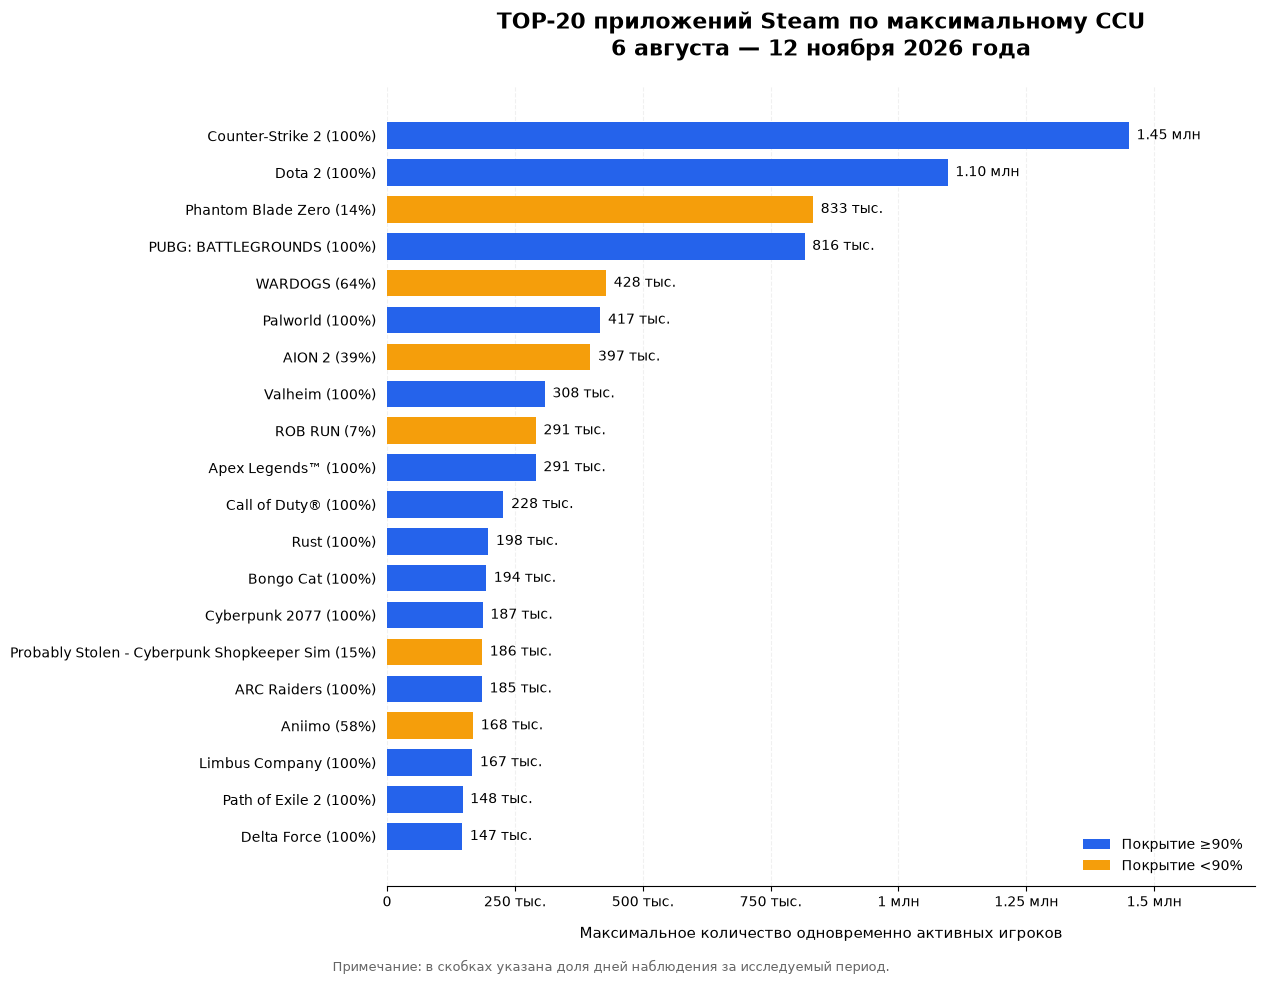

In [178]:
# TOP-20 по максимальному CCU
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from matplotlib.patches import Patch
from pathlib import Path

# Подготовка данных
data = (
    ranking_df
    .nsmallest(20, "rank_peak")
    .sort_values("peak_ccu")
    .copy()
)

# Цвета по полноте наблюдений
data["color"] = data["coverage_pct"].apply(
    lambda x: "#2563EB" if x >= 90 else "#F59E0B"
)

# Названия с покрытием
data["label"] = data.apply(
    lambda row: (
        f"{row['final_name']} "
        f"({row['coverage_pct']:.0f}%)"
    ),
    axis=1
)

# Форматирование чисел
def format_ccu(value):
    if value >= 1_000_000:
        return f"{value / 1_000_000:.2f} млн"
    return f"{value / 1_000:.0f} тыс."


fig, ax = plt.subplots(figsize=(14, 10))

bars = ax.barh(
    data["label"],
    data["peak_ccu"],
    color=data["color"],
    height=0.72
)

# Подписи значений
for bar, value in zip(bars, data["peak_ccu"]):
    ax.text(
        bar.get_width() + 15000,
        bar.get_y() + bar.get_height() / 2,
        format_ccu(value),
        va="center",
        fontsize=10,
        fontweight="medium"
    )

# Заголовок
ax.set_title(
    "TOP-20 приложений Steam по максимальному CCU\n"
    "6 августа — 12 ноября 2026 года",
    fontsize=16,
    fontweight="bold",
    pad=22
)

ax.set_xlabel(
    "Максимальное количество одновременно активных игроков",
    fontsize=11,
    labelpad=12
)

ax.set_ylabel("")

# Форматирование оси X
ax.xaxis.set_major_locator(
    ticker.MultipleLocator(250_000)
)

ax.xaxis.set_major_formatter(
    ticker.FuncFormatter(
        lambda x, pos: (
            f"{x / 1_000_000:g} млн"
            if x >= 1_000_000
            else f"{x / 1_000:g} тыс."
            if x > 0
            else "0"
        )
    )
)

# Пространство для подписей
ax.set_xlim(
    0,
    data["peak_ccu"].max() * 1.17
)

# Сетка
ax.grid(
    axis="x",
    linestyle="--",
    alpha=0.18
)

ax.set_axisbelow(True)

# Убираем лишние рамки
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)

ax.tick_params(
    axis="y",
    length=0,
    labelsize=10,
    pad=8
)

# Легенда
legend_elements = [
    Patch(
        facecolor="#2563EB",
        label="Покрытие ≥90%"
    ),
    Patch(
        facecolor="#F59E0B",
        label="Покрытие <90%"
    )
]

ax.legend(
    handles=legend_elements,
    loc="lower right",
    frameon=False,
    fontsize=10
)

# Подпись методологического ограничения
fig.text(
    0.5,
    0.015,
    "Примечание: в скобках указана доля дней наблюдения "
    "за исследуемый период.",
    ha="center",
    fontsize=9,
    color="#666666"
)

plt.subplots_adjust(
    left=0.34,
    right=0.96,
    top=0.90,
    bottom=0.10
)

# Сохранение
figures_dir = Path("reports/figures")
figures_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(
    figures_dir / "top20_peak_ccu_improved.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

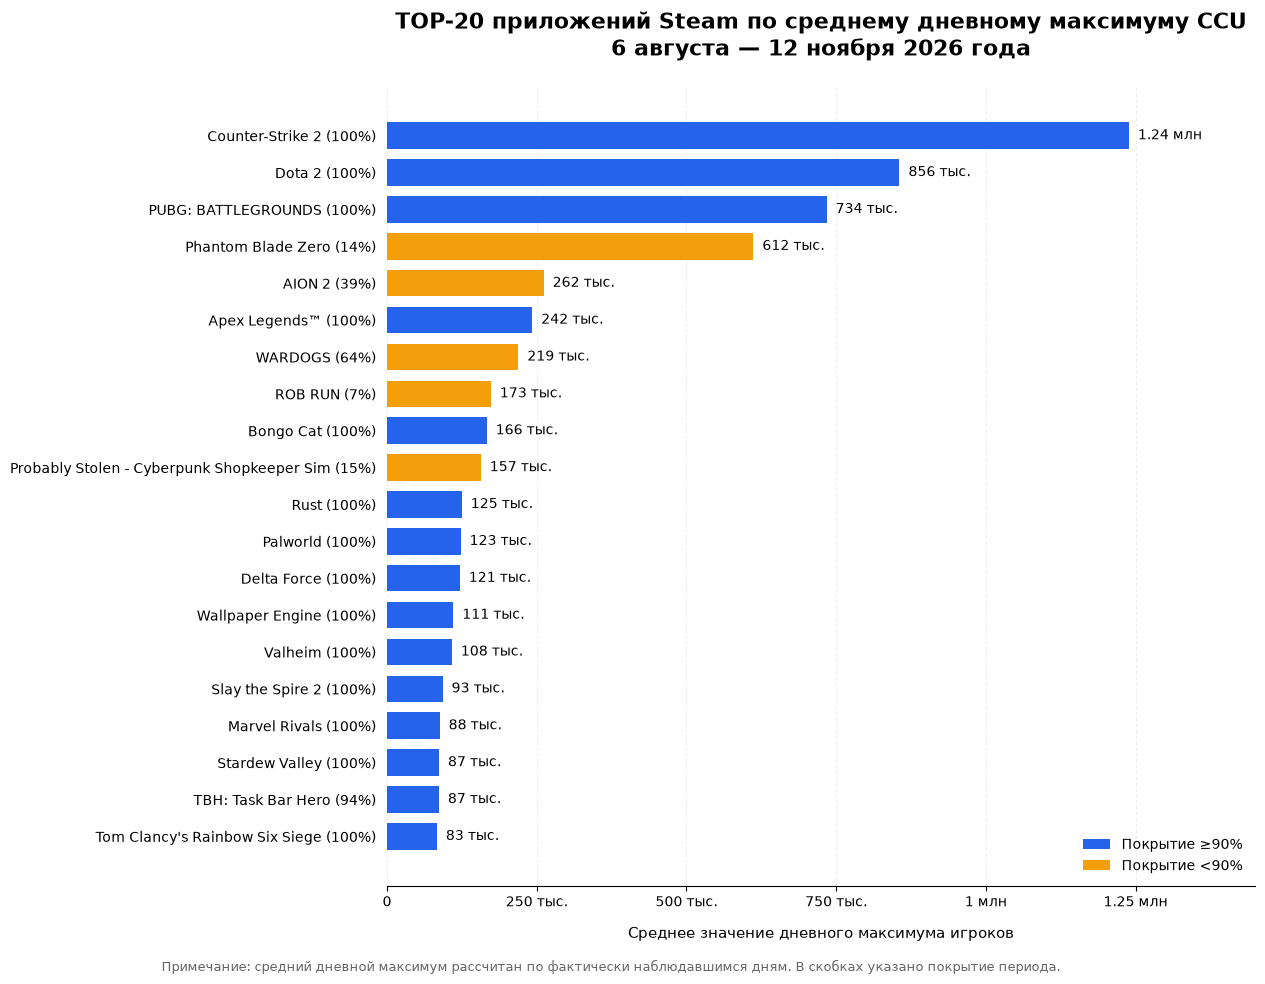

In [179]:
# TOP-20 по среднему дневному максимуму
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from matplotlib.patches import Patch
from pathlib import Path

# TOP-20 по среднему дневному максимуму
data = (
    ranking_df
    .nlargest(20, "avg_daily_peak")
    .sort_values("avg_daily_peak")
    .copy()
)

# Цвета по покрытию
data["color"] = data["coverage_pct"].apply(
    lambda x: "#2563EB" if x >= 90 else "#F59E0B"
)

# Название и процент покрытия
data["label"] = data.apply(
    lambda row: (
        f"{row['final_name']} "
        f"({row['coverage_pct']:.0f}%)"
    ),
    axis=1
)

def format_ccu(value):
    if value >= 1_000_000:
        return f"{value / 1_000_000:.2f} млн"
    return f"{value / 1_000:.0f} тыс."


fig, ax = plt.subplots(figsize=(14, 10))

bars = ax.barh(
    data["label"],
    data["avg_daily_peak"],
    color=data["color"],
    height=0.72
)

# Подписи значений
for bar, value in zip(bars, data["avg_daily_peak"]):
    ax.text(
        bar.get_width() + 15000,
        bar.get_y() + bar.get_height() / 2,
        format_ccu(value),
        va="center",
        fontsize=10,
        fontweight="medium"
    )

ax.set_title(
    "TOP-20 приложений Steam по среднему дневному максимуму CCU\n"
    "6 августа — 12 ноября 2026 года",
    fontsize=16,
    fontweight="bold",
    pad=22
)

ax.set_xlabel(
    "Среднее значение дневного максимума игроков",
    fontsize=11,
    labelpad=12
)

ax.set_ylabel("")

# Ось X
ax.xaxis.set_major_locator(
    ticker.MultipleLocator(250_000)
)

ax.xaxis.set_major_formatter(
    ticker.FuncFormatter(
        lambda x, pos: (
            f"{x / 1_000_000:g} млн"
            if x >= 1_000_000
            else f"{x / 1_000:g} тыс."
            if x > 0
            else "0"
        )
    )
)

ax.set_xlim(
    0,
    data["avg_daily_peak"].max() * 1.17
)

ax.grid(
    axis="x",
    linestyle="--",
    alpha=0.18
)

ax.set_axisbelow(True)

# Убираем лишние рамки
for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)

ax.tick_params(
    axis="y",
    length=0,
    labelsize=10,
    pad=8
)

# Легенда
legend_elements = [
    Patch(
        facecolor="#2563EB",
        label="Покрытие ≥90%"
    ),
    Patch(
        facecolor="#F59E0B",
        label="Покрытие <90%"
    )
]

ax.legend(
    handles=legend_elements,
    loc="lower right",
    frameon=False,
    fontsize=10
)

fig.text(
    0.5,
    0.015,
    "Примечание: средний дневной максимум рассчитан "
    "по фактически наблюдавшимся дням. "
    "В скобках указано покрытие периода.",
    ha="center",
    fontsize=9,
    color="#666666"
)

plt.subplots_adjust(
    left=0.34,
    right=0.96,
    top=0.90,
    bottom=0.10
)

# Сохранение
figures_dir = Path("reports/figures")
figures_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(
    figures_dir / "top20_avg_daily_peak_improved.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
# На этом графике могут появиться приложения с низким покрытием. Это не ошибка: рейтинг построен по фактически наблюдавшимся дням.

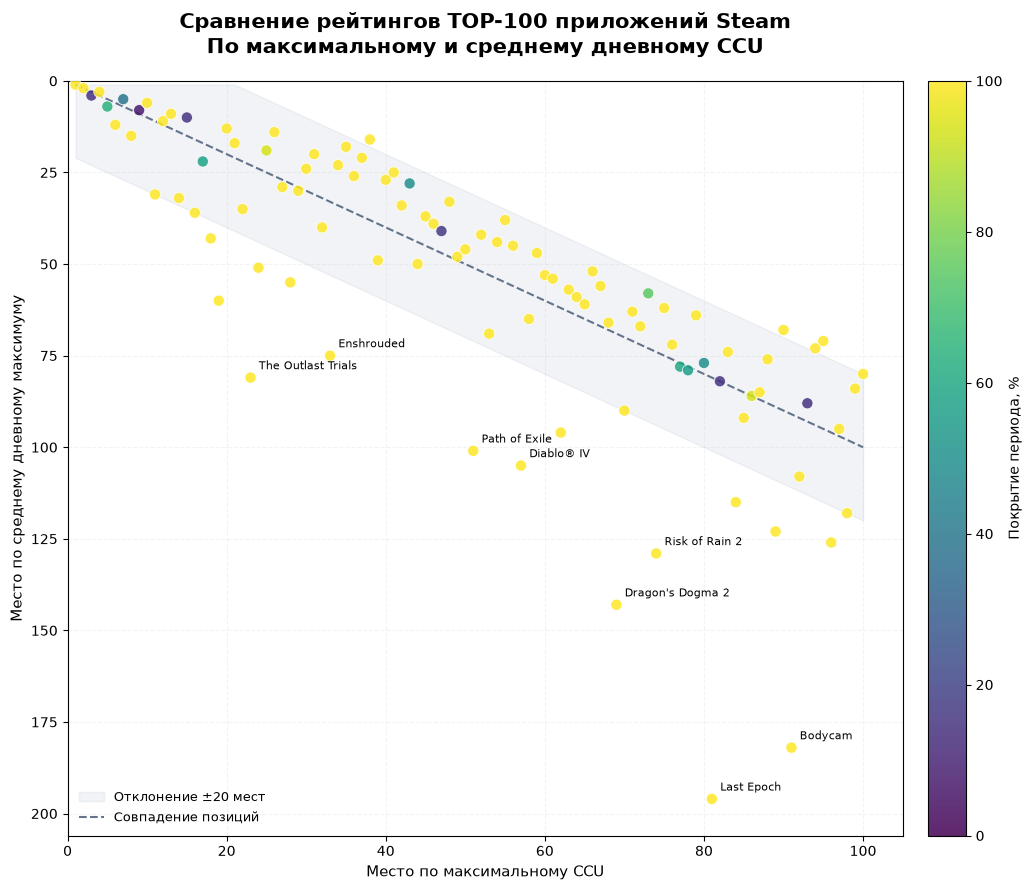

In [180]:
# Сравнение рейтингов TOP-100
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

# TOP-100 по максимальному CCU
data = (
    ranking_df
    .nsmallest(100, "rank_peak")
    .copy()
)

# Разница между рейтингами
data["rank_difference"] = (
    data["rank_avg_daily_peak"] -
    data["rank_peak"]
)

data["abs_rank_difference"] = (
    data["rank_difference"].abs()
)

fig, ax = plt.subplots(figsize=(11, 9))

# Диагональ и коридор ±20 мест
x = np.linspace(1, 100, 200)

ax.fill_between(
    x,
    np.maximum(1, x - 20),
    x + 20,
    color="#94A3B8",
    alpha=0.12,
    label="Отклонение ±20 мест"
)

ax.plot(
    x,
    x,
    linestyle="--",
    color="#64748B",
    linewidth=1.5,
    label="Совпадение позиций"
)

# Точки
scatter = ax.scatter(
    data["rank_peak"],
    data["rank_avg_daily_peak"],
    c=data["coverage_pct"],
    cmap="viridis",
    vmin=0,
    vmax=100,
    s=65,
    alpha=0.85,
    edgecolors="white",
    linewidths=0.6,
    zorder=3
)

# Подписи 8 наибольших расхождений
outliers = data.nlargest(
    8,
    "abs_rank_difference"
)

for _, row in outliers.iterrows():
    ax.annotate(
        row["final_name"],
        (
            row["rank_peak"],
            row["rank_avg_daily_peak"]
        ),
        xytext=(6, 6),
        textcoords="offset points",
        fontsize=8
    )

ax.set_title(
    "Сравнение рейтингов TOP-100 приложений Steam\n"
    "По максимальному и среднему дневному CCU",
    fontsize=15,
    fontweight="bold",
    pad=20
)

ax.set_xlabel(
    "Место по максимальному CCU",
    fontsize=11
)

ax.set_ylabel(
    "Место по среднему дневному максимуму",
    fontsize=11
)

ax.set_xlim(0, 105)

ax.set_ylim(
    0,
    max(
        105,
        data["rank_avg_daily_peak"].max() + 10
    )
)

ax.invert_yaxis()

ax.grid(
    linestyle="--",
    alpha=0.15
)

ax.set_axisbelow(True)

# Цветовая шкала
cbar = plt.colorbar(
    scatter,
    ax=ax,
    pad=0.025
)

cbar.set_label(
    "Покрытие периода, %",
    fontsize=10
)

ax.legend(
    loc="lower left",
    frameon=False,
    fontsize=9
)

plt.tight_layout()

# Сохранение
figures_dir = Path("reports/figures")
figures_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(
    figures_dir / "top100_rank_comparison_improved.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()


In [181]:
# Дополнительный количественный анализ 
# TOP-100 по максимальному CCU
data = (
    ranking_df
    .nsmallest(100, "rank_peak")
    .copy()
)

# Разница позиций
data["rank_difference"] = (
    data["rank_avg_daily_peak"] -
    data["rank_peak"]
)

# Абсолютная разница
data["abs_rank_difference"] = (
    data["rank_difference"].abs()
)

# Коэффициент корреляции Спирмена
spearman_corr = data[
    ["rank_peak", "rank_avg_daily_peak"]
].corr(method="spearman").iloc[0, 1]

print(f"Корреляция Спирмена: {spearman_corr:.3f}")

print(
    "Среднее абсолютное изменение позиции:",
    round(data["abs_rank_difference"].mean(), 2)
)

print(
    "Медианное абсолютное изменение позиции:",
    round(data["abs_rank_difference"].median(), 2)
)

print(
    "Приложений с отклонением более 20 мест:",
    (data["abs_rank_difference"] > 20).sum()
)

print(
    "Максимальное изменение позиции:",
    data["abs_rank_difference"].max()
)

display(
    data.nlargest(
        10,
        "abs_rank_difference"
    )[
        [
            "final_name",
            "rank_peak",
            "rank_avg_daily_peak",
            "rank_difference",
            "coverage_pct"
        ]
    ]
)

Корреляция Спирмена: 0.857
Среднее абсолютное изменение позиции: 15.33
Медианное абсолютное изменение позиции: 10.0
Приложений с отклонением более 20 мест: 20
Максимальное изменение позиции: 115


,final_name,rank_peak,rank_avg_daily_peak,rank_difference,coverage_pct
80,Last Epoch,81,196,115,100.00
90,Bodycam,91,182,91,100.00
68,Dragon's Dogma 2,69,143,74,100.00
22,The Outlast Trials,23,81,58,100.00
73,Risk of Rain 2,74,129,55,100.00
50,Path of Exile,51,101,50,100.00
56,Diablo® IV,57,105,48,100.00
32,Enshrouded,33,75,42,100.00
18,Path of Exile 2,19,60,41,100.00
61,No Man's Sky,62,96,34,100.00


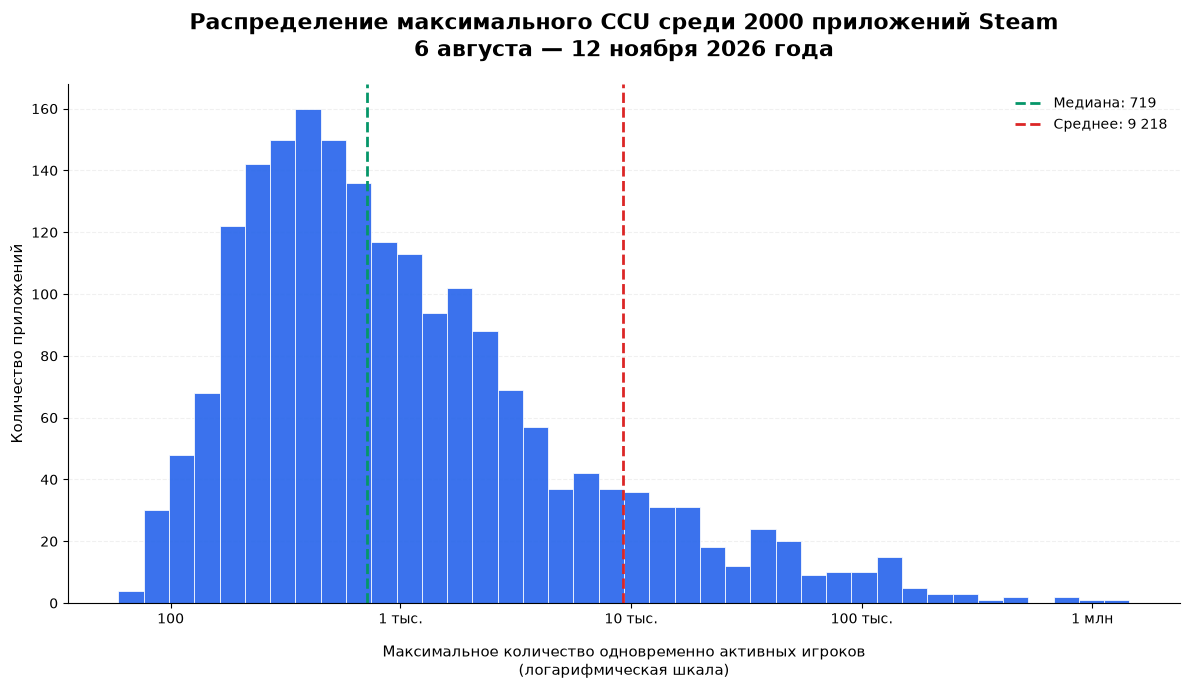

Медиана CCU: 719
Средний CCU: 9,218


In [182]:
# Распределение популярности всех 2000 игр 

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Данные всех 2000 приложений
peak = ranking_df["peak_ccu"].dropna()

# Логарифмическое преобразование
log_peak = np.log10(peak + 1)

# Основные статистики
median_peak = peak.median()
mean_peak = peak.mean()

fig, ax = plt.subplots(figsize=(12, 7))

# Гистограмма
ax.hist(
    log_peak,
    bins=40,
    color="#2563EB",
    edgecolor="white",
    linewidth=0.6,
    alpha=0.9
)

# Медиана
ax.axvline(
    np.log10(median_peak + 1),
    color="#059669",
    linestyle="--",
    linewidth=2,
    label=f"Медиана: {median_peak:,.0f}".replace(",", " ")
)

# Среднее
ax.axvline(
    np.log10(mean_peak + 1),
    color="#DC2626",
    linestyle="--",
    linewidth=2,
    label=f"Среднее: {mean_peak:,.0f}".replace(",", " ")
)

# Подписи оси X в реальных значениях CCU
ticks = [100, 1000, 10000, 100000, 1000000]

ax.set_xticks(
    np.log10(np.array(ticks) + 1)
)

ax.set_xticklabels(
    ["100", "1 тыс.", "10 тыс.", "100 тыс.", "1 млн"]
)

ax.set_title(
    "Распределение максимального CCU среди 2000 приложений Steam\n"
    "6 августа — 12 ноября 2026 года",
    fontsize=16,
    fontweight="bold",
    pad=20
)

ax.set_xlabel(
    "Максимальное количество одновременно активных игроков\n"
    "(логарифмическая шкала)",
    fontsize=11,
    labelpad=12
)

ax.set_ylabel(
    "Количество приложений",
    fontsize=11
)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.18
)

ax.set_axisbelow(True)

for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)

ax.legend(
    loc="upper right",
    frameon=False,
    fontsize=10
)

plt.tight_layout()

# Сохранение
figures_dir = Path("reports/figures")
figures_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(
    figures_dir / "peak_ccu_distribution_improved.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print(f"Медиана CCU: {median_peak:,.0f}")
print(f"Средний CCU: {mean_peak:,.0f}")

In [177]:
# Сохраним TOP-100

top100_df.to_csv(
    output_dir / "steam_top100.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Файл сохранён:")
print((output_dir / "steam_top100.csv").resolve())

Файл сохранён:
C:\Users\truni\OneDrive\Рабочий стол\LifeStyle\_Иннополис\_1 - Attestation\data\processed\steam_top100.csv


## Проведем анализ жанров и их распределение 

In [183]:
# Проверяем структуру таблицы жанров

display(con.execute("""
    DESCRIBE steam_app_genres
""").df())

,column_name,column_type,null,key,default,extra
0,app_id,INTEGER,NO,PRI,None,None
1,genre_id,VARCHAR,NO,PRI,None,None
2,genre_name,VARCHAR,YES,NaN,None,None


In [184]:
# Посмотрим первые десять записей:

display(con.execute("""
    SELECT *
    FROM steam_app_genres
    LIMIT 10
""").df())

,app_id,genre_id,genre_name
0,570,1,Action
1,570,2,Strategy
2,570,37,Free To Play
3,10,1,Action
4,50,1,Action
5,70,1,Action
6,80,1,Action
7,220,1,Action
8,240,1,Action
9,300,1,Action


In [185]:
# Создаём аналитический датафрейм жанров

genres_df = con.execute("""
    SELECT
        g.app_id,
        g.genre_name,
        a.final_name,
        a.app_type,
        a.peak_ccu,
        a.avg_daily_peak,
        a.days_observed,
        a.coverage_pct

    FROM steam_app_genres g

    INNER JOIN steam_games_analytics a
        ON g.app_id = a.app_id

    ORDER BY g.genre_name, a.peak_ccu DESC
""").df()

print("Количество записей:", len(genres_df))
print("Уникальных приложений:", genres_df["app_id"].nunique())
print("Уникальных жанров:", genres_df["genre_name"].nunique())

display(genres_df.head(10))

Количество записей: 5677
Уникальных приложений: 1990
Уникальных жанров: 19


,app_id,genre_name,final_name,app_type,peak_ccu,avg_daily_peak,days_observed,coverage_pct
0,730,Action,Counter-Strike 2,game,1450705,"1,238,948.45",99,100.00
1,570,Action,Dota 2,game,1096364,"855,789.77",99,100.00
2,4115450,Action,Phantom Blade Zero,game,832967,"611,784.64",14,14.14
3,578080,Action,PUBG: BATTLEGROUNDS,game,816367,"734,037.35",99,100.00
4,1867240,Action,WARDOGS,game,428219,"219,244.19",63,63.64
5,1623730,Action,Palworld,game,417043,"122,782.67",99,100.00
6,3393110,Action,AION 2,game,397356,"261,534.92",39,39.39
7,892970,Action,Valheim,game,308360,"108,176.11",99,100.00
8,4262460,Action,ROB RUN,game,290876,"173,331.57",7,7.07
9,1172470,Action,Apex Legends™,game,290755,"242,377.59",99,100.00


In [186]:
# Рассчитываем распространённость жанров. Создадим первый итоговый датафрейм

genre_frequency_df = con.execute("""
    SELECT
        g.genre_name,

        COUNT(DISTINCT g.app_id) AS games_count,

        ROUND(
            100.0 * COUNT(DISTINCT g.app_id) / 2000,
            2
        ) AS share_pct

    FROM steam_app_genres g

    GROUP BY g.genre_name

    ORDER BY games_count DESC
""").df()

display(genre_frequency_df)

,genre_name,games_count,share_pct
0,Action,985,49.25
1,Indie,815,40.75
2,Adventure,737,36.85
3,Simulation,678,33.90
4,Strategy,653,32.65
5,RPG,642,32.10
6,Casual,393,19.65
7,Free To Play,271,13.55
8,Massively Multiplayer,182,9.10
9,Early Access,136,6.80


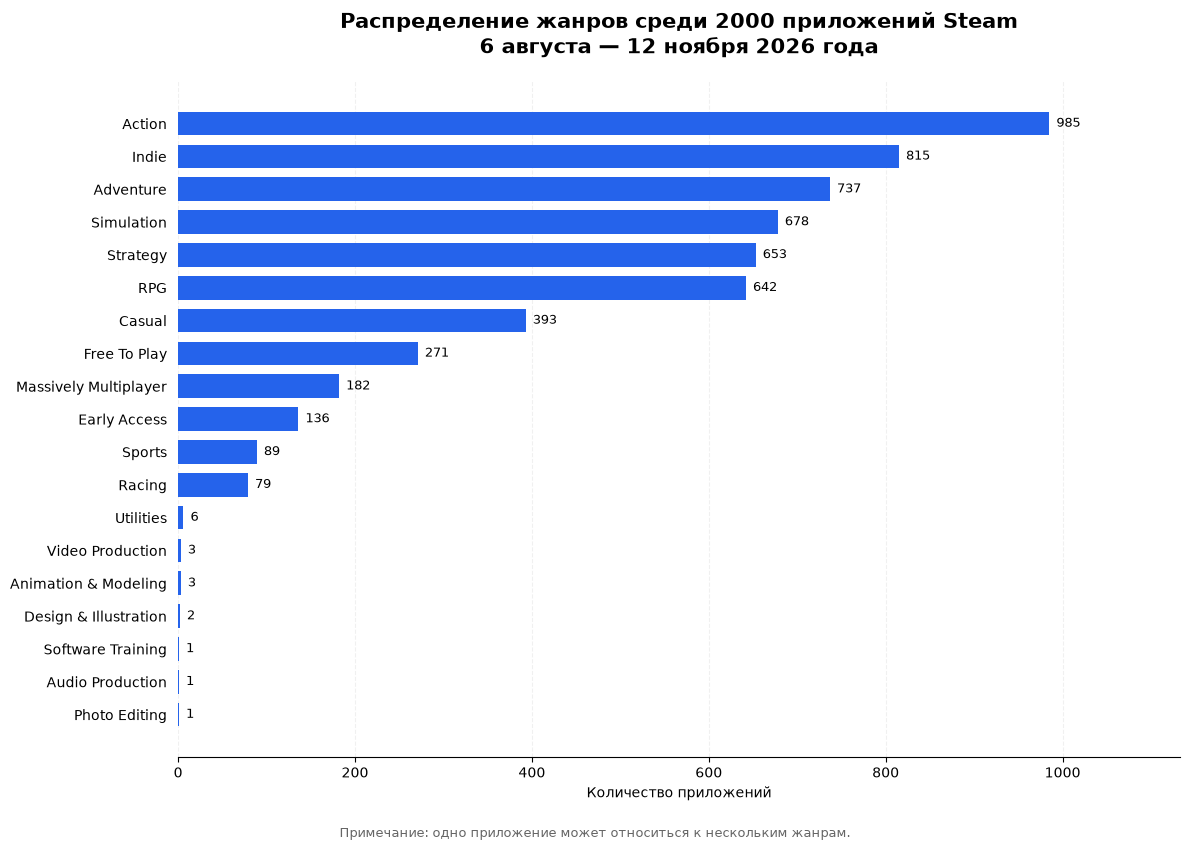

In [187]:
# Создадим график распространнености жанров 

import matplotlib.pyplot as plt
from pathlib import Path

data = (
    genre_frequency_df
    .sort_values("games_count")
    .copy()
)

fig, ax = plt.subplots(
    figsize=(12, max(6, len(data) * 0.45))
)

bars = ax.barh(
    data["genre_name"],
    data["games_count"],
    color="#2563EB",
    height=0.72
)

for bar, value in zip(bars, data["games_count"]):
    ax.text(
        bar.get_width() + 8,
        bar.get_y() + bar.get_height() / 2,
        str(value),
        va="center",
        fontsize=9
    )

ax.set_title(
    "Распределение жанров среди 2000 приложений Steam\n"
    "6 августа — 12 ноября 2026 года",
    fontsize=15,
    fontweight="bold",
    pad=20
)

ax.set_xlabel("Количество приложений")
ax.set_ylabel("")

ax.set_xlim(0, data["games_count"].max() * 1.15)

ax.grid(axis="x", linestyle="--", alpha=0.18)
ax.set_axisbelow(True)

for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)

ax.tick_params(axis="y", length=0, pad=8)

fig.text(
    0.5,
    0.015,
    "Примечание: одно приложение может относиться к нескольким жанрам.",
    ha="center",
    fontsize=9,
    color="#666666"
)

plt.tight_layout(rect=[0, 0.04, 1, 1])

figures_dir = Path("reports/figures")
figures_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(
    figures_dir / "steam_genre_frequency.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

In [ ]:
# Сохраним данные 

output_dir = Path("data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

genre_frequency_df.to_csv(
    output_dir / "steam_genres_analysis.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Сохранено:")
print((output_dir / "steam_genres_analysis.csv").resolve())

In [ ]:
# Формируем аналитическую таблицу. Используем уже созданные steam_app_genres и steam_games_analytics.

genre_popularity_df = con.execute("""
    SELECT
        g.genre_name,

        COUNT(DISTINCT g.app_id) AS games_count,

        ROUND(
            100.0 * COUNT(DISTINCT g.app_id) / 2000,
            2
        ) AS share_pct,

        ROUND(
            MEDIAN(a.peak_ccu),
            2
        ) AS median_peak_ccu,

        ROUND(
            AVG(a.peak_ccu),
            2
        ) AS mean_peak_ccu,

        ROUND(
            MEDIAN(a.avg_daily_peak),
            2
        ) AS median_avg_daily_peak,

        COUNT(DISTINCT g.app_id) FILTER (
            WHERE r.rank_peak <= 100
        ) AS top100_games,

        ROUND(
            100.0 * COUNT(DISTINCT g.app_id) FILTER (
                WHERE r.rank_peak <= 100
            ) / NULLIF(COUNT(DISTINCT g.app_id), 0),
            2
        ) AS top100_share_pct

    FROM steam_app_genres g

    INNER JOIN steam_games_analytics a
        ON g.app_id = a.app_id

    INNER JOIN (
        SELECT
            app_id,
            ROW_NUMBER() OVER (
                ORDER BY peak_ccu DESC, app_id
            ) AS rank_peak
        FROM steam_games_analytics
    ) r
        ON g.app_id = r.app_id

    GROUP BY g.genre_name

    ORDER BY median_peak_ccu DESC
""").df()

display(genre_popularity_df)

# Здесь top100_share_pct — это доля приложений конкретного жанра, попавших в TOP-100, а не доля жанра внутри TOP-100.

,genre_name,games_count,share_pct,median_peak_ccu,mean_peak_ccu,median_avg_daily_peak,top100_games,top100_share_pct
0,Photo Editing,1,0.05,"126,084.00","126,084.00","110,649.04",1,100.00
1,Design & Illustration,2,0.10,"71,198.00","71,198.00","62,084.61",1,50.00
2,Software Training,1,0.05,"57,289.00","57,289.00","40,759.44",1,100.00
3,Utilities,6,0.30,"27,032.00","40,765.83","22,716.07",2,33.33
4,Video Production,3,0.15,"20,629.00","23,994.67","13,520.17",0,0.00
5,Animation & Modeling,3,0.15,"20,629.00","54,341.67","13,520.17",1,33.33
6,Audio Production,1,0.05,"19,021.00","19,021.00","14,919.05",0,0.00
7,Racing,79,3.95,"1,093.00","7,181.66",481.37,6,7.59
8,Massively Multiplayer,182,9.10,"1,059.00","22,910.14",522.15,21,11.54
9,Adventure,737,36.85,996.00,"9,533.41",387.60,43,5.83


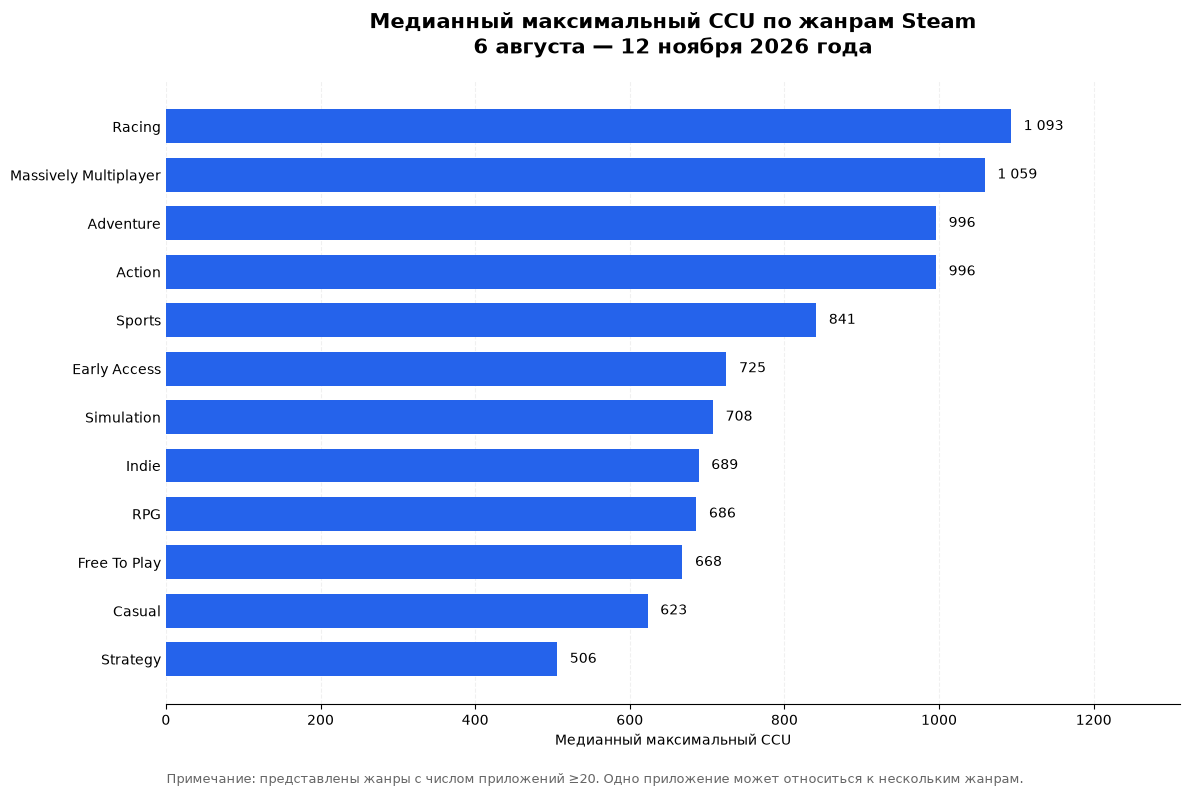

In [189]:
# Визуализируем медианный CCU по жанрам
# Для начала исключим из графика жанры, представленные менее чем 20 приложениями. 
# Это не удалит их из аналитической таблицы, но позволит избежать сравнений на основе единичных наблюдений.

import matplotlib.pyplot as plt
from pathlib import Path

data = (
    genre_popularity_df[
        genre_popularity_df["games_count"] >= 20
    ]
    .sort_values("median_peak_ccu")
    .copy()
)

fig, ax = plt.subplots(figsize=(12, 8))

bars = ax.barh(
    data["genre_name"],
    data["median_peak_ccu"],
    color="#2563EB",
    height=0.7
)

# Подписи медианных значений
for bar, value in zip(bars, data["median_peak_ccu"]):
    ax.text(
        bar.get_width() + data["median_peak_ccu"].max() * 0.015,
        bar.get_y() + bar.get_height() / 2,
        f"{value:,.0f}".replace(",", " "),
        va="center",
        fontsize=10
    )

ax.set_title(
    "Медианный максимальный CCU по жанрам Steam\n"
    "6 августа — 12 ноября 2026 года",
    fontsize=15,
    fontweight="bold",
    pad=20
)

ax.set_xlabel("Медианный максимальный CCU")
ax.set_ylabel("")

ax.set_xlim(
    0,
    data["median_peak_ccu"].max() * 1.2
)

ax.grid(
    axis="x",
    linestyle="--",
    alpha=0.18
)

ax.set_axisbelow(True)

for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)

ax.tick_params(axis="y", length=0)

fig.text(
    0.5,
    0.015,
    "Примечание: представлены жанры с числом приложений ≥20. "
    "Одно приложение может относиться к нескольким жанрам.",
    ha="center",
    fontsize=9,
    color="#666666"
)

plt.tight_layout(rect=[0, 0.04, 1, 1])

figures_dir = Path("reports/figures")
figures_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(
    figures_dir / "steam_genre_median_ccu.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

In [190]:
# Дополнительная проверка: представленность жанров в TOP-100

display(
    genre_popularity_df[
        [
            "genre_name",
            "games_count",
            "median_peak_ccu",
            "top100_games",
            "top100_share_pct"
        ]
    ]
    .sort_values(
        "top100_share_pct",
        ascending=False
    )
)

,genre_name,games_count,median_peak_ccu,top100_games,top100_share_pct
0,Photo Editing,1,"126,084.00",1,100.00
2,Software Training,1,"57,289.00",1,100.00
1,Design & Illustration,2,"71,198.00",1,50.00
3,Utilities,6,"27,032.00",2,33.33
5,Animation & Modeling,3,"20,629.00",1,33.33
8,Massively Multiplayer,182,"1,059.00",21,11.54
16,Free To Play,271,668.00,27,9.96
7,Racing,79,"1,093.00",6,7.59
12,Early Access,136,725.00,10,7.35
10,Action,985,996.00,70,7.11


In [191]:
# Сохраним расширенную статистику 

from pathlib import Path

output_dir = Path("data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

genre_popularity_df.to_csv(
    output_dir / "steam_genre_popularity.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Сохранено:")
print((output_dir / "steam_genre_popularity.csv").resolve())

Сохранено:
C:\Users\truni\OneDrive\Рабочий стол\LifeStyle\_Иннополис\_1 - Attestation\data\processed\steam_genre_popularity.csv


In [192]:
# Создаём датафрейм жанровых сочетаний
# Используем таблицу steam_app_genres, в которой содержатся 5677 записей для 1990 игр.
genre_pairs_df = con.execute("""
    SELECT
        g1.genre_name AS genre_1,
        g2.genre_name AS genre_2,

        COUNT(DISTINCT g1.app_id) AS games_count,

        ROUND(
            100.0 * COUNT(DISTINCT g1.app_id) / 2000,
            2
        ) AS share_pct

    FROM steam_app_genres g1

    INNER JOIN steam_app_genres g2
        ON g1.app_id = g2.app_id
        AND g1.genre_name < g2.genre_name

    GROUP BY
        g1.genre_name,
        g2.genre_name

    ORDER BY games_count DESC
""").df()

print("Уникальных сочетаний жанров:", len(genre_pairs_df))

display(genre_pairs_df.head(20))

Уникальных сочетаний жанров: 92


,genre_1,genre_2,games_count,share_pct
0,Action,Adventure,485,24.25
1,Indie,Simulation,372,18.60
2,Action,Indie,368,18.40
3,Adventure,Indie,340,17.00
4,Action,RPG,331,16.55
5,Adventure,RPG,330,16.50
6,Simulation,Strategy,309,15.45
7,Indie,Strategy,302,15.10
8,Indie,RPG,274,13.70
9,Casual,Indie,270,13.50


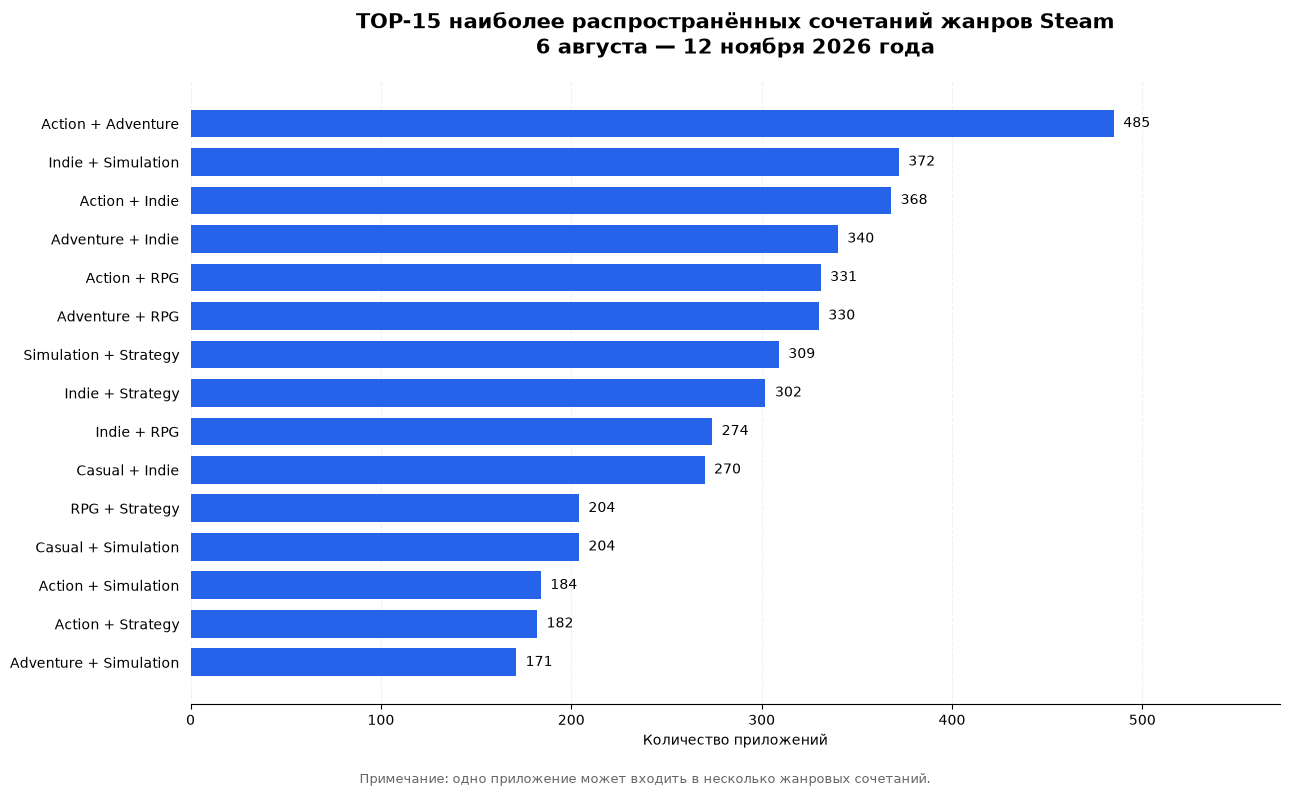

In [193]:
# Визуализируем TOP-15 жанровых сочетаний
# 

import matplotlib.pyplot as plt
from pathlib import Path

# TOP-15 сочетаний
top15_pairs = (
    genre_pairs_df
    .head(15)
    .sort_values("games_count")
    .copy()
)

top15_pairs["pair_name"] = (
    top15_pairs["genre_1"]
    + " + "
    + top15_pairs["genre_2"]
)

fig, ax = plt.subplots(figsize=(13, 8))

bars = ax.barh(
    top15_pairs["pair_name"],
    top15_pairs["games_count"],
    color="#2563EB",
    height=0.72
)

# Подписи значений
for bar, value in zip(bars, top15_pairs["games_count"]):
    ax.text(
        bar.get_width() + 5,
        bar.get_y() + bar.get_height() / 2,
        str(value),
        va="center",
        fontsize=10
    )

ax.set_title(
    "TOP-15 наиболее распространённых сочетаний жанров Steam\n"
    "6 августа — 12 ноября 2026 года",
    fontsize=15,
    fontweight="bold",
    pad=20
)

ax.set_xlabel("Количество приложений")
ax.set_ylabel("")

ax.set_xlim(
    0,
    top15_pairs["games_count"].max() * 1.18
)

ax.grid(
    axis="x",
    linestyle="--",
    alpha=0.18
)

ax.set_axisbelow(True)

for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)

ax.tick_params(axis="y", length=0, pad=8)

fig.text(
    0.5,
    0.015,
    "Примечание: одно приложение может входить в несколько жанровых сочетаний.",
    ha="center",
    fontsize=9,
    color="#666666"
)

plt.tight_layout(rect=[0, 0.04, 1, 1])

figures_dir = Path("reports/figures")
figures_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(
    figures_dir / "steam_top15_genre_pairs.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

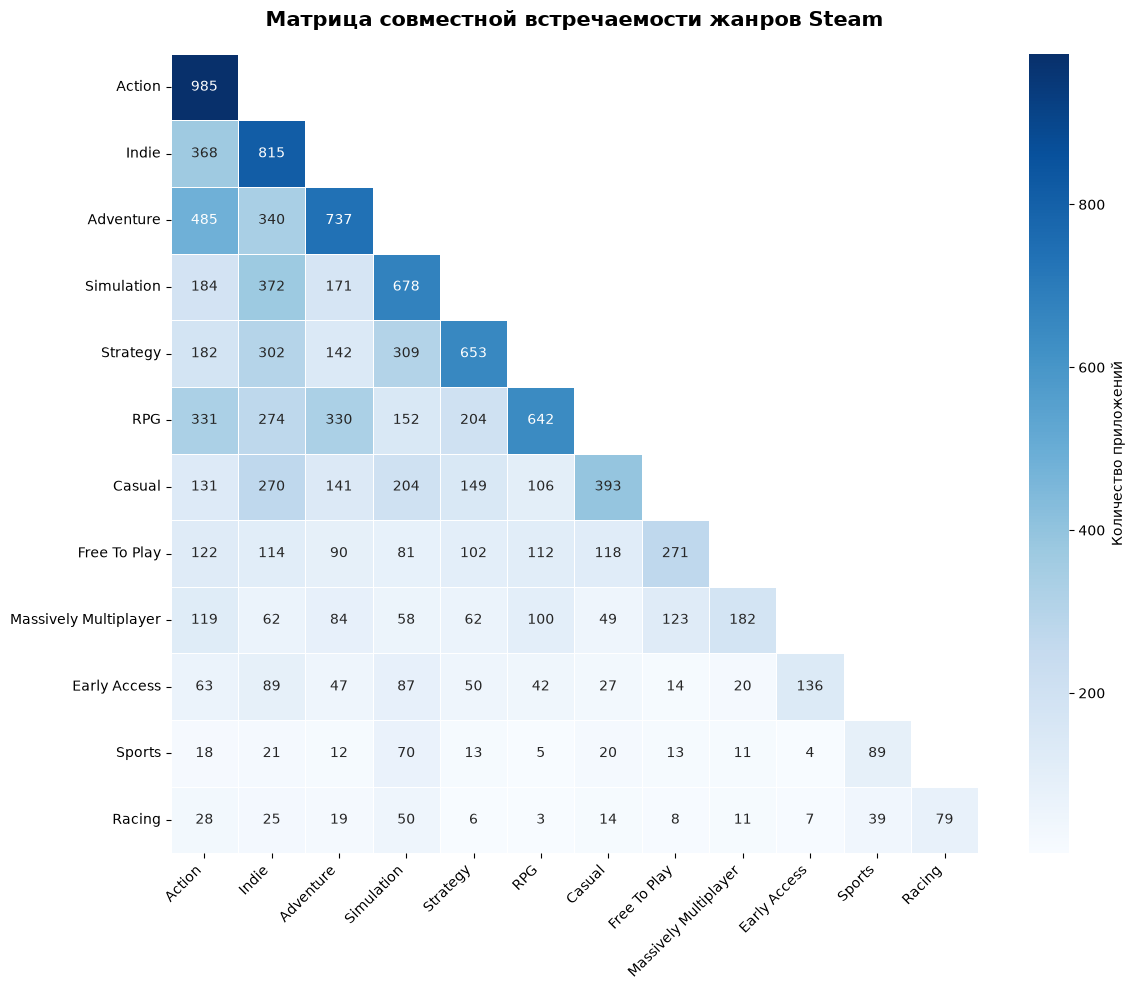

In [ ]:
# Матрица совместной встречаемости жанров
# Теперь построим тепловую карту (heatmap), показывающую, насколько часто два жанра встречаются у одного приложения.
# Для наглядности возьмём жанры, представленные не менее чем в 20 приложениях. 
# Это позволит исключить малочисленные категории программного обеспечения, но не изменит исходную таблицу.

import seaborn as sns
import numpy as np

# Жанры с достаточным количеством приложений
main_genres = genre_frequency_df.loc[
    genre_frequency_df["games_count"] >= 20,
    "genre_name"
].tolist()

# Матрица наличия жанров: приложение × жанр
genre_matrix = (
    genres_df[
        genres_df["genre_name"].isin(main_genres)
    ]
    .assign(value=1)
    .pivot_table(
        index="app_id",
        columns="genre_name",
        values="value",
        aggfunc="max",
        fill_value=0
    )
)

# Совместная встречаемость
cooccurrence = genre_matrix.T @ genre_matrix

# Сортировка по распространённости
cooccurrence = cooccurrence.loc[
    main_genres,
    main_genres
]

# Скрываем верхний треугольник, чтобы не дублировать пары
mask = np.triu(
    np.ones_like(cooccurrence, dtype=bool),
    k=1
)

fig, ax = plt.subplots(figsize=(12, 10))

sns.heatmap(
    cooccurrence,
    mask=mask,
    annot=True,
    fmt="d",
    cmap="Blues",
    linewidths=0.5,
    linecolor="white",
    cbar_kws={
        "label": "Количество приложений"
    },
    ax=ax
)

ax.set_title(
    "Матрица совместной встречаемости жанров Steam",
    fontsize=15,
    fontweight="bold",
    pad=20
)

ax.set_xlabel("")
ax.set_ylabel("")

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()

plt.savefig(
    figures_dir / "steam_genre_cooccurrence.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

# На диагонали матрицы будет указано количество приложений каждого жанра. 
# Остальные ячейки покажут количество приложений, одновременно относящихся к двум жанрам.

In [195]:
# Анализ популярности жанровых сочетаний. Теперь объединим пары жанров с аналитическими показателями CCU.

genre_pairs_popularity_df = con.execute("""
    WITH pairs AS (
        SELECT
            g1.app_id,
            g1.genre_name AS genre_1,
            g2.genre_name AS genre_2

        FROM steam_app_genres g1

        JOIN steam_app_genres g2
            ON g1.app_id = g2.app_id
            AND g1.genre_name < g2.genre_name
    ),

    ranked AS (
        SELECT
            app_id,
            peak_ccu,
            avg_daily_peak,
            coverage_pct,

            ROW_NUMBER() OVER (
                ORDER BY peak_ccu DESC, app_id
            ) AS rank_peak

        FROM steam_games_analytics
    )

    SELECT
        p.genre_1,
        p.genre_2,

        COUNT(DISTINCT p.app_id) AS games_count,

        ROUND(
            MEDIAN(r.peak_ccu),
            2
        ) AS median_peak_ccu,

        ROUND(
            AVG(r.peak_ccu),
            2
        ) AS mean_peak_ccu,

        ROUND(
            MEDIAN(r.avg_daily_peak),
            2
        ) AS median_avg_daily_peak,

        COUNT(DISTINCT p.app_id) FILTER (
            WHERE r.rank_peak <= 100
        ) AS top100_games,

        ROUND(
            100.0 * COUNT(DISTINCT p.app_id) FILTER (
                WHERE r.rank_peak <= 100
            ) / NULLIF(COUNT(DISTINCT p.app_id), 0),
            2
        ) AS top100_share_pct

    FROM pairs p

    JOIN ranked r
        ON p.app_id = r.app_id

    GROUP BY
        p.genre_1,
        p.genre_2

    ORDER BY games_count DESC
""").df()

display(genre_pairs_popularity_df.head(20))

,genre_1,genre_2,games_count,median_peak_ccu,mean_peak_ccu,median_avg_daily_peak,top100_games,top100_share_pct
0,Action,Adventure,485,"1,228.00","13,117.07",532.64,40,8.25
1,Indie,Simulation,372,771.50,"6,468.28",346.82,15,4.03
2,Action,Indie,368,947.50,"9,564.20",370.54,22,5.98
3,Adventure,Indie,340,832.00,"7,602.63",321.12,15,4.41
4,Action,RPG,331,"1,035.00","15,466.79",465.36,32,9.67
5,Adventure,RPG,330,885.50,"11,173.51",380.30,25,7.58
6,Simulation,Strategy,309,595.00,"5,079.52",293.90,13,4.21
7,Indie,Strategy,302,502.00,"3,996.93",255.49,8,2.65
8,Indie,RPG,274,670.00,"9,676.94",273.51,17,6.20
9,Casual,Indie,270,641.50,"4,095.68",305.43,5,1.85


In [196]:
# Сохраним результаты 

output_dir = Path("data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

genre_pairs_df.to_csv(
    output_dir / "steam_genre_pairs.csv",
    index=False,
    encoding="utf-8-sig"
)

genre_pairs_popularity_df.to_csv(
    output_dir / "steam_genre_pairs_popularity.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Результаты анализа жанровых сочетаний сохранены.")


Результаты анализа жанровых сочетаний сохранены.


In [197]:
# Lift — коэффициента относительной силы связи между жанрами.
# Рассчитываем Lift для всех 92 сочетаний


# Общее количество приложений
total_games = 2000

# Частота каждого жанра
genre_counts = genre_frequency_df[
    ["genre_name", "games_count"]
].copy()

# Добавляем количество приложений первого жанра
genre_lift_df = genre_pairs_df.merge(
    genre_counts.rename(
        columns={
            "genre_name": "genre_1",
            "games_count": "genre_1_count"
        }
    ),
    on="genre_1",
    how="left",
    validate="many_to_one"
)

# Добавляем количество приложений второго жанра
genre_lift_df = genre_lift_df.merge(
    genre_counts.rename(
        columns={
            "genre_name": "genre_2",
            "games_count": "genre_2_count"
        }
    ),
    on="genre_2",
    how="left",
    validate="many_to_one"
)

# Ожидаемая частота при независимости
genre_lift_df["expected_count"] = (
    genre_lift_df["genre_1_count"]
    * genre_lift_df["genre_2_count"]
    / total_games
)

# Lift
genre_lift_df["lift"] = (
    genre_lift_df["games_count"]
    / genre_lift_df["expected_count"]
)

# Разница между наблюдаемой и ожидаемой частотой
genre_lift_df["excess_count"] = (
    genre_lift_df["games_count"]
    - genre_lift_df["expected_count"]
)

# Округление
genre_lift_df[
    ["expected_count", "lift", "excess_count"]
] = genre_lift_df[
    ["expected_count", "lift", "excess_count"]
].round(3)

# Сортировка по Lift
genre_lift_df = genre_lift_df.sort_values(
    "lift",
    ascending=False
).reset_index(drop=True)

print("Проанализировано сочетаний:", len(genre_lift_df))

display(genre_lift_df.head(20))


Проанализировано сочетаний: 92


,genre_1,genre_2,games_count,share_pct,genre_1_count,genre_2_count,expected_count,lift,excess_count
0,Design & Illustration,Photo Editing,1,0.05,2,1,0.00,"1,000.00",1.00
1,Animation & Modeling,Design & Illustration,2,0.10,3,2,0.00,666.67,2.00
2,Animation & Modeling,Photo Editing,1,0.05,3,1,0.00,666.67,1.00
3,Animation & Modeling,Video Production,2,0.10,3,3,0.00,444.44,2.00
4,Software Training,Utilities,1,0.05,1,6,0.00,333.33,1.00
5,Audio Production,Utilities,1,0.05,1,6,0.00,333.33,1.00
6,Design & Illustration,Video Production,1,0.05,2,3,0.00,333.33,1.00
7,Photo Editing,Utilities,1,0.05,1,6,0.00,333.33,1.00
8,Design & Illustration,Utilities,1,0.05,2,6,0.01,166.67,0.99
9,Animation & Modeling,Utilities,1,0.05,3,6,0.01,111.11,0.99


In [198]:
# Исключаем нестабильные сочетания
# Если два редких жанра встретились у одного приложения, Lift может оказаться чрезвычайно высоким.
# Поэтому для основной визуализации предлагаю установить два условия: Каждый жанр должен встречаться минимум у 20 приложений.
# И Каждая пара должна встречаться минимум у 20 приложений.

# Фильтрация малочисленных сочетаний
genre_lift_filtered = genre_lift_df[
    (genre_lift_df["genre_1_count"] >= 20) &
    (genre_lift_df["genre_2_count"] >= 20) &
    (genre_lift_df["games_count"] >= 20)
].copy()

print(
    "Сочетаний после фильтрации:",
    len(genre_lift_filtered)
)

display(
    genre_lift_filtered[
        [
            "genre_1",
            "genre_2",
            "games_count",
            "expected_count",
            "lift"
        ]
    ].head(20)
)

Сочетаний после фильтрации: 51


,genre_1,genre_2,games_count,expected_count,lift
11,Racing,Sports,39,3.52,11.09
13,Free To Play,Massively Multiplayer,123,24.66,4.99
18,Simulation,Sports,70,30.17,2.32
19,Casual,Free To Play,118,53.25,2.22
21,Early Access,Simulation,87,46.10,1.89
22,Racing,Simulation,50,26.78,1.87
23,Massively Multiplayer,RPG,100,58.42,1.71
26,Casual,Indie,270,160.15,1.69
28,Early Access,Massively Multiplayer,20,12.38,1.62
29,Early Access,Indie,89,55.42,1.61


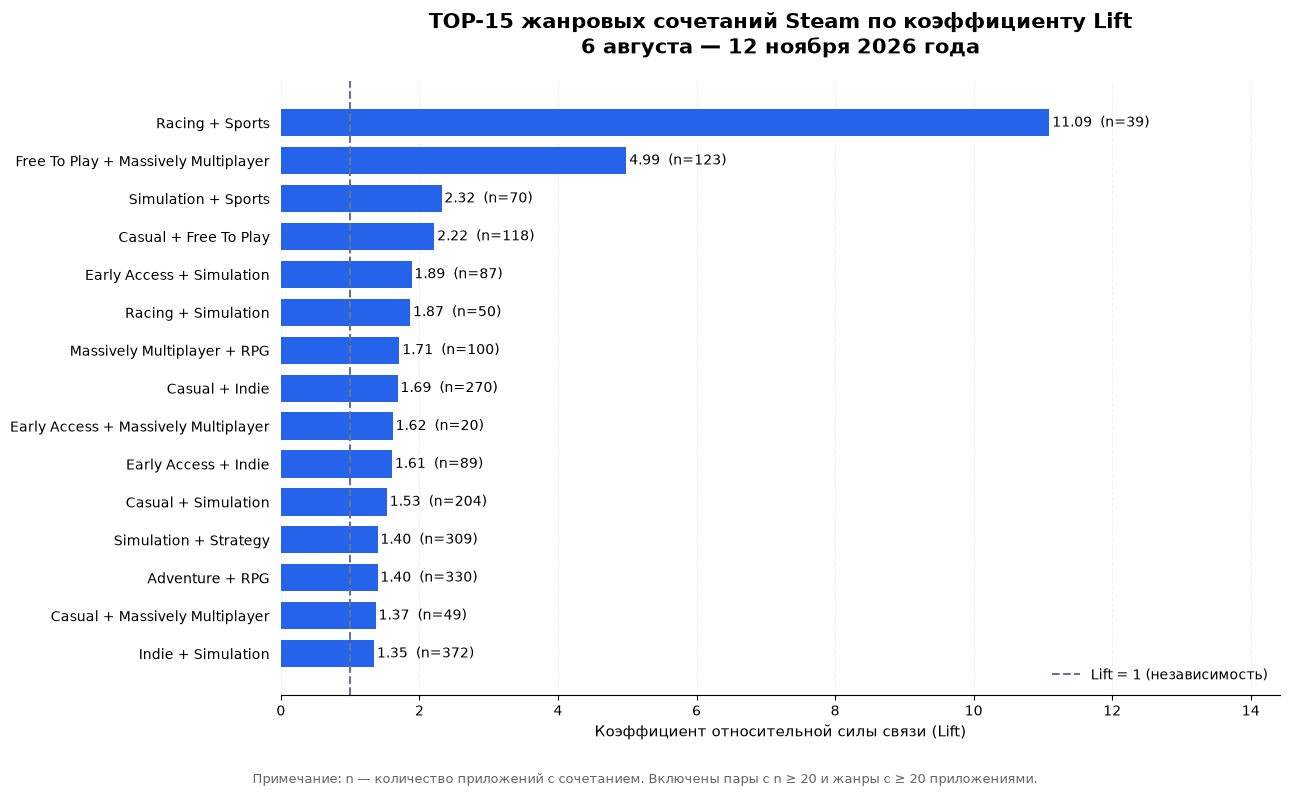

In [199]:
# Строим TOP-15 сочетаний по Lift

import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.patches import Patch

# TOP-15 по Lift
top15_lift = (
    genre_lift_filtered
    .nlargest(15, "lift")
    .sort_values("lift")
    .copy()
)

top15_lift["pair_name"] = (
    top15_lift["genre_1"]
    + " + "
    + top15_lift["genre_2"]
)

top15_lift["color"] = np.where(
    top15_lift["lift"] > 1,
    "#2563EB",
    "#F59E0B"
)

fig, ax = plt.subplots(figsize=(13, 8))

bars = ax.barh(
    top15_lift["pair_name"],
    top15_lift["lift"],
    color=top15_lift["color"],
    height=0.72
)

# Подписи Lift и количества приложений
for bar, (_, row) in zip(bars, top15_lift.iterrows()):
    ax.text(
        bar.get_width() + 0.04,
        bar.get_y() + bar.get_height() / 2,
        f"{row['lift']:.2f}  (n={row['games_count']})",
        va="center",
        fontsize=10
    )

# Линия независимости
ax.axvline(
    1,
    color="#64748B",
    linestyle="--",
    linewidth=1.5,
    label="Lift = 1 (независимость)"
)

ax.set_title(
    "TOP-15 жанровых сочетаний Steam по коэффициенту Lift\n"
    "6 августа — 12 ноября 2026 года",
    fontsize=15,
    fontweight="bold",
    pad=20
)

ax.set_xlabel(
    "Коэффициент относительной силы связи (Lift)",
    fontsize=11
)

ax.set_ylabel("")

ax.set_xlim(
    0,
    top15_lift["lift"].max() * 1.30
)

ax.grid(
    axis="x",
    linestyle="--",
    alpha=0.18
)

ax.set_axisbelow(True)

for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)

ax.tick_params(
    axis="y",
    length=0,
    pad=8
)

ax.legend(
    loc="lower right",
    frameon=False
)

fig.text(
    0.5,
    0.015,
    "Примечание: n — количество приложений с сочетанием. "
    "Включены пары с n ≥ 20 и жанры с ≥ 20 приложениями.",
    ha="center",
    fontsize=9,
    color="#666666"
)

plt.tight_layout(rect=[0, 0.05, 1, 1])

figures_dir = Path("reports/figures")
figures_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(
    figures_dir / "steam_genre_lift_top15.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

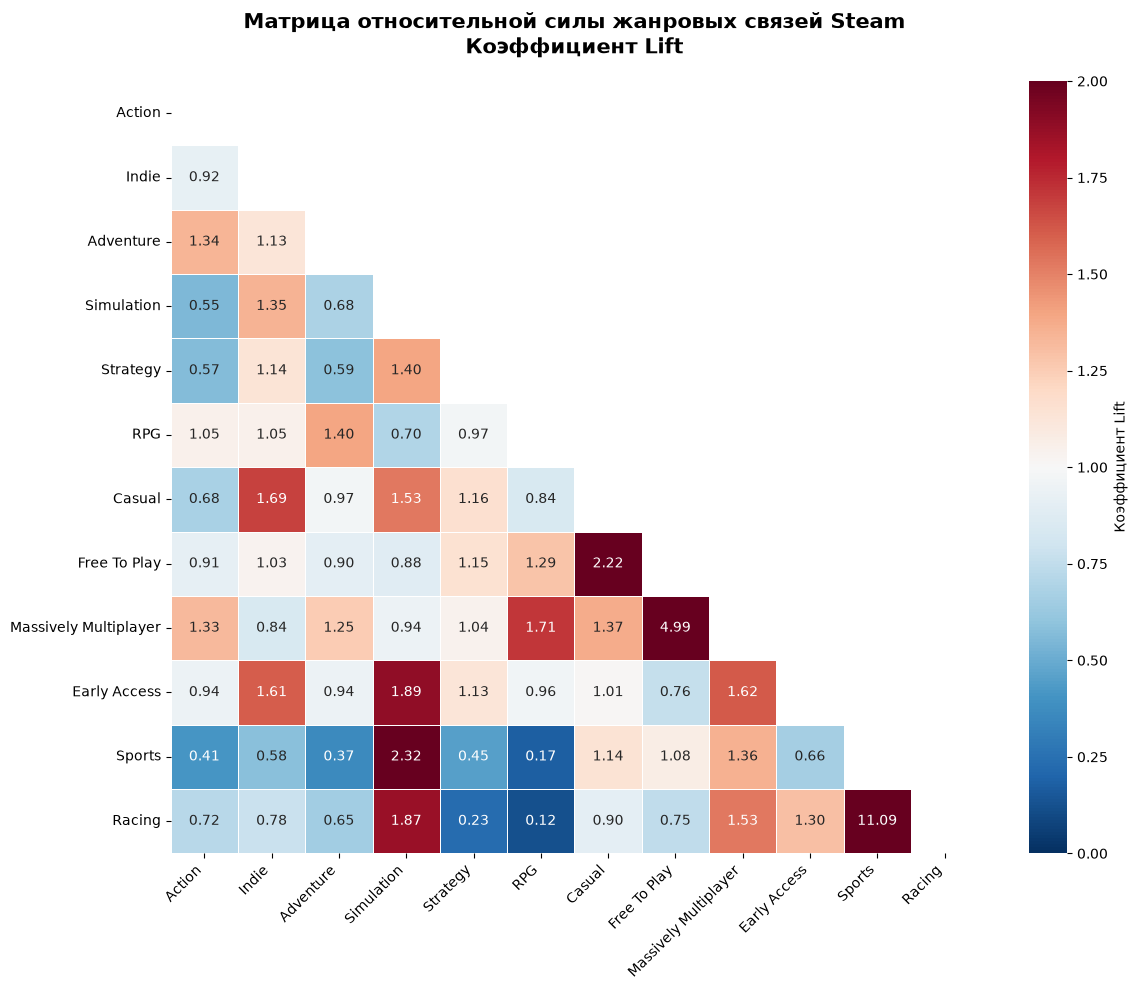

In [202]:
# Строим матрицу Lift
import seaborn as sns

# Берём жанры с >= 20 приложениями
main_genres = genre_frequency_df.loc[
    genre_frequency_df["games_count"] >= 20,
    "genre_name"
].tolist()

# Формируем симметричную матрицу Lift
lift_matrix = pd.DataFrame(
    0.0,
    index=main_genres,
    columns=main_genres
)

# Заполняем матрицу
for _, row in genre_lift_df.iterrows():

    g1 = row["genre_1"]
    g2 = row["genre_2"]

    if g1 in main_genres and g2 in main_genres:
        lift_matrix.loc[g1, g2] = row["lift"]
        lift_matrix.loc[g2, g1] = row["lift"]

# Диагональ: жанр с самим собой не анализируем
lift_matrix = lift_matrix.astype(float)

# Скрываем верхнюю половину
mask = np.triu(
    np.ones(lift_matrix.shape, dtype=bool),
    k=0
)

fig, ax = plt.subplots(figsize=(12, 10))

sns.heatmap(
    lift_matrix,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=1,
    vmin=0,
    vmax=2,
    linewidths=0.5,
    linecolor="white",
    cbar_kws={
        "label": "Коэффициент Lift"
    },
    ax=ax
)

ax.set_title(
    "Матрица относительной силы жанровых связей Steam\n"
    "Коэффициент Lift",
    fontsize=15,
    fontweight="bold",
    pad=20
)

ax.set_xlabel("")
ax.set_ylabel("")

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()

plt.savefig(
    figures_dir / "steam_genre_lift_heatmap.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

In [203]:
# Сохраним результаты 

output_dir = Path("data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

# Все 92 сочетания
genre_lift_df.to_csv(
    output_dir / "steam_genre_lift_all.csv",
    index=False,
    encoding="utf-8-sig"
)

# Сочетания после фильтрации
genre_lift_filtered.to_csv(
    output_dir / "steam_genre_lift_filtered.csv",
    index=False,
    encoding="utf-8-sig"
)

# Матрица Lift
lift_matrix.to_csv(
    output_dir / "steam_genre_lift_matrix.csv",
    encoding="utf-8-sig"
)

print("Анализ Lift завершён.")
print("Результаты сохранены в:", output_dir.resolve())

Анализ Lift завершён.
Результаты сохранены в: C:\Users\truni\OneDrive\Рабочий стол\LifeStyle\_Иннополис\_1 - Attestation\data\processed


# Анализ категорий игр Steam



In [204]:
# Проверяем данные категорий
# В нашей базе уже имеется таблица steam_app_categories, содержащая 20 689 записей для 1997 приложений.

# Структура таблицы категорий
display(con.execute("""
    DESCRIBE steam_app_categories
""").df())

# Первые десять записей
display(con.execute("""
    SELECT *
    FROM steam_app_categories
    LIMIT 10
""").df())

,column_name,column_type,null,key,default,extra
0,app_id,INTEGER,NO,PRI,None,None
1,category_id,INTEGER,NO,PRI,None,None
2,category_name,VARCHAR,YES,NaN,None,None


,app_id,category_id,category_name
0,570,1,Multi-player
1,570,9,Co-op
2,570,29,Steam Trading Cards
3,570,30,Steam Workshop
4,570,40,SteamVR Collectibles
5,570,35,In-App Purchases
6,570,67,Camera Comfort
7,570,66,Color Alternatives
8,570,68,Custom Volume Controls
9,570,8,Valve Anti-Cheat enabled


In [205]:
# Проверяем полноту данных
# Посчитаем количество уникальных категорий, приложений с разметкой и без неё, а также среднее количество категорий на приложение.

categories_quality_df = con.execute("""
    WITH category_counts AS (
        SELECT
            app_id,
            COUNT(DISTINCT category_name) AS categories_count
        FROM steam_app_categories
        GROUP BY app_id
    )

    SELECT
        (SELECT COUNT(*)
         FROM steam_games_analytics) AS total_apps,

        (SELECT COUNT(DISTINCT app_id)
         FROM steam_app_categories) AS apps_with_categories,

        (SELECT COUNT(DISTINCT category_name)
         FROM steam_app_categories) AS unique_categories,

        (SELECT COUNT(*)
         FROM steam_app_categories) AS total_category_records,

        ROUND(
            (SELECT AVG(categories_count)
             FROM category_counts),
            2
        ) AS avg_categories_per_app,

        (SELECT COUNT(*)
         FROM steam_games_analytics a
         WHERE NOT EXISTS (
             SELECT 1
             FROM steam_app_categories c
             WHERE c.app_id = a.app_id
         )) AS apps_without_categories
""").df()

display(categories_quality_df)

,total_apps,apps_with_categories,unique_categories,total_category_records,avg_categories_per_app,apps_without_categories
0,2000,1997,63,20689,9.98,3


In [206]:
# Создаём аналитический датафрейм

categories_df = con.execute("""
    SELECT
        c.app_id,
        c.category_name,

        a.final_name,
        a.app_type,
        a.peak_ccu,
        a.avg_daily_peak,
        a.days_observed,
        a.coverage_pct

    FROM steam_app_categories c

    INNER JOIN steam_games_analytics a
        ON c.app_id = a.app_id

    ORDER BY
        c.category_name,
        a.peak_ccu DESC
""").df()

print("Количество записей:", len(categories_df))
print("Уникальных приложений:", categories_df["app_id"].nunique())
print("Уникальных категорий:", categories_df["category_name"].nunique())

display(categories_df.head(10))

Количество записей: 20689
Уникальных приложений: 1997
Уникальных категорий: 63


,app_id,category_name,final_name,app_type,peak_ccu,avg_daily_peak,days_observed,coverage_pct
0,3393110,#category_contrast_controls,AION 2,game,397356,"261,534.92",39,39.39
1,4080220,#category_contrast_controls,EA SPORTS FC™ 27,game,95985,"72,510.63",49,49.49
2,2483190,#category_contrast_controls,Forza Horizon 6,game,40549,"23,666.63",93,93.94
3,1716740,#category_contrast_controls,Starfield,game,7069,"3,683.97",99,100.00
4,3017860,#category_contrast_controls,DOOM: The Dark Ages,game,5280,"1,280.82",99,100.00
5,2162800,#category_contrast_controls,shapez 2 - Factory,game,2691,964.02,98,98.99
6,2677660,#category_contrast_controls,Indiana Jones and the Great Circle,game,1249,435.80,98,98.99
7,637650,#category_contrast_controls,FINAL FANTASY XV WINDOWS EDITION,game,1147,554.18,99,100.00
8,1699480,#category_contrast_controls,KLETKA,game,501,172.73,94,94.95
9,1451090,#category_contrast_controls,Tactics Ogre: Reborn,game,499,280.59,99,100.00


In [207]:
# Рассчитываем распространённость категорий

category_frequency_df = con.execute("""
    SELECT
        category_name,

        COUNT(DISTINCT app_id) AS games_count,

        ROUND(
            100.0 * COUNT(DISTINCT app_id) / 2000,
            2
        ) AS share_pct

    FROM steam_app_categories

    GROUP BY category_name

    ORDER BY
        games_count DESC,
        category_name
""").df()

print(
    "Количество уникальных категорий:",
    len(category_frequency_df)
)

display(category_frequency_df)

Количество уникальных категорий: 63


,category_name,games_count,share_pct
0,Family Sharing,1821,91.05
1,Single-player,1795,89.75
2,Steam Achievements,1570,78.50
3,Steam Cloud,1309,65.45
4,Multi-player,1069,53.45
...,...,...,...
58,VR Only,10,0.50
59,VR Support,10,0.50
60,Steam Turn Notifications,9,0.45
61,#category_playable_without_vision,3,0.15


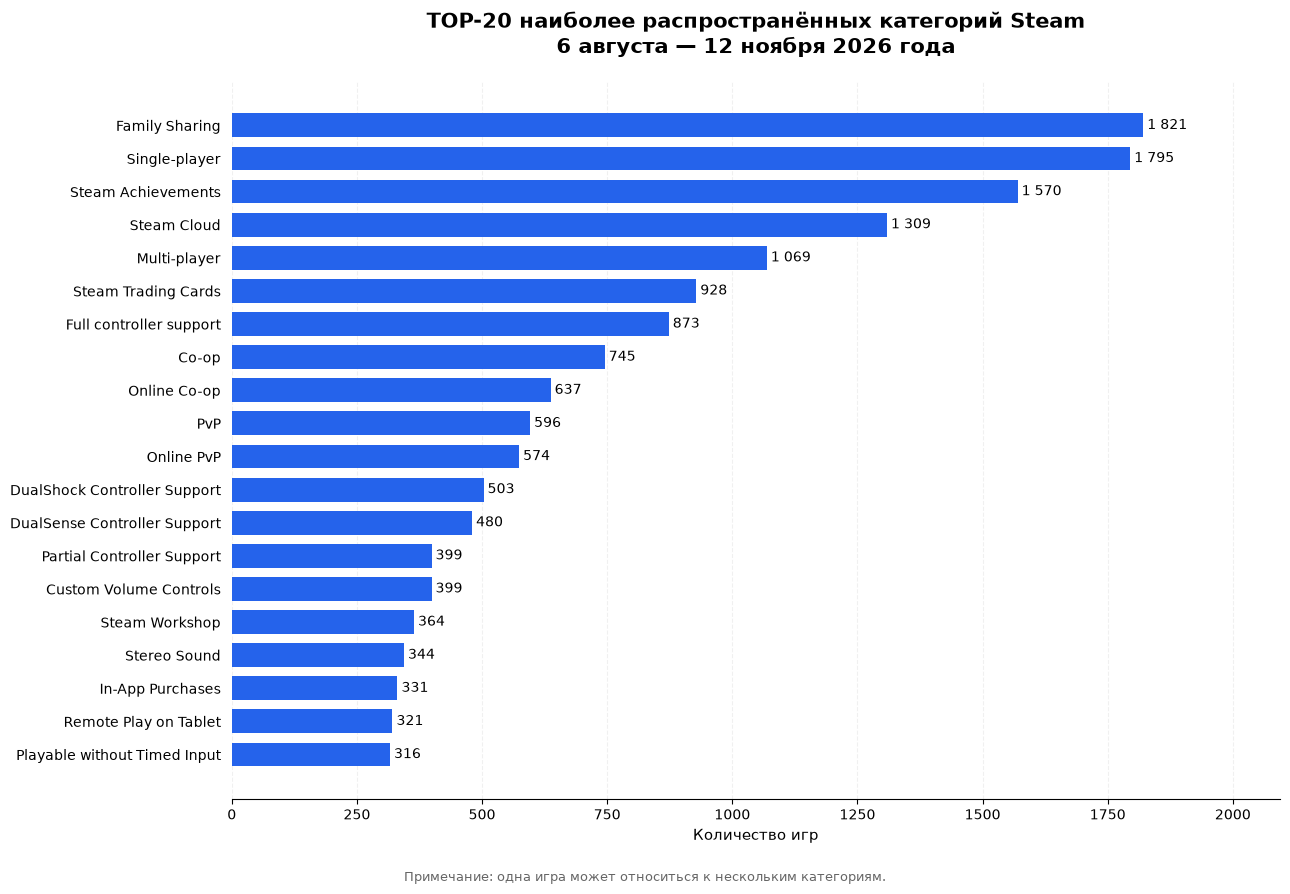

In [210]:
# Строим график распространённости категорий

import matplotlib.pyplot as plt
from pathlib import Path

# TOP-20 категорий
top20_categories = (
    category_frequency_df
    .head(20)
    .sort_values("games_count")
    .copy()
)

fig, ax = plt.subplots(figsize=(13, 9))

bars = ax.barh(
    top20_categories["category_name"],
    top20_categories["games_count"],
    color="#2563EB",
    height=0.72
)

# Подписи количества приложений
for bar, value in zip(
    bars,
    top20_categories["games_count"]
):
    ax.text(
        bar.get_width() + 8,
        bar.get_y() + bar.get_height() / 2,
        f"{value:,}".replace(",", " "),
        va="center",
        fontsize=10
    )

ax.set_title(
    "TOP-20 наиболее распространённых категорий Steam\n"
    "6 августа — 12 ноября 2026 года",
    fontsize=15,
    fontweight="bold",
    pad=20
)

ax.set_xlabel(
    "Количество игр",
    fontsize=11
)

ax.set_ylabel("")

ax.set_xlim(
    0,
    top20_categories["games_count"].max() * 1.15
)

ax.grid(
    axis="x",
    linestyle="--",
    alpha=0.18
)

ax.set_axisbelow(True)

for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)

ax.tick_params(
    axis="y",
    length=0,
    pad=8
)

fig.text(
    0.5,
    0.015,
    "Примечание: одна игра может относиться к нескольким категориям.",
    ha="center",
    fontsize=9,
    color="#666666"
)

plt.tight_layout(rect=[0, 0.04, 1, 1])

# Папка для графиков
figures_dir = Path("reports/figures")
figures_dir.mkdir(
    parents=True,
    exist_ok=True
)

plt.savefig(
    figures_dir / "steam_top20_categories.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

In [209]:
# Сохраняем первый результат

output_dir = Path("data/processed")
output_dir.mkdir(
    parents=True,
    exist_ok=True
)

category_frequency_df.to_csv(
    output_dir / "steam_category_frequency.csv",
    index=False,
    encoding="utf-8-sig"
)

print(
    "Сохранено:",
    (output_dir / "steam_category_frequency.csv").resolve()
)

Сохранено: C:\Users\truni\OneDrive\Рабочий стол\LifeStyle\_Иннополис\_1 - Attestation\data\processed\steam_category_frequency.csv


In [211]:
# Получаем рейтинг всех 2000 игр

# Одна строка на игру
games_ranked_df = con.execute("""
    SELECT
        app_id,
        peak_ccu,
        avg_daily_peak,
        coverage_pct
    FROM steam_games_analytics
""").df()

# Рейтинг по максимальному CCU
games_ranked_df = games_ranked_df.sort_values(
    ["peak_ccu", "app_id"],
    ascending=[False, True]
).reset_index(drop=True)

games_ranked_df["rank_peak"] = (
    np.arange(1, len(games_ranked_df) + 1)
)

display(games_ranked_df.head())

,app_id,peak_ccu,avg_daily_peak,coverage_pct,rank_peak
0,730,1450705,"1,238,948.45",100.00,1
1,570,1096364,"855,789.77",100.00,2
2,4115450,832967,"611,784.64",14.14,3
3,578080,816367,"734,037.35",100.00,4
4,1867240,428219,"219,244.19",63.64,5


In [212]:
# Рассчитываем показатели по категориям через Pandas

# Объединяем категории с рейтингом
category_analysis_df = categories_df[
    ["app_id", "category_name"]
].drop_duplicates().merge(
    games_ranked_df,
    on="app_id",
    how="inner",
    validate="many_to_one"
)

# Агрегируем показатели
category_popularity_df = (
    category_analysis_df
    .groupby("category_name")
    .agg(
        games_count=("app_id", "nunique"),
        median_peak_ccu=("peak_ccu", "median"),
        mean_peak_ccu=("peak_ccu", "mean"),
        median_avg_daily_peak=("avg_daily_peak", "median"),
        top100_games=("rank_peak", lambda x: (x <= 100).sum())
    )
    .reset_index()
)

category_popularity_df["share_pct"] = (
    category_popularity_df["games_count"]
    / len(games_ranked_df) * 100
)

category_popularity_df["top100_share_pct"] = (
    category_popularity_df["top100_games"]
    / category_popularity_df["games_count"] * 100
)

# Округляем показатели
numeric_cols = [
    "median_peak_ccu",
    "mean_peak_ccu",
    "median_avg_daily_peak",
    "share_pct",
    "top100_share_pct"
]

category_popularity_df[numeric_cols] = (
    category_popularity_df[numeric_cols].round(2)
)

category_popularity_df = (
    category_popularity_df
    .sort_values("median_peak_ccu", ascending=False)
    .reset_index(drop=True)
)

display(category_popularity_df)

,category_name,games_count,median_peak_ccu,mean_peak_ccu,median_avg_daily_peak,top100_games,share_pct,top100_share_pct
0,SteamVR Collectibles,2,"548,351.50","548,351.50","427,999.78",1,0.10,50.00
1,Chat Speech-to-text,14,"34,227.50","66,683.57","13,048.36",7,0.70,50.00
2,Chat Text-to-speech,11,"21,885.00","46,964.64","9,240.53",5,0.55,45.45
3,Narrated Game Menus,21,"4,289.00","16,029.05","2,202.04",2,1.05,9.52
4,Steam Timeline,10,"4,226.00","262,433.90","2,462.48",3,0.50,30.00
...,...,...,...,...,...,...,...,...
58,Steam Leaderboards,178,636.00,"2,871.02",277.61,4,8.90,2.25
59,VR Only,10,620.00,"1,259.10",344.26,0,0.50,0.00
60,#category_contrast_controls,19,499.00,"29,208.05",251.00,3,0.95,15.79
61,Steam Turn Notifications,9,322.00,"5,937.78",155.10,1,0.45,11.11


In [214]:
# Проверяем результаты

print("Всего категорий:", len(category_popularity_df))

print("\nКатегории с наибольшей медианой CCU:")

display(
    category_popularity_df[
        category_popularity_df["games_count"] >= 20
    ][
        [
            "category_name",
            "games_count",
            "median_peak_ccu",
            "top100_games",
            "top100_share_pct"
        ]
    ].head(20)
)

Всего категорий: 63

Категории с наибольшей медианой CCU:


,category_name,games_count,median_peak_ccu,top100_games,top100_share_pct
3,Narrated Game Menus,21,"4,289.00",2,9.52
5,HDR available,105,"4,058.00",17,16.19
6,Adjustable Text Size,135,"3,000.00",24,17.78
7,Steam Input API Support,74,"2,553.00",13,17.57
8,Surround Sound,212,"2,531.00",33,15.57
9,Subtitle Options,101,"2,437.00",18,17.82
10,Camera Comfort,261,"2,024.00",36,13.79
11,Stereo Sound,344,"2,002.50",47,13.66
12,VR Supported,41,"1,623.00",4,9.76
13,Color Alternatives,169,"1,621.00",30,17.75


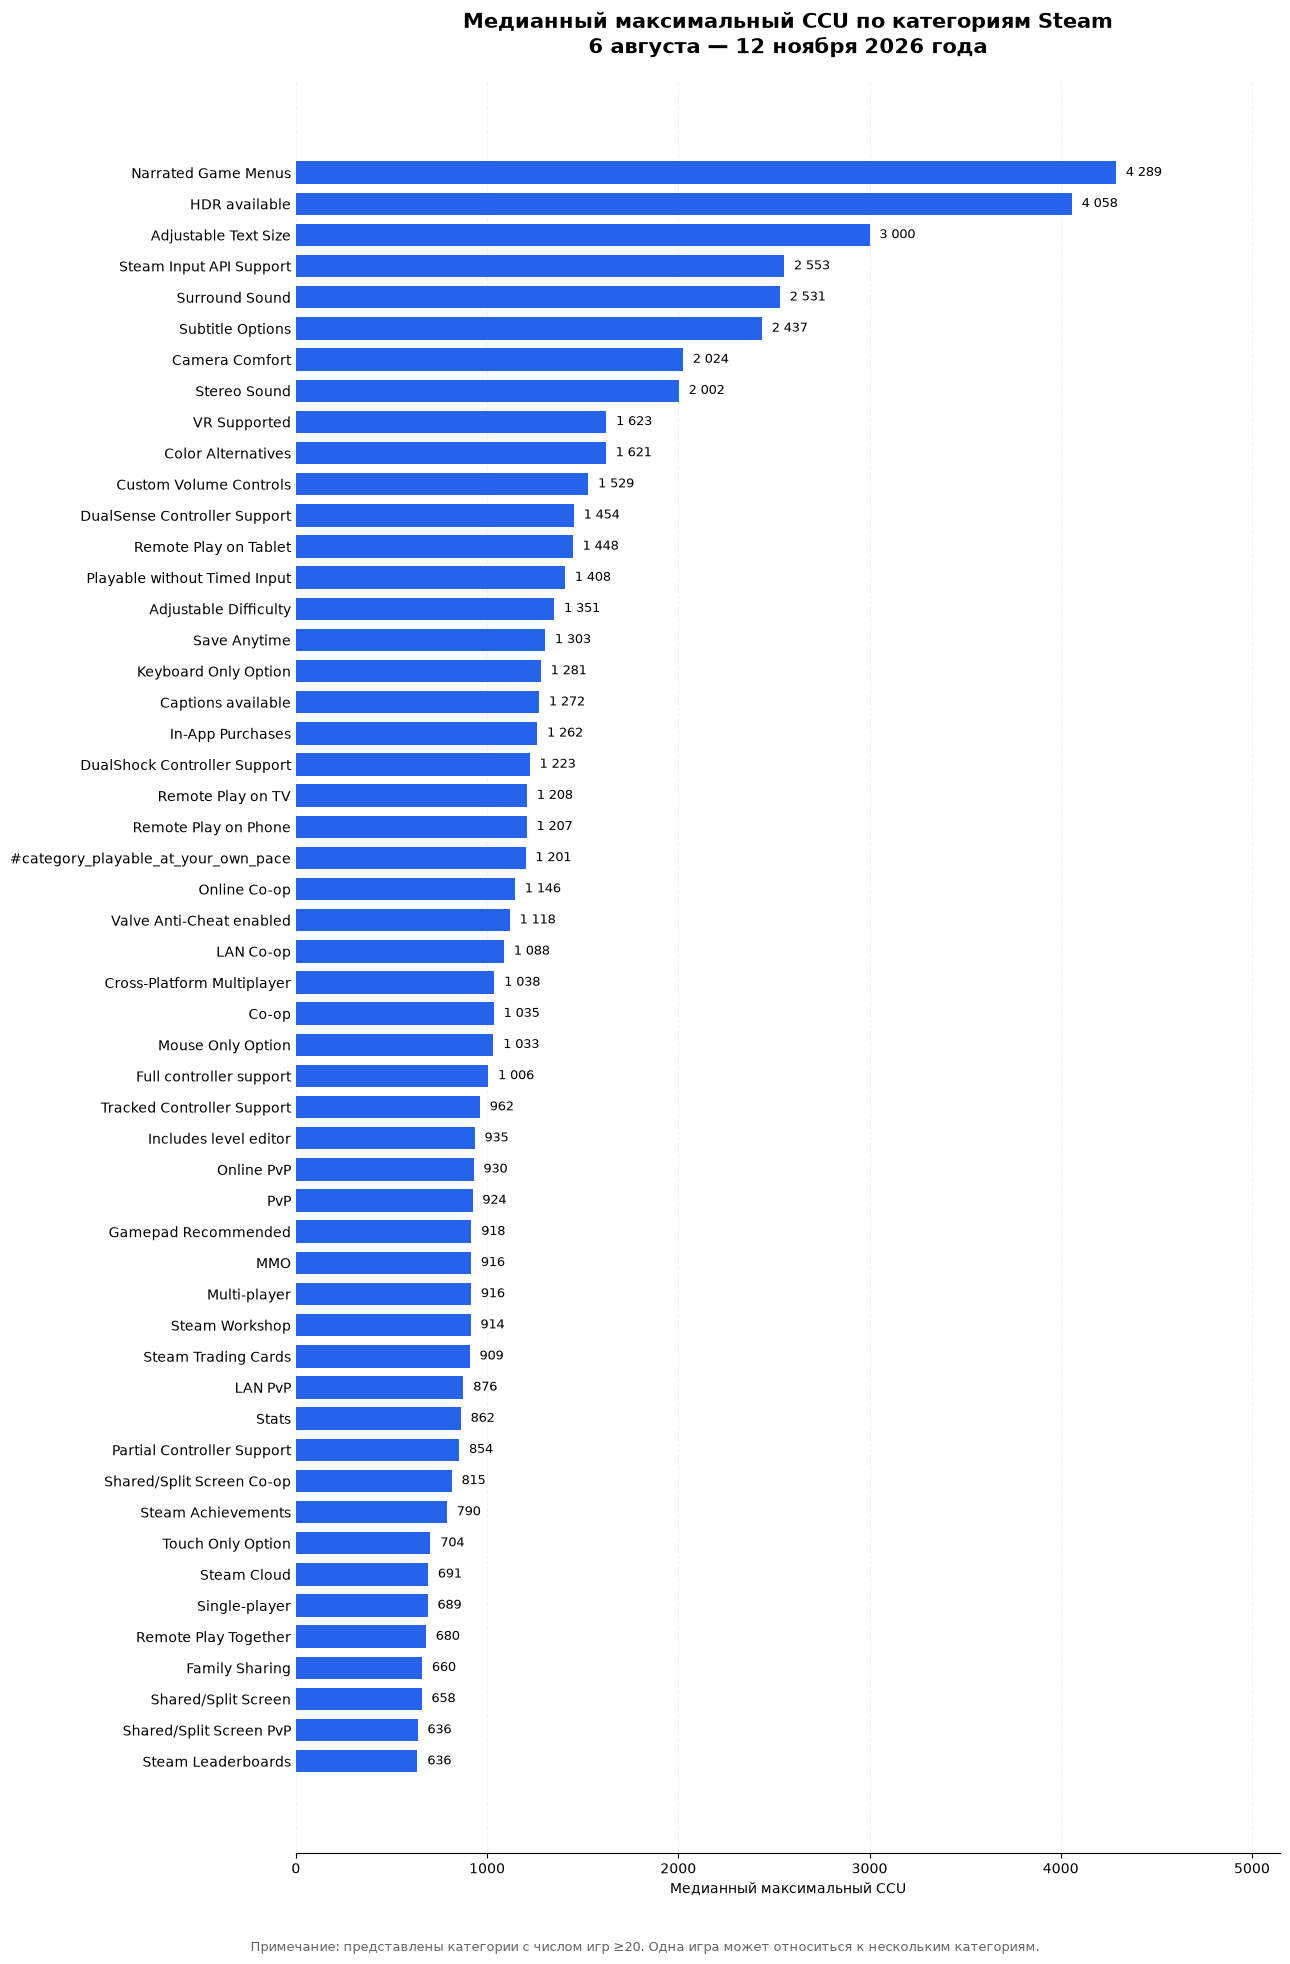

In [215]:
# График 1. Медианный CCU по категориям

import matplotlib.pyplot as plt
from pathlib import Path

# Категории с числом игр >= 20
plot_df = (
    category_popularity_df[
        category_popularity_df["games_count"] >= 20
    ]
    .sort_values("median_peak_ccu")
    .copy()
)

fig, ax = plt.subplots(
    figsize=(13, max(9, len(plot_df) * 0.38))
)

bars = ax.barh(
    plot_df["category_name"],
    plot_df["median_peak_ccu"],
    color="#2563EB",
    height=0.72
)

max_value = plot_df["median_peak_ccu"].max()

for bar, value in zip(
    bars,
    plot_df["median_peak_ccu"]
):
    ax.text(
        bar.get_width() + max_value * 0.012,
        bar.get_y() + bar.get_height() / 2,
        f"{value:,.0f}".replace(",", " "),
        va="center",
        fontsize=9
    )

ax.set_title(
    "Медианный максимальный CCU по категориям Steam\n"
    "6 августа — 12 ноября 2026 года",
    fontsize=15,
    fontweight="bold",
    pad=20
)

ax.set_xlabel("Медианный максимальный CCU")
ax.set_ylabel("")
ax.set_xlim(0, max_value * 1.2)

ax.grid(axis="x", linestyle="--", alpha=0.18)
ax.set_axisbelow(True)

for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)

ax.tick_params(axis="y", length=0)

fig.text(
    0.5, 0.01,
    "Примечание: представлены категории с числом игр ≥20. "
    "Одна игра может относиться к нескольким категориям.",
    ha="center",
    fontsize=9,
    color="#666666"
)

plt.tight_layout(rect=[0, 0.03, 1, 1])

figures_dir = Path("reports/figures")
figures_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(
    figures_dir / "steam_category_median_ccu.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

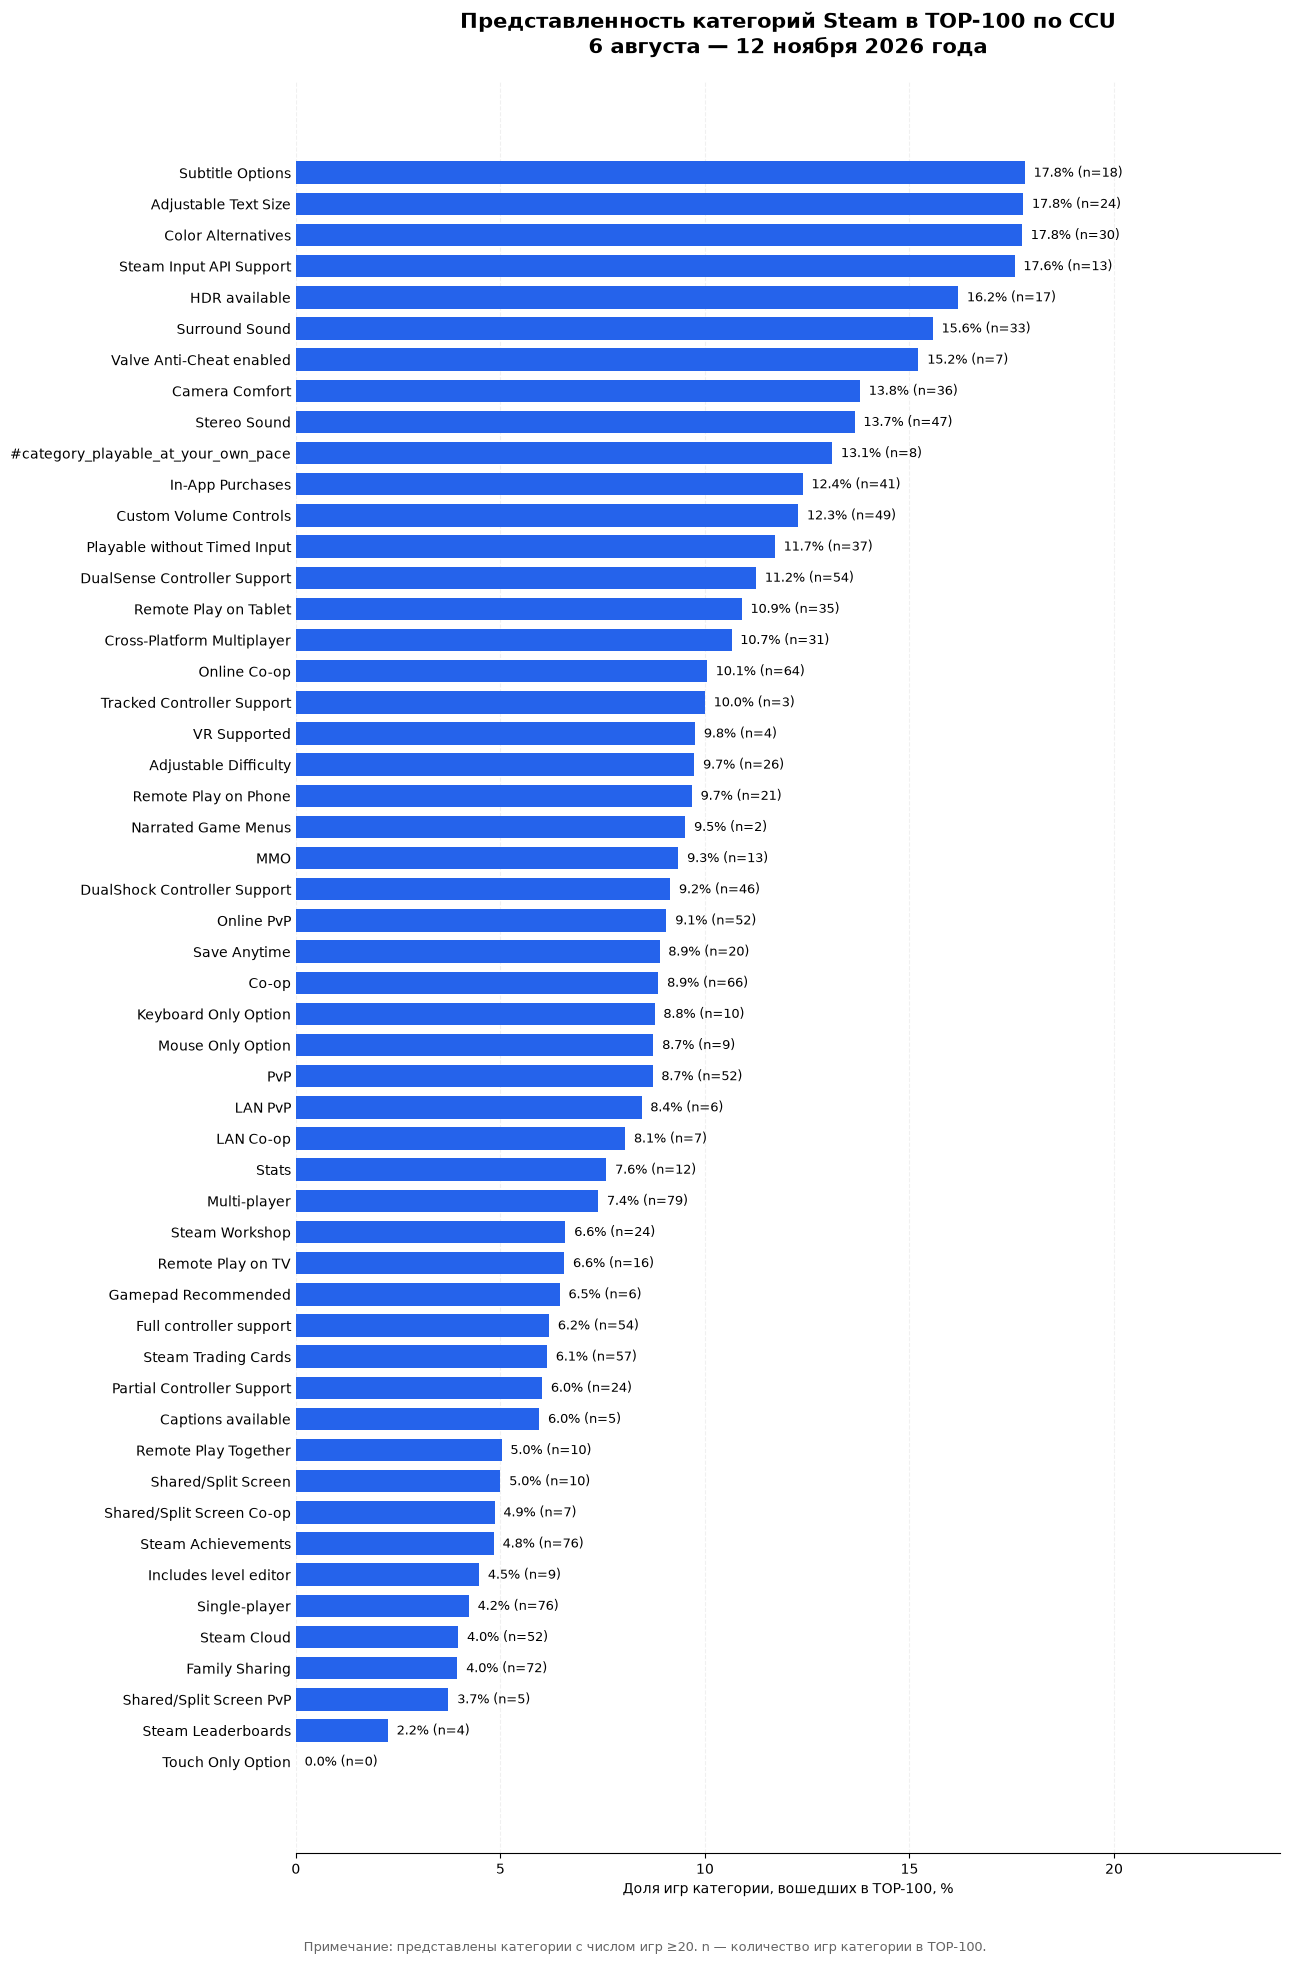

In [216]:
# График 2. Представленность категорий в TOP-100

# Сортировка по доле игр в TOP-100
plot_df = (
    category_popularity_df[
        category_popularity_df["games_count"] >= 20
    ]
    .sort_values("top100_share_pct")
    .copy()
)

fig, ax = plt.subplots(
    figsize=(13, max(9, len(plot_df) * 0.38))
)

bars = ax.barh(
    plot_df["category_name"],
    plot_df["top100_share_pct"],
    color="#2563EB",
    height=0.72
)

max_value = plot_df["top100_share_pct"].max()

for bar, (_, row) in zip(
    bars,
    plot_df.iterrows()
):
    ax.text(
        bar.get_width() + max_value * 0.012,
        bar.get_y() + bar.get_height() / 2,
        f"{row['top100_share_pct']:.1f}% "
        f"(n={row['top100_games']})",
        va="center",
        fontsize=9
    )

ax.set_title(
    "Представленность категорий Steam в TOP-100 по CCU\n"
    "6 августа — 12 ноября 2026 года",
    fontsize=15,
    fontweight="bold",
    pad=20
)

ax.set_xlabel(
    "Доля игр категории, вошедших в TOP-100, %"
)
ax.set_ylabel("")
ax.set_xlim(0, max_value * 1.35)

ax.grid(axis="x", linestyle="--", alpha=0.18)
ax.set_axisbelow(True)

for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)

ax.tick_params(axis="y", length=0)

fig.text(
    0.5, 0.01,
    "Примечание: представлены категории с числом игр ≥20. "
    "n — количество игр категории в TOP-100.",
    ha="center",
    fontsize=9,
    color="#666666"
)

plt.tight_layout(rect=[0, 0.03, 1, 1])

plt.savefig(
    figures_dir / "steam_category_top100_share.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

In [217]:
# Анализ сочетаний категорий Steam
# Формируем пары категорий
# В categories_df у нас уже есть идентификаторы игр и названия категорий. Создадим пары с помощью объединения таблицы самой с собой.

# Берём уникальные категории каждой игры
game_categories = (
    categories_df[["app_id", "category_name"]]
    .dropna(subset=["category_name"])
    .drop_duplicates()
    .copy()
)

# Объединяем категории внутри одной игры
category_pairs = game_categories.merge(
    game_categories,
    on="app_id",
    how="inner",
    suffixes=("_1", "_2")
)

# Исключаем одинаковые категории и зеркальные пары
category_pairs = category_pairs[
    category_pairs["category_name_1"]
    < category_pairs["category_name_2"]
].copy()

print("Всего записей сочетаний:", len(category_pairs))

display(category_pairs.head(10))

Всего записей сочетаний: 115422


,app_id,category_name_1,category_name_2
1,3393110,#category_contrast_controls,Adjustable Text Size
2,3393110,#category_contrast_controls,Camera Comfort
3,3393110,#category_contrast_controls,Co-op
4,3393110,#category_contrast_controls,Color Alternatives
5,3393110,#category_contrast_controls,Custom Volume Controls
6,3393110,#category_contrast_controls,Family Sharing
7,3393110,#category_contrast_controls,In-App Purchases
8,3393110,#category_contrast_controls,MMO
9,3393110,#category_contrast_controls,Multi-player
10,3393110,#category_contrast_controls,Online Co-op


In [218]:
# Рассчитываем распространённость сочетаний

category_pairs_frequency_df = (
    category_pairs
    .groupby(
        ["category_name_1", "category_name_2"],
        as_index=False
    )
    .agg(
        games_count=("app_id", "nunique")
    )
)

category_pairs_frequency_df["share_pct"] = (
    category_pairs_frequency_df["games_count"]
    / 2000 * 100
).round(2)

category_pairs_frequency_df = (
    category_pairs_frequency_df
    .sort_values(
        ["games_count", "category_name_1", "category_name_2"],
        ascending=[False, True, True]
    )
    .reset_index(drop=True)
)

category_pairs_frequency_df["category_pair"] = (
    category_pairs_frequency_df["category_name_1"]
    + " + "
    + category_pairs_frequency_df["category_name_2"]
)

print(
    "Уникальных сочетаний категорий:",
    len(category_pairs_frequency_df)
)

display(category_pairs_frequency_df.head(20))

Уникальных сочетаний категорий: 1704


,category_name_1,category_name_2,games_count,share_pct,category_pair
0,Family Sharing,Single-player,1670,83.50,Family Sharing + Single-player
1,Single-player,Steam Achievements,1452,72.60,Single-player + Steam Achievements
2,Family Sharing,Steam Achievements,1442,72.10,Family Sharing + Steam Achievements
3,Family Sharing,Steam Cloud,1287,64.35,Family Sharing + Steam Cloud
4,Single-player,Steam Cloud,1270,63.50,Single-player + Steam Cloud
5,Steam Achievements,Steam Cloud,1163,58.15,Steam Achievements + Steam Cloud
6,Family Sharing,Multi-player,926,46.30,Family Sharing + Multi-player
7,Multi-player,Single-player,873,43.65,Multi-player + Single-player
8,Family Sharing,Steam Trading Cards,858,42.90,Family Sharing + Steam Trading Cards
9,Steam Achievements,Steam Trading Cards,855,42.75,Steam Achievements + Steam Trading Cards


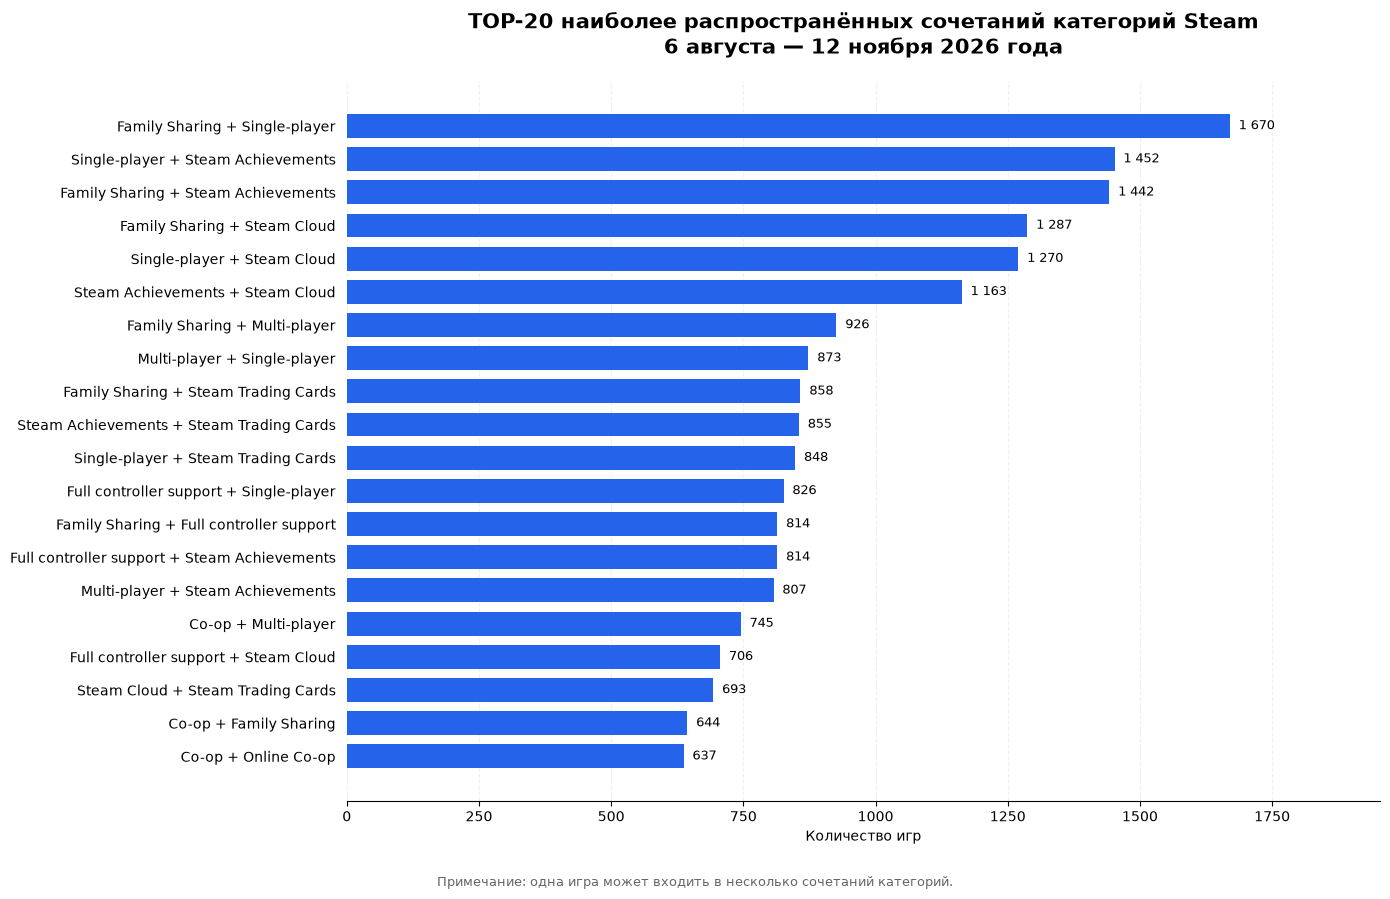

In [219]:
# Строим TOP-20 сочетаний категорий

top20_category_pairs = (
    category_pairs_frequency_df
    .head(20)
    .sort_values("games_count")
    .copy()
)

fig, ax = plt.subplots(figsize=(14, 9))

bars = ax.barh(
    top20_category_pairs["category_pair"],
    top20_category_pairs["games_count"],
    color="#2563EB",
    height=0.72
)

max_value = top20_category_pairs["games_count"].max()

for bar, value in zip(
    bars,
    top20_category_pairs["games_count"]
):
    ax.text(
        bar.get_width() + max_value * 0.01,
        bar.get_y() + bar.get_height() / 2,
        f"{value:,}".replace(",", " "),
        va="center",
        fontsize=9
    )

ax.set_title(
    "TOP-20 наиболее распространённых сочетаний категорий Steam\n"
    "6 августа — 12 ноября 2026 года",
    fontsize=15,
    fontweight="bold",
    pad=20
)

ax.set_xlabel("Количество игр")
ax.set_ylabel("")
ax.set_xlim(0, max_value * 1.17)

ax.grid(axis="x", linestyle="--", alpha=0.18)
ax.set_axisbelow(True)

for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)

ax.tick_params(axis="y", length=0, pad=8)

fig.text(
    0.5, 0.01,
    "Примечание: одна игра может входить в несколько сочетаний категорий.",
    ha="center",
    fontsize=9,
    color="#666666"
)

plt.tight_layout(rect=[0, 0.04, 1, 1])

figures_dir = Path("reports/figures")
figures_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(
    figures_dir / "steam_top20_category_pairs.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

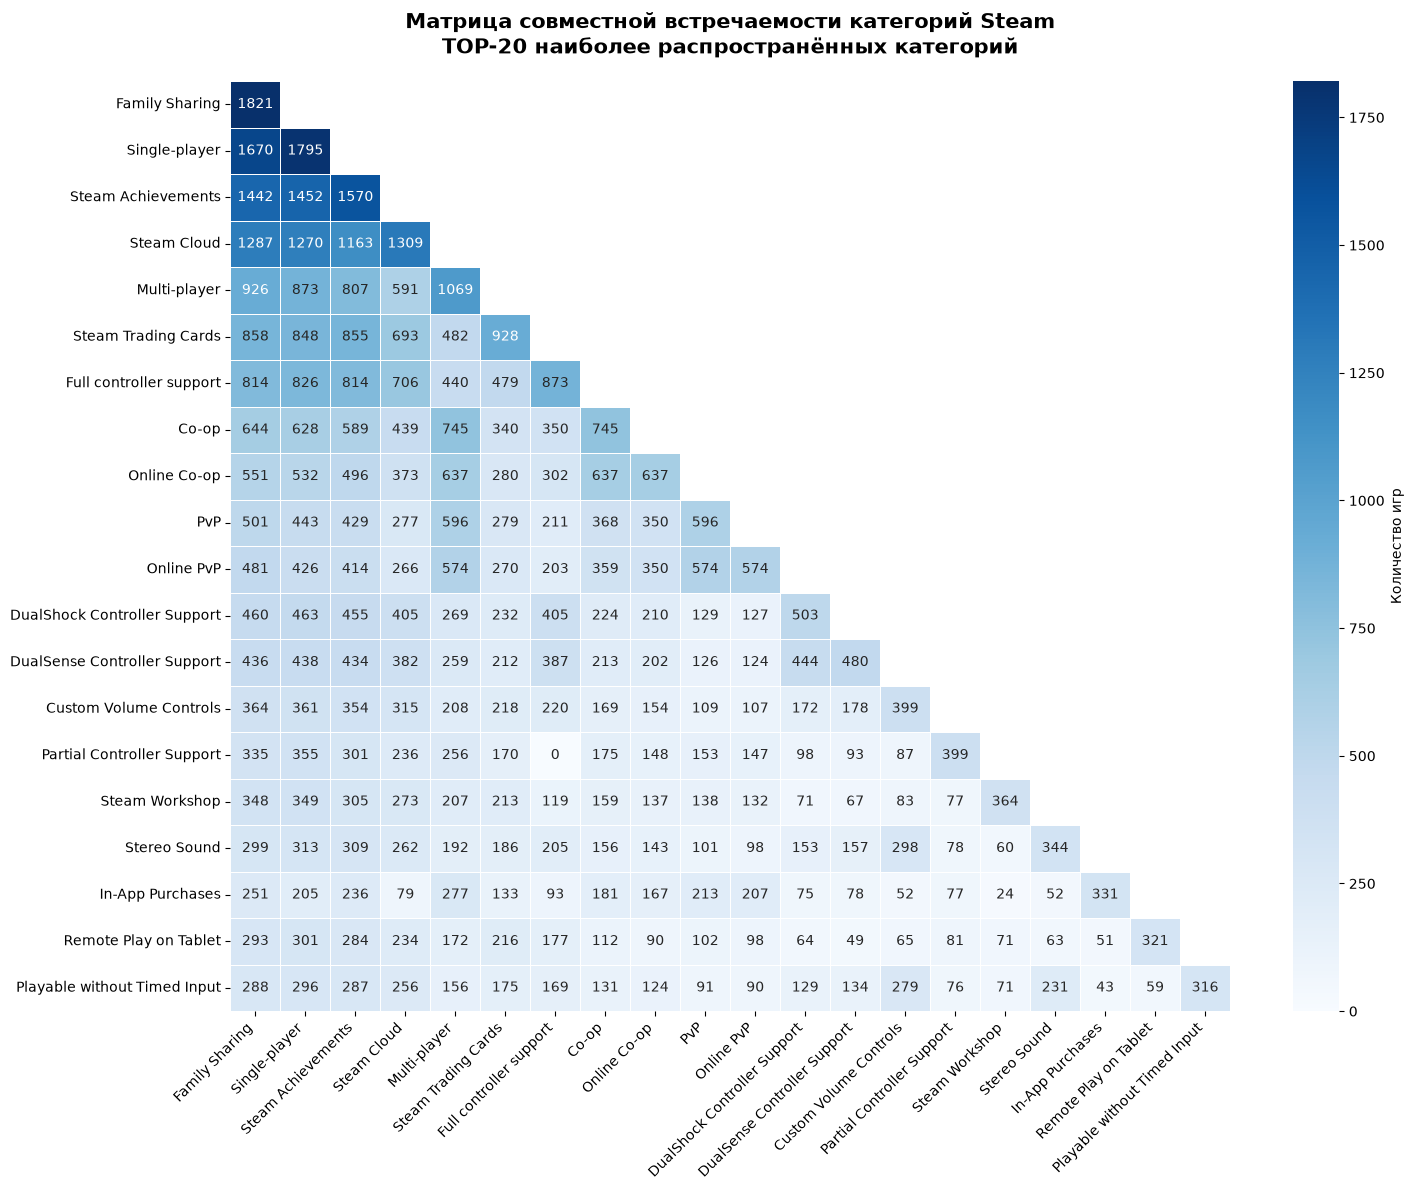

In [220]:
# Матрица совместной встречаемости категорий

import seaborn as sns
import numpy as np

# Выбираем 20 наиболее распространённых категорий
top_categories = (
    category_frequency_df
    .head(20)["category_name"]
    .tolist()
)

# Бинарная матрица:
# строки — игры, столбцы — категории
category_binary = pd.crosstab(
    game_categories["app_id"],
    game_categories["category_name"]
)

# Оставляем выбранные категории
category_binary = category_binary.reindex(
    columns=top_categories,
    fill_value=0
)

# Совместная встречаемость
cooccurrence_matrix = (
    category_binary.T @ category_binary
)

# Маска верхнего треугольника
mask = np.triu(
    np.ones(
        cooccurrence_matrix.shape,
        dtype=bool
    ),
    k=1
)

fig, ax = plt.subplots(figsize=(15, 12))

sns.heatmap(
    cooccurrence_matrix,
    mask=mask,
    annot=True,
    fmt="d",
    cmap="Blues",
    linewidths=0.5,
    linecolor="white",
    cbar_kws={
        "label": "Количество игр"
    },
    ax=ax
)

ax.set_title(
    "Матрица совместной встречаемости категорий Steam\n"
    "TOP-20 наиболее распространённых категорий",
    fontsize=15,
    fontweight="bold",
    pad=20
)

ax.set_xlabel("")
ax.set_ylabel("")

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()

plt.savefig(
    figures_dir / "steam_category_cooccurrence.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

In [221]:
# Сохраняем результаты

output_dir = Path("data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

category_pairs_frequency_df.to_csv(
    output_dir / "steam_category_pairs_frequency.csv",
    index=False,
    encoding="utf-8-sig"
)

print(
    "Сохранено сочетаний:",
    len(category_pairs_frequency_df)
)

Сохранено сочетаний: 1704


In [223]:
# Lift для категорий

# Количество игр в исследовании
N = 2000

# Частоты отдельных категорий
category_counts = (
    category_frequency_df
    .set_index("category_name")["games_count"]
)

# Копируем таблицу сочетаний
category_lift_df = category_pairs_frequency_df.copy()

# Частоты каждой категории в паре
category_lift_df["count_1"] = (
    category_lift_df["category_name_1"]
    .map(category_counts)
)

category_lift_df["count_2"] = (
    category_lift_df["category_name_2"]
    .map(category_counts)
)

# Рассчитываем Lift
category_lift_df["lift"] = (
    category_lift_df["games_count"] * N
    / (
        category_lift_df["count_1"]
        * category_lift_df["count_2"]
    )
)

category_lift_df["lift"] = (
    category_lift_df["lift"].round(3)
)

display(
    category_lift_df[
        [
            "category_pair",
            "games_count",
            "share_pct",
            "lift"
        ]
    ].head(20)
)

,category_pair,games_count,share_pct,lift
0,Family Sharing + Single-player,1670,83.50,1.02
1,Single-player + Steam Achievements,1452,72.60,1.03
2,Family Sharing + Steam Achievements,1442,72.10,1.01
3,Family Sharing + Steam Cloud,1287,64.35,1.08
4,Single-player + Steam Cloud,1270,63.50,1.08
5,Steam Achievements + Steam Cloud,1163,58.15,1.13
6,Family Sharing + Multi-player,926,46.30,0.95
7,Multi-player + Single-player,873,43.65,0.91
8,Family Sharing + Steam Trading Cards,858,42.90,1.01
9,Steam Achievements + Steam Trading Cards,855,42.75,1.17


Как интерпретировать коэффициент
Lift	Значение
Больше 1	Категории встречаются совместно чаще ожидаемого
Равен 1	Совместная частота соответствует независимости
Меньше 1	Категории встречаются совместно реже ожидаемого

In [224]:
# Выделяем наиболее сильные связи

# TOP-20 сочетаний с наибольшим Lift
top20_lift_df = (
    category_lift_df[
        category_lift_df["games_count"] >= 20
    ]
    .sort_values(
        ["lift", "games_count"],
        ascending=[False, False]
    )
    .head(20)
    .reset_index(drop=True)
)

display(
    top20_lift_df[
        [
            "category_pair",
            "games_count",
            "share_pct",
            "lift"
        ]
    ]
)

,category_pair,games_count,share_pct,lift
0,Mouse Only Option + Touch Only Option,27,1.35,18.08
1,LAN Co-op + LAN PvP,55,2.75,17.81
2,Shared/Split Screen + Shared/Split Screen Co-op,134,6.70,9.31
3,Remote Play Together + Shared/Split Screen Co-op,118,5.90,8.24
4,Shared/Split Screen + Shared/Split Screen PvP,110,5.50,8.21
5,Adjustable Text Size + Subtitle Options,55,2.75,8.07
6,Remote Play Together + Shared/Split Screen,159,7.95,7.99
7,Remote Play Together + Shared/Split Screen PvP,98,4.90,7.35
8,Shared/Split Screen Co-op + Shared/Split Scree...,68,3.40,7.05
9,#category_playable_at_your_own_pace + Mouse On...,22,1.10,7.00


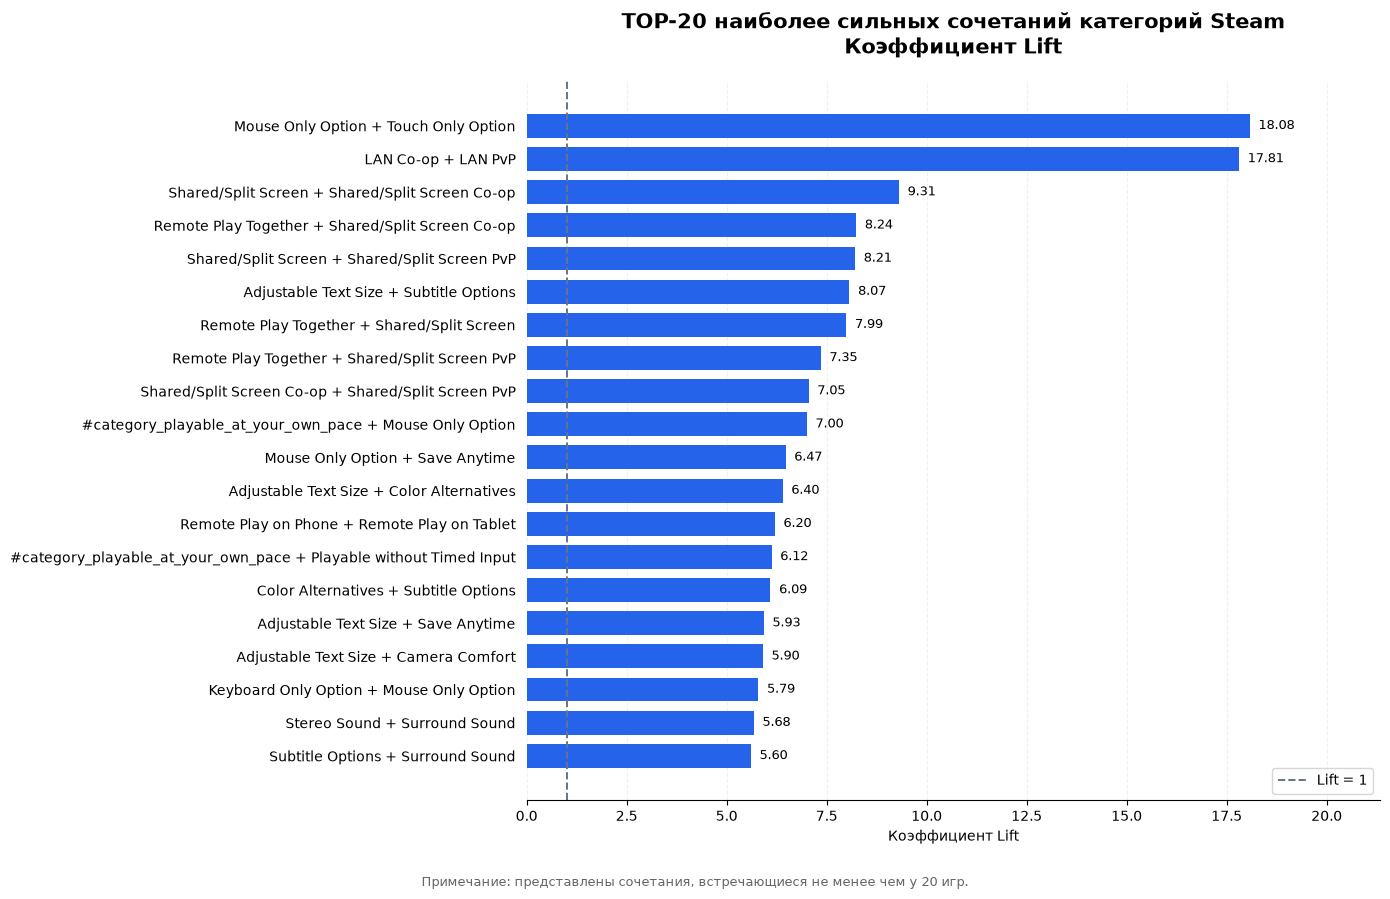

In [225]:
# изуализируем TOP-20 по Lift

plot_df = (
    top20_lift_df
    .sort_values("lift")
    .copy()
)

fig, ax = plt.subplots(figsize=(14, 9))

bars = ax.barh(
    plot_df["category_pair"],
    plot_df["lift"],
    color="#2563EB",
    height=0.72
)

max_lift = plot_df["lift"].max()

for bar, value in zip(bars, plot_df["lift"]):
    ax.text(
        bar.get_width() + max_lift * 0.012,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.2f}",
        va="center",
        fontsize=9
    )

# Уровень независимости
ax.axvline(
    1,
    color="#64748B",
    linestyle="--",
    linewidth=1.4,
    label="Lift = 1"
)

ax.set_title(
    "TOP-20 наиболее сильных сочетаний категорий Steam\n"
    "Коэффициент Lift",
    fontsize=15,
    fontweight="bold",
    pad=20
)

ax.set_xlabel("Коэффициент Lift")
ax.set_ylabel("")
ax.set_xlim(0, max_lift * 1.18)

ax.grid(axis="x", linestyle="--", alpha=0.18)
ax.set_axisbelow(True)
ax.legend(loc="lower right")

for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)

ax.tick_params(axis="y", length=0, pad=8)

fig.text(
    0.5, 0.01,
    "Примечание: представлены сочетания, встречающиеся не менее чем у 20 игр.",
    ha="center",
    fontsize=9,
    color="#666666"
)

plt.tight_layout(rect=[0, 0.04, 1, 1])

plt.savefig(
    figures_dir / "steam_top20_category_lift.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

In [226]:
# Сохраним полученные результаты 

category_lift_df.to_csv(
    output_dir / "steam_category_pairs_lift.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Сохранено сочетаний:", len(category_lift_df))

Сохранено сочетаний: 1704


# Cпециализированный анализ игровых механик

In [227]:
# # Категории, потенциально связанные с игровыми механиками

mechanic_groups = {
    "Социальное взаимодействие": [
        "Multi-player",
        "Co-op",
        "Online Co-op",
        "PvP",
        "Online PvP",
        "MMO",
        "Cross-Platform Multiplayer"
    ],
    "Достижения и прогресс": [
        "Steam Achievements",
        "Stats",
        "Steam Leaderboards"
    ],
    "Коллекционирование": [
        "Steam Trading Cards"
    ],
    "Творчество": [
        "Steam Workshop",
        "Includes level editor"
    ],
    "Монетизация": [
        "In-App Purchases"
    ]
}

mechanic_categories = [
    category
    for categories in mechanic_groups.values()
    for category in categories
]

print("Выбрано категорий:", len(mechanic_categories))

Выбрано категорий: 14


In [228]:
# Проверяем представленность выбранных категорий

mechanic_frequency_df = (
    category_frequency_df[
        category_frequency_df["category_name"].isin(
            mechanic_categories
        )
    ]
    .copy()
)

# Добавляем исследовательскую группу
category_to_group = {
    category: group
    for group, categories in mechanic_groups.items()
    for category in categories
}

mechanic_frequency_df["mechanic_group"] = (
    mechanic_frequency_df["category_name"]
    .map(category_to_group)
)

mechanic_frequency_df = (
    mechanic_frequency_df
    .sort_values("games_count", ascending=False)
    .reset_index(drop=True)
)

display(mechanic_frequency_df)

print(
    "Найдено категорий:",
    mechanic_frequency_df["category_name"].nunique()
)

print(
    "Отсутствуют:",
    set(mechanic_categories)
    - set(mechanic_frequency_df["category_name"])
)

,category_name,games_count,share_pct,mechanic_group
0,Steam Achievements,1570,78.50,Достижения и прогресс
1,Multi-player,1069,53.45,Социальное взаимодействие
2,Steam Trading Cards,928,46.40,Коллекционирование
3,Co-op,745,37.25,Социальное взаимодействие
4,Online Co-op,637,31.85,Социальное взаимодействие
5,PvP,596,29.80,Социальное взаимодействие
6,Online PvP,574,28.70,Социальное взаимодействие
7,Steam Workshop,364,18.20,Творчество
8,In-App Purchases,331,16.55,Монетизация
9,Cross-Platform Multiplayer,291,14.55,Социальное взаимодействие


Найдено категорий: 14
Отсутствуют: set()


In [229]:
# Рассчитываем Lift для игровых механик

mechanic_lift_df = (
    category_lift_df[
        category_lift_df["category_name_1"].isin(
            mechanic_categories
        )
        &
        category_lift_df["category_name_2"].isin(
            mechanic_categories
        )
    ]
    .copy()
)

# Для основного анализа оставляем пары,
# встречающиеся минимум у 20 игр
mechanic_lift_df = (
    mechanic_lift_df[
        mechanic_lift_df["games_count"] >= 20
    ]
    .sort_values(
        ["lift", "games_count"],
        ascending=[False, False]
    )
    .reset_index(drop=True)
)

display(
    mechanic_lift_df[
        [
            "category_pair",
            "games_count",
            "share_pct",
            "lift"
        ]
    ].head(30)
)

print(
    "Количество сочетаний:",
    len(mechanic_lift_df)
)

,category_pair,games_count,share_pct,lift
0,In-App Purchases + MMO,101,5.05,4.39
1,Stats + Steam Leaderboards,56,2.80,3.98
2,Includes level editor + Steam Workshop,137,6.85,3.75
3,Online PvP + PvP,574,28.70,3.36
4,Co-op + Online Co-op,637,31.85,2.69
5,Includes level editor + Stats,41,2.05,2.58
6,MMO + PvP,105,5.25,2.54
7,MMO + Online PvP,101,5.05,2.53
8,Cross-Platform Multiplayer + In-App Purchases,113,5.65,2.35
9,Cross-Platform Multiplayer + Online PvP,190,9.50,2.27


Количество сочетаний: 85


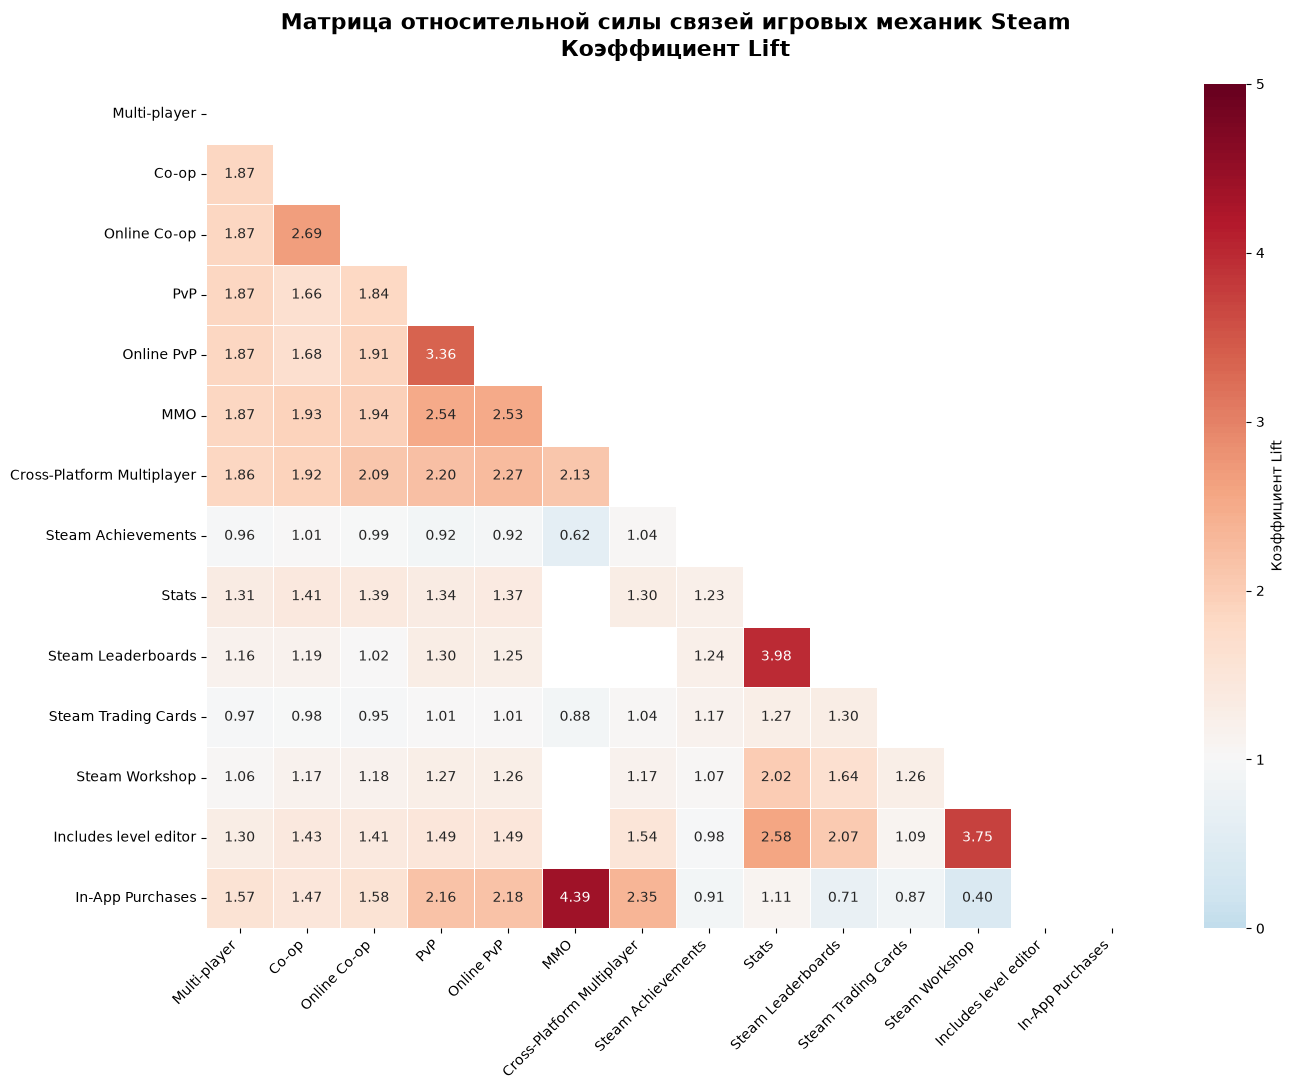

In [230]:
# Строим специализированную матрицу Lift

# Формируем квадратную матрицу
lift_matrix = pd.DataFrame(
    np.nan,
    index=mechanic_categories,
    columns=mechanic_categories,
    dtype=float
)

# Заполняем значениями Lift
for _, row in mechanic_lift_df.iterrows():

    c1 = row["category_name_1"]
    c2 = row["category_name_2"]

    lift_matrix.loc[c1, c2] = row["lift"]
    lift_matrix.loc[c2, c1] = row["lift"]

# Маска для верхней половины и диагонали
mask = np.triu(
    np.ones(lift_matrix.shape, dtype=bool),
    k=0
)

fig, ax = plt.subplots(figsize=(14, 11))

sns.heatmap(
    lift_matrix,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=1,
    vmin=0,
    vmax=5,
    linewidths=0.6,
    linecolor="white",
    cbar_kws={"label": "Коэффициент Lift"},
    ax=ax
)

ax.set_title(
    "Матрица относительной силы связей игровых механик Steam\n"
    "Коэффициент Lift",
    fontsize=16,
    fontweight="bold",
    pad=20
)

ax.set_xlabel("")
ax.set_ylabel("")

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

In [231]:
# Выделяем межгрупповые связи

mechanic_cross_group_df = mechanic_lift_df.copy()

mechanic_cross_group_df["group_1"] = (
    mechanic_cross_group_df["category_name_1"]
    .map(category_to_group)
)

mechanic_cross_group_df["group_2"] = (
    mechanic_cross_group_df["category_name_2"]
    .map(category_to_group)
)

# Только сочетания из разных групп
mechanic_cross_group_df = (
    mechanic_cross_group_df[
        mechanic_cross_group_df["group_1"]
        != mechanic_cross_group_df["group_2"]
    ]
    .sort_values(
        ["lift", "games_count"],
        ascending=[False, False]
    )
    .reset_index(drop=True)
)

display(
    mechanic_cross_group_df[
        [
            "category_pair",
            "group_1",
            "group_2",
            "games_count",
            "lift"
        ]
    ].head(20)
)


,category_pair,group_1,group_2,games_count,lift
0,In-App Purchases + MMO,Монетизация,Социальное взаимодействие,101,4.39
1,Includes level editor + Stats,Творчество,Достижения и прогресс,41,2.58
2,Cross-Platform Multiplayer + In-App Purchases,Социальное взаимодействие,Монетизация,113,2.35
3,In-App Purchases + Online PvP,Монетизация,Социальное взаимодействие,207,2.18
4,In-App Purchases + PvP,Монетизация,Социальное взаимодействие,213,2.16
5,Includes level editor + Steam Leaderboards,Творчество,Достижения и прогресс,37,2.07
6,Stats + Steam Workshop,Достижения и прогресс,Творчество,58,2.02
7,Steam Leaderboards + Steam Workshop,Достижения и прогресс,Творчество,53,1.64
8,In-App Purchases + Online Co-op,Монетизация,Социальное взаимодействие,167,1.58
9,In-App Purchases + Multi-player,Монетизация,Социальное взаимодействие,277,1.57


# Cвязь сочетаний категорий с пользовательской активностью

In [232]:
# Подготавливаем единый датафрейм

# Получаем данные из уже созданного аналитического VIEW
games_activity_df = con.execute("""
    SELECT
        app_id,
        final_name,
        peak_ccu,
        avg_daily_peak,
        days_observed,
        coverage_pct
    FROM steam_games_analytics
""").df()

categories_df = con.execute("""
    SELECT DISTINCT
        app_id,
        category_name
    FROM steam_app_categories
""").df()

# Формируем TOP-100 по максимальному CCU
games_activity_df["rank_peak"] = (
    games_activity_df["peak_ccu"]
    .rank(method="min", ascending=False)
)

games_activity_df["is_top100"] = (
    games_activity_df["rank_peak"] <= 100
)

print("Игр:", len(games_activity_df))
print("Категориальных записей:", len(categories_df))

Игр: 2000
Категориальных записей: 19922


In [233]:
# Рассчитываем показатели для сочетаний

# Множество app_id для каждой категории
category_sets = (
    categories_df
    .groupby("category_name")["app_id"]
    .agg(set)
    .to_dict()
)

results = []

for _, pair in mechanic_lift_df.iterrows():

    c1 = pair["category_name_1"]
    c2 = pair["category_name_2"]

    # Игры, имеющие обе категории
    pair_ids = (
        category_sets.get(c1, set())
        & category_sets.get(c2, set())
    )

    has_pair = games_activity_df["app_id"].isin(pair_ids)

    group = games_activity_df.loc[has_pair]
    other = games_activity_df.loc[~has_pair]

    if group.empty:
        continue

    results.append({
        "category_pair": pair["category_pair"],
        "games_count": len(group),
        "lift": pair["lift"],
        "median_peak_ccu": group["peak_ccu"].median(),
        "median_avg_daily_peak": group["avg_daily_peak"].median(),
        "top100_games": int(group["is_top100"].sum()),
        "top100_share_pct": round(
            group["is_top100"].mean() * 100, 2
        ),
        "other_median_peak_ccu": other["peak_ccu"].median(),
        "median_peak_ratio": (
            group["peak_ccu"].median()
            / other["peak_ccu"].median()
            if other["peak_ccu"].median() > 0
            else np.nan
        ),
        "median_coverage_pct": group["coverage_pct"].median()
    })

mechanic_activity_df = pd.DataFrame(results)

mechanic_activity_df = (
    mechanic_activity_df
    .sort_values(
        "top100_share_pct",
        ascending=False
    )
    .reset_index(drop=True)
)

display(mechanic_activity_df.head(20))

,category_pair,games_count,lift,median_peak_ccu,median_avg_daily_peak,top100_games,top100_share_pct,other_median_peak_ccu,median_peak_ratio,median_coverage_pct
0,In-App Purchases + Steam Workshop,24,0.40,"1,313.00",680.44,7,29.17,712.00,1.84,100.00
1,In-App Purchases + Online Co-op,167,1.58,"1,817.00",759.22,29,17.37,682.00,2.66,100.00
2,In-App Purchases + Stats,29,1.11,"1,031.00",649.96,5,17.24,715.00,1.44,100.00
3,Cross-Platform Multiplayer + In-App Purchases,113,2.35,"1,391.00",782.19,19,16.81,707.00,1.97,100.00
4,Cross-Platform Multiplayer + Stats,30,1.30,555.00,268.11,5,16.67,720.00,0.77,100.00
5,Co-op + In-App Purchases,181,1.47,"1,840.00",782.19,30,16.57,678.00,2.71,100.00
6,Cross-Platform Multiplayer + Steam Workshop,62,1.17,"1,203.00",609.44,10,16.13,710.50,1.69,100.00
7,In-App Purchases + Steam Trading Cards,133,0.87,"1,758.00",880.72,21,15.79,683.00,2.57,100.00
8,MMO + Online Co-op,86,1.94,974.00,557.39,13,15.12,711.00,1.37,100.00
9,In-App Purchases + Online PvP,207,2.18,"1,194.00",600.59,31,14.98,686.00,1.74,100.00


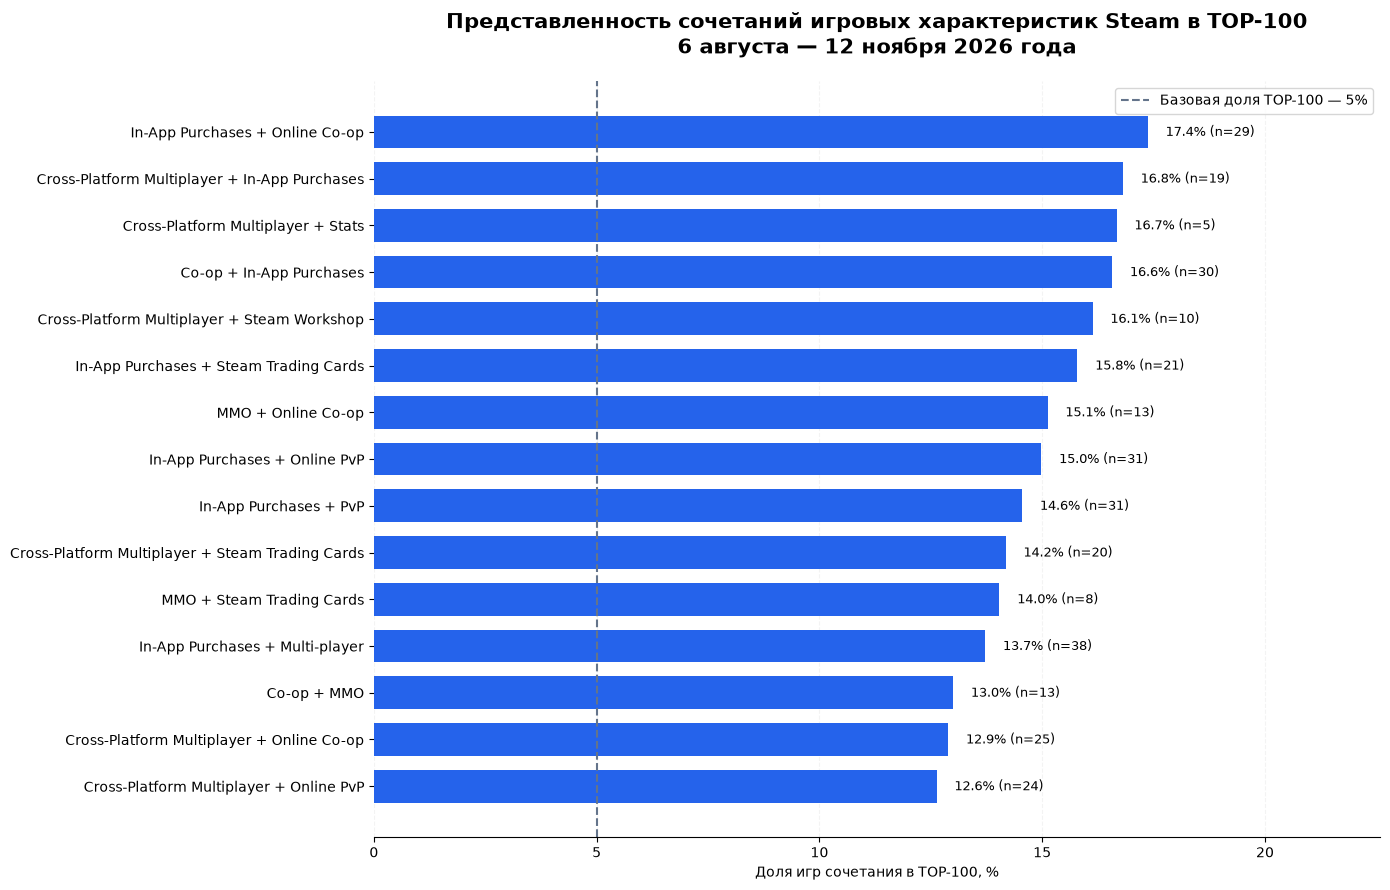

In [234]:
# Визуализируем представленность сочетаний в TOP-100

plot_df = (
    mechanic_activity_df[
        mechanic_activity_df["games_count"] >= 30
    ]
    .nlargest(15, "top100_share_pct")
    .sort_values("top100_share_pct")
)

fig, ax = plt.subplots(figsize=(14, 9))

bars = ax.barh(
    plot_df["category_pair"],
    plot_df["top100_share_pct"],
    color="#2563EB",
    height=0.7
)

for bar, (_, row) in zip(bars, plot_df.iterrows()):
    ax.text(
        bar.get_width() + 0.4,
        bar.get_y() + bar.get_height() / 2,
        f'{row["top100_share_pct"]:.1f}% '
        f'(n={row["top100_games"]})',
        va="center",
        fontsize=9
    )

# Базовая доля TOP-100 среди 2000 игр
ax.axvline(
    5,
    color="#64748B",
    linestyle="--",
    label="Базовая доля TOP-100 — 5%"
)

ax.set_xlim(
    0,
    max(plot_df["top100_share_pct"].max() * 1.3, 7)
)

ax.set_title(
    "Представленность сочетаний игровых характеристик Steam в TOP-100\n"
    "6 августа — 12 ноября 2026 года",
    fontsize=15,
    fontweight="bold",
    pad=20
)

ax.set_xlabel("Доля игр сочетания в TOP-100, %")
ax.set_ylabel("")
ax.legend()

ax.grid(axis="x", alpha=0.15, linestyle="--")
ax.set_axisbelow(True)

for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.show()

# Проверка устойчивости полученных результатов. Завершающая проверка: устойчивость результатов при покрытии ≥90%

Проверка устойчивости: повторить ключевые сравнения для игр с покрытием не менее 90%, отдельно оценив влияние неполного временного ряда.
Контроль жанров: проверить, сохраняются ли различия между группами внутри основных жанров, а не только в общей выборке.
Формирование исследовательского датафрейма: объединить рейтинг, показатели CCU, жанры, категории, бинарные признаки механик и отдельный признак is_video_game для исключения программного обеспечения.
Подготовка к Octalysis: определить, какие характеристики можно использовать как наблюдаемые признаки, а какие потребуют ручной или автоматизированной содержательной оценки.

In [235]:
# Мы сравним показатели для всех игр и для игр, у которых данные о максимальном ежедневном CCU присутствуют 
# не менее чем за 90% исследуемых дней.

import pandas as pd
import numpy as np

# 1. Получаем ежедневные максимумы CCU
ccu = con.execute("""
    SELECT app_id, date, max_players
    FROM ccu_daily
""").df()

# 2. Агрегируем показатели по играм
total_days = ccu["date"].nunique()

game_metrics = (
    ccu.groupby("app_id", as_index=False)
    .agg(
        peak_ccu=("max_players", "max"),
        avg_daily_peak=("max_players", "mean"),
        days_observed=("date", "nunique")
    )
)

game_metrics["coverage_pct"] = (
    game_metrics["days_observed"] / total_days * 100
)

# 3. Загружаем категории
categories = con.execute("""
    SELECT DISTINCT app_id, category_name
    FROM steam_app_categories
    WHERE category_name IS NOT NULL
""").df()

# 4. Выбираем интересующие нас сочетания
pairs = [
    ("In-App Purchases", "Online Co-op"),
    ("Cross-Platform Multiplayer", "In-App Purchases"),
    ("Co-op", "In-App Purchases"),
    ("In-App Purchases", "Online PvP"),
    ("In-App Purchases", "PvP"),
    ("In-App Purchases", "Multi-player"),
    ("In-App Purchases", "Steam Trading Cards")
]

category_sets = (
    categories.groupby("app_id")["category_name"]
    .agg(set)
    .to_dict()
)

def analyze_sample(df, sample_name):
    df = df.copy()

    # TOP-100 пересчитывается внутри данной выборки
    top_ids = set(
        df.nlargest(100, "peak_ccu")["app_id"]
    )

    baseline_pct = len(top_ids) / len(df) * 100

    rows = []

    for cat1, cat2 in pairs:
        has_pair = df["app_id"].map(
            lambda app_id: (
                cat1 in category_sets.get(app_id, set())
                and cat2 in category_sets.get(app_id, set())
            )
        )

        selected = df.loc[has_pair]
        others = df.loc[~has_pair]

        if selected.empty or others.empty:
            continue

        n_top = selected["app_id"].isin(top_ids).sum()
        top_share = n_top / len(selected) * 100

        median_pair = selected["peak_ccu"].median()
        median_other = others["peak_ccu"].median()

        rows.append({
            "sample": sample_name,
            "category_pair": f"{cat1} + {cat2}",
            "games_count": len(selected),
            "top100_games": n_top,
            "top100_share_pct": top_share,
            "baseline_pct": baseline_pct,
            "top100_enrichment": top_share / baseline_pct,
            "median_peak_ccu": median_pair,
            "median_peak_ratio": (
                median_pair / median_other
                if median_other > 0 else np.nan
            )
        })

    return pd.DataFrame(rows)

# 5. Сравниваем полную и ограниченную выборки
full_result = analyze_sample(
    game_metrics,
    "Все игры"
)

filtered_metrics = game_metrics.loc[
    game_metrics["coverage_pct"] >= 90
].copy()

filtered_result = analyze_sample(
    filtered_metrics,
    "Покрытие ≥90%"
)

results = pd.concat(
    [full_result, filtered_result],
    ignore_index=True
)

# 6. Сводная сравнительная таблица
comparison = results.pivot(
    index="category_pair",
    columns="sample",
    values=[
        "games_count",
        "top100_share_pct",
        "top100_enrichment",
        "median_peak_ratio"
    ]
)

print(f"Всего игр: {len(game_metrics)}")
print(f"Игр с покрытием ≥90%: {len(filtered_metrics)}")
print(f"Доля сохранённых игр: {len(filtered_metrics) / len(game_metrics):.1%}")

display(comparison.round(2))


Всего игр: 2000
Игр с покрытием ≥90%: 1912
Доля сохранённых игр: 95.6%


games_count                \
sample                                           Все игры Покрытие ≥90%   
category_pair                                                             
Co-op + In-App Purchases                           181.00        173.00   
Cross-Platform Multiplayer + In-App Purchases      113.00        109.00   
In-App Purchases + Multi-player                    277.00        266.00   
In-App Purchases + Online Co-op                    167.00        159.00   
In-App Purchases + Online PvP                      207.00        196.00   
In-App Purchases + PvP                             213.00        202.00   
In-App Purchases + Steam Trading Cards             133.00        131.00   

                                              top100_share_pct                \
sample                                                Все игры Покрытие ≥90%   
category_pair                                                                  
Co-op + In-App Purchases                                 16.57         16.18   
Cross-Platform Multiplayer + In-App Purchases            16.81         17.43   
In-App Purchases + Multi-player                          13.72         13.53   
In-App Purchases + Online Co-op                          17.37         16.35   
In-App Purchases + Online PvP                            14.98         14.29   
In-App Purchases + PvP                                   14.55         13.86   
In-App Purchases + Steam Trading Cards                   15.79         16.03   

                                              top100_enrichment                \
sample                                                 Все игры Покрытие ≥90%   
category_pair                                                                   
Co-op + In-App Purchases                                   3.31          3.09   
Cross-Platform Multiplayer + In-App Purchases              3.36          3.33   
In-App Purchases + Multi-player                            2.74          2.59   
In-App Purchases + Online Co-op                            3.47          3.13   
In-App Purchases + Online PvP                              3.00          2.73   
In-App Purchases + PvP                                     2.91          2.65   
In-App Purchases + Steam Trading Cards                     3.16          3.07   

                                              median_peak_ratio                
sample                                                 Все игры Покрытие ≥90%  
category_pair                                                                  
Co-op + In-App Purchases                                   2.71          2.39  
Cross-Platform Multiplayer + In-App Purchases              1.97          1.96  
In-App Purchases + Multi-player                            2.10          1.96  
In-App Purchases + Online Co-op                            2.66          2.36  
In-App Purchases + Online PvP                              1.74          1.67  
In-App Purchases + PvP                                     1.78          1.71  
In-App Purchases + Steam Trading Cards                     2.57          2.45

# 2 Часть проекта: Подготовка основ LLM-исследования